# Vektoranalysis

Das Notebook behandelt die Analysis von Skalar- und Vektorfeldern in der Ebene und im Raum und rechnet jede Aussage mit numpy, scipy und sympy nach: Gradient, Richtungsableitung und kritische Punkte, Divergenz und Rotation, Kurven- und Flussintegrale, Gradientenfelder und der Wirbel um ein Loch, die Sätze von Green, Gauß und Stokes, krummlinige Koordinaten, die Identitäten auf dem Gitter, Helmholtz-Zerlegung mit der FFT und die Laplace-Gleichung mit Irrfahrten. Anwendungen: Volumen im Phasenraum (Liouville) und der Hutchinson-Schätzer für die Divergenz aus kontinuierlichen Normalizing Flows, das Magnetfeld einer Leiterschleife, der quantenmechanische Wahrscheinlichkeitsstrom mit quantisierten Wirbeln und die Berry-Krümmung mit Chern-Zahlen.

Was messen Gradient, Divergenz und Rotation, warum lassen sich Integrale über ein Gebiet in Integrale über seinen Rand verwandeln, und wo braucht man das in Physik, Numerik, maschinellem Lernen und Quantenmechanik?

#### **Hintergrund**

Die Vektoranalysis ist die Analysis von **Feldern**: Funktionen, die jedem Punkt des Raums eine Zahl (Temperatur, Druck, Potential) oder einen Vektor (Geschwindigkeit, Kraft, elektrisches Feld) zuordnen. Sie hat drei Ableitungen und drei große Integralsätze. Der **Gradient** eines Skalarfelds zeigt in die Richtung des steilsten Anstiegs. Die **Divergenz** eines Vektorfelds misst, wie viel pro Volumen aus einem Punkt herausfließt (Quellen), die **Rotation**, wie stark das Feld um einen Punkt kreist (Wirbel). Die Integralsätze sagen, dass man das Integral einer Ableitung über ein Gebiet auch als Integral über seinen Rand bekommt: Was im Inneren entsteht, muss durch den Rand hinaus. Der Hauptsatz der Differential- und Integralrechnung $\int_a^bf'\,dx = f(b) - f(a)$ ist der eindimensionale Fall, die Sätze von Green, Gauß und Stokes sind seine Versionen in zwei und drei Dimensionen, und alle zusammen sind ein einziger Satz über Differentialformen.

Historisch kommt das Gebiet aus der Physik: Gauß (Elektrostatik, Gravitation), Green (1828, Potentialtheorie), Stokes und Kelvin (Strömungen), Maxwell (Elektromagnetismus, 1865) und schließlich Gibbs und Heaviside, die um 1880 die heutige Schreibweise mit $\nabla$, $\cdot$ und $\times$ einführten. Heute steckt es in jeder Feldtheorie, in der Strömungsmechanik, in der Numerik partieller Differentialgleichungen, in der Computergrafik und im maschinellen Lernen (Gradienten, Jacobi-Matrizen, die Divergenz in Normalizing Flows und Score-Modellen).

Landkarte:

| Teil | Thema | Kernaussage | Hier |
| --- | --- | --- | --- |
| Ableitungen | Gradient | $\nabla f$ steht senkrecht auf den Höhenlinien; $D_{\mathbf u}f = \nabla f\cdot\mathbf u$ ist am größten in Richtung $\nabla f$; die Hesse-Matrix ordnet kritische Punkte ein | Exp. 1 |
| | Divergenz und Rotation | Quellendichte und Wirbeldichte; gerade Stromlinien können Rotation haben, kreisförmige keine | Exp. 2 |
| Integrale | Kurvenintegrale | Bei Gradientenfeldern hängt $\int\mathbf F\cdot d\mathbf r$ nur von den Endpunkten ab; $\nabla\times\mathbf F = 0$ reicht dafür nur ohne Löcher | Exp. 3 |
| Integralsätze | Green | $\oint P\,dx + Q\,dy = \iint(\partial_xQ - \partial_yP)\,dA$; Fläche aus dem Rand (Planimeter) | Exp. 4 |
| | Gauß | $\oint\mathbf F\cdot d\mathbf A = \int\nabla\cdot\mathbf F\,dV$; der Fluss einer Punktladung ist $4\pi q$, gleich durch welche Fläche | Exp. 5 |
| | Stokes | $\oint_{\partial S}\mathbf F\cdot d\mathbf r = \iint_S(\nabla\times\mathbf F)\cdot d\mathbf A$ für jede Fläche mit diesem Rand | Exp. 6 |
| Werkzeuge | Krummlinige Koordinaten | Skalenfaktoren $h_i$; $\Delta = \partial_r^2 + \frac2r\partial_r + \frac1{r^2}\Delta_{S^2}$ | Exp. 7 |
| | Identitäten | $\nabla\times\nabla f = 0$, $\nabla\cdot(\nabla\times\mathbf A) = 0$, auch auf dem Gitter exakt | Exp. 8 |
| | Helmholtz-Zerlegung | $\mathbf v = \nabla\varphi + \nabla\times\mathbf A + $ harmonischer Teil; im Fourier-Raum eine Projektion | Exp. 9 |
| | Laplace-Gleichung | harmonische Funktionen: Mittelwerteigenschaft, Maximumprinzip, Erwartungswert von Irrfahrten | Exp. 10 |
| Anwendungen | Fluss und Volumen | $\frac d{dt}\ln J = \nabla\cdot\mathbf v$; Liouville; Hutchinson-Schätzer $\mathrm{tr}\,J = \mathbb E[\boldsymbol\varepsilon^TJ\boldsymbol\varepsilon]$ | Exp. 11 |
| | Elektromagnetismus | Biot–Savart, $\nabla\cdot\mathbf B = 0$, Ampère: $\oint\mathbf B\cdot d\mathbf l = \mu_0I$ | Exp. 12 |
| Quanten | Wahrscheinlichkeitsstrom | $\partial_t\rho + \nabla\cdot\mathbf j = 0$; Zirkulation um Nullstellen von $\psi$ ist $2\pi n$ | Exp. 13 |
| | Berry-Krümmung | ein Monopol im Parameterraum; Fluss durch eine geschlossene Fläche $= 2\pi\cdot$ Chern-Zahl | Exp. 14 |

Verwandte Notebooks: In der [Funktionentheorie](https://github.com/deltorobarba/science/blob/main/maths/complexanalysis.ipynb) sind die Cauchy–Riemann-Gleichungen die Aussage, dass $(u, -v)$ quellen- und wirbelfrei ist, und der Satz von Cauchy folgt aus dem Satz von Green. Allgemeine Koordinaten, Metrik und kovariante Ableitung stehen in [Tensor Analysis on Manifolds](https://github.com/deltorobarba/science/blob/main/maths/tensoranalysis.ipynb), Wärmeleitungs-, Wellen- und Schrödinger-Gleichung in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb), die geometrische Phase auf der Bloch-Kugel in [Projektive Geometrie](https://github.com/deltorobarba/science/blob/main/maths/projectivegeometry.ipynb) und Benchmark-Funktionen mit Gradienten und Hesse-Matrizen in [Testfunktionen](https://github.com/deltorobarba/science/blob/main/maths/testfunctions.ipynb).

#### **Theorie**

##### *1. Felder und der Gradient*

Ein **Skalarfeld** ist eine Funktion $f:\mathbb R^n\to\mathbb R$, ein **Vektorfeld** eine Funktion $\mathbf F:\mathbb R^n\to\mathbb R^n$. Mit dem Nabla-Operator $\nabla = (\partial_x, \partial_y, \partial_z)$ ist der **Gradient** $\nabla f = (\partial_xf, \partial_yf, \partial_zf)$. Die **Richtungsableitung** in Richtung eines Einheitsvektors $\mathbf u$ ist
$$D_{\mathbf u}f = \lim_{h\to0}\frac{f(\mathbf x + h\mathbf u) - f(\mathbf x)}h = \nabla f\cdot\mathbf u = \vert\nabla f\vert\cos\alpha .$$
Sie ist am größten, wenn $\mathbf u$ in Richtung $\nabla f$ zeigt (Wert $\vert\nabla f\vert$), und null senkrecht dazu: $\nabla f$ steht senkrecht auf den **Höhenlinien** (Niveaumengen) $f = c$. Die Ableitung eines Vektorfelds ist die **Jacobi-Matrix** $(D\mathbf F)_{ij} = \partial_jF_i$, die zweite Ableitung eines Skalarfelds die symmetrische **Hesse-Matrix** $H_{ij} = \partial_i\partial_jf$. In einem **kritischen Punkt** ($\nabla f = 0$) entscheidet $H$: alle Eigenwerte positiv gibt ein Minimum, alle negativ ein Maximum, gemischte Vorzeichen einen Sattel. Im maschinellen Lernen ist $\nabla f$ der Gradient der Verlustfunktion, die Jacobi-Matrix das, was Rückwärts- und Vorwärts-Autodiff als Produkte $\mathbf v^TJ$ und $J\mathbf v$ liefern.

##### *2. Divergenz, Rotation und Laplace-Operator*

Für ein Vektorfeld $\mathbf F = (F_x, F_y, F_z)$:
$$\nabla\cdot\mathbf F = \partial_xF_x + \partial_yF_y + \partial_zF_z,\qquad\nabla\times\mathbf F = \begin{pmatrix}\partial_yF_z - \partial_zF_y\\ \partial_zF_x - \partial_xF_z\\ \partial_xF_y - \partial_yF_x\end{pmatrix},\qquad\Delta f = \nabla\cdot\nabla f = \sum_i\partial_i^2f .$$
In der Ebene ist die Rotation der Skalar $\partial_xF_y - \partial_yF_x$ (die $z$-Komponente). Beide haben eine anschauliche Bedeutung, die nicht von den Koordinaten abhängt:
- **Divergenz = Quellendichte:** $\nabla\cdot\mathbf F(\mathbf x) = \lim_{V\to0}\frac1{\vert V\vert}\oint_{\partial V}\mathbf F\cdot d\mathbf A$, der Nettofluss aus einem kleinen Volumen pro Volumen. Positiv an Quellen, negativ an Senken, null für inkompressible Strömungen.
- **Rotation = Wirbeldichte:** $\mathbf n\cdot(\nabla\times\mathbf F) = \lim_{A\to0}\frac1{\vert A\vert}\oint_{\partial A}\mathbf F\cdot d\mathbf r$ für eine kleine Fläche mit Normale $\mathbf n$: die Zirkulation pro Fläche. Ein kleines Schaufelrad in der Strömung dreht sich mit der Winkelgeschwindigkeit $\tfrac12\vert\nabla\times\mathbf v\vert$.

Rotation hängt nicht an gekrümmten Stromlinien: Die Scherströmung $(y, 0)$ hat gerade Stromlinien und $\nabla\times\mathbf F = -1$ (oben ist sie schneller als unten, das Schaufelrad dreht sich), der Potentialwirbel $(-y, x)/r^2$ hat Kreise als Stromlinien und außerhalb des Ursprungs keine Rotation (die Geschwindigkeit fällt nach außen genau so ab, dass sich die Drehung aufhebt). Der Laplace-Operator misst, wie stark $f$ vom Mittelwert seiner Umgebung abweicht: $\frac1{\vert S_r\vert}\oint_{S_r}f\,dA - f(\mathbf x) = \frac{r^2}{2n}\Delta f + O(r^4)$ in $n$ Dimensionen.

##### *3. Kurven-, Fluss- und Volumenintegrale*

- **Kurvenintegral** (Arbeit, Zirkulation): Für eine Kurve $\mathbf r(t)$, $t\in[a, b]$, ist $\int_C\mathbf F\cdot d\mathbf r = \int_a^b\mathbf F(\mathbf r(t))\cdot\mathbf r'(t)\,dt$. Es hängt von der Orientierung ab, nicht von der Parametrisierung. Für geschlossene Kurven schreibt man $\oint$.
- **Flussintegral:** Für eine Fläche $\mathbf r(u, v)$ ist $d\mathbf A = (\mathbf r_u\times\mathbf r_v)\,du\,dv$, ein Normalenvektor mit der Länge des Flächenelements, und $\iint_S\mathbf F\cdot d\mathbf A = \iint\mathbf F(\mathbf r(u, v))\cdot(\mathbf r_u\times\mathbf r_v)\,du\,dv$. Auf der Einheitskugel ist $\mathbf r_\theta\times\mathbf r_\varphi = \sin\theta\,\hat{\mathbf r}$.
- **Volumenintegral:** Beim Koordinatenwechsel $\mathbf x = \mathbf X(\mathbf q)$ ist $dV = \vert\det D\mathbf X\vert\,d^3q$, in Kugelkoordinaten $r^2\sin\theta\,dr\,d\theta\,d\varphi$.

##### *4. Gradientenfelder und Potentiale*

$\mathbf F$ heißt **Gradientenfeld** (konservativ), wenn $\mathbf F = \nabla\varphi$ für ein **Potential** $\varphi$. Dann gilt $\int_C\mathbf F\cdot d\mathbf r = \varphi(\text{Ende}) - \varphi(\text{Anfang})$ für jeden Weg, und $\oint\mathbf F\cdot d\mathbf r = 0$ für jeden geschlossenen. Notwendig ist $\nabla\times\mathbf F = 0$, weil gemischte Ableitungen vertauschen. Hinreichend ist es nur auf einem **einfach zusammenhängenden** Gebiet (jede geschlossene Kurve lässt sich zu einem Punkt zusammenziehen; **Lemma von Poincaré**). Gegenbeispiel: Der Potentialwirbel $(-y, x)/r^2$ ist auf $\mathbb R^2\setminus\{0\}$ rotationsfrei, aber $\oint = 2\pi$ um den Ursprung; lokal ist er der Gradient des Winkels $\arg(x + iy)$, der nach einem Umlauf um $2\pi$ springt. Allgemein ist $\frac1{2\pi}\oint$ die **Umlaufzahl** der Kurve um das Loch. Entsprechend hat ein quellenfreies Feld ($\nabla\cdot\mathbf B = 0$) auf einem Gebiet ohne Hohlräume ein **Vektorpotential**, $\mathbf B = \nabla\times\mathbf A$; $\mathbf A$ ist nur bis auf einen Gradienten bestimmt (**Eichfreiheit** $\mathbf A\to\mathbf A + \nabla\chi$).

##### *5. Die Integralsätze*

| Satz | Aussage | Dimension |
| --- | --- | --- |
| Hauptsatz | $\int_a^bf'(x)\,dx = f(b) - f(a)$ | Intervall, Rand = zwei Punkte |
| Gradientensatz | $\int_C\nabla\varphi\cdot d\mathbf r = \varphi(\mathbf b) - \varphi(\mathbf a)$ | Kurve, Rand = Endpunkte |
| Green | $\oint_{\partial D}(P\,dx + Q\,dy) = \iint_D(\partial_xQ - \partial_yP)\,dA$ | ebenes Gebiet, Rand gegen den Uhrzeigersinn |
| Stokes | $\oint_{\partial S}\mathbf F\cdot d\mathbf r = \iint_S(\nabla\times\mathbf F)\cdot d\mathbf A$ | Fläche im Raum, Rand nach der Rechte-Hand-Regel |
| Gauß | $\oint_{\partial V}\mathbf F\cdot d\mathbf A = \iiint_V\nabla\cdot\mathbf F\,dV$ | Volumen, Normale nach außen |

Folgen: Die Fläche eines ebenen Gebiets ist $\tfrac12\oint(x\,dy - y\,dx)$ (Planimeter; für ein Polygon die Gaußsche Trapez- oder „Shoelace“-Formel). Mit $(P, Q) = (-F_y, F_x)$ wird Green zur ebenen Version von Gauß, $\oint\mathbf F\cdot\mathbf n\,ds = \iint\nabla\cdot\mathbf F\,dA$. Der Fluss von $\nabla\times\mathbf F$ ist für alle Flächen mit demselben Rand gleich, und durch eine geschlossene Fläche null. In der Sprache der **Differentialformen** sind alle Zeilen der Tabelle derselbe Satz $\int_M d\omega = \int_{\partial M}\omega$: Gradient, Rotation und Divergenz sind die äußere Ableitung $d$ auf 0-, 1- und 2-Formen im $\mathbb R^3$, und die Identitäten $\nabla\times\nabla f = 0$ und $\nabla\cdot(\nabla\times\mathbf A) = 0$ sind $d\circ d = 0$ („der Rand eines Randes ist leer“).

##### *6. Krummlinige Koordinaten*

Für orthogonale Koordinaten $q_i$ mit **Skalenfaktoren** $h_i = \vert\partial\mathbf X/\partial q_i\vert$ (Länge $h_i\,dq_i$ eines Schritts in $q_i$-Richtung), Einheitsvektoren $\mathbf e_i$ und $J = h_1h_2h_3$:
$$\nabla f = \sum_i\frac{\mathbf e_i}{h_i}\partial_if,\qquad\nabla\cdot\mathbf F = \frac1J\sum_i\partial_i\Big(\frac J{h_i}F_i\Big),\qquad\Delta f = \frac1J\sum_i\partial_i\Big(\frac J{h_i^2}\partial_if\Big),$$
und die Rotation $(\nabla\times\mathbf F)_1 = \frac1{h_2h_3}\big[\partial_2(h_3F_3) - \partial_3(h_2F_2)\big]$ und zyklisch. Kugelkoordinaten $(r, \theta, \varphi)$: $h = (1, r, r\sin\theta)$, also
$$\Delta f = \frac1{r^2}\partial_r(r^2\partial_rf) + \frac1{r^2\sin\theta}\partial_\theta(\sin\theta\,\partial_\theta f) + \frac1{r^2\sin^2\theta}\partial_\varphi^2f .$$
Zylinderkoordinaten $(\rho, \varphi, z)$: $h = (1, \rho, 1)$. Die Basisvektoren $\mathbf e_r, \mathbf e_\theta, \mathbf e_\varphi$ hängen vom Ort ab; deshalb ist $\Delta$ nicht einfach die Summe der zweiten Ableitungen nach $r, \theta, \varphi$. Der Winkelanteil ist der Laplace-Operator der Kugel, seine Eigenfunktionen sind die Kugelflächenfunktionen mit $r^2\Delta Y_l^m = -l(l+1)Y_l^m$.

##### *7. Helmholtz-Zerlegung und Potentialtheorie*

**Helmholtz:** Ein glattes Feld, das im Unendlichen schnell genug abfällt, ist eindeutig die Summe eines wirbelfreien und eines quellenfreien Teils, $\mathbf v = \nabla\varphi + \nabla\times\mathbf A$, mit $\Delta\varphi = \nabla\cdot\mathbf v$ und $\Delta\mathbf A = -\nabla\times\mathbf v$ (für $\nabla\cdot\mathbf A = 0$). Die Teile sind in $L^2$ orthogonal. Im Fourier-Raum ist der Gradiententeil die Projektion von $\hat{\mathbf v}(\mathbf k)$ auf $\mathbf k$ (longitudinal), der quellenfreie Teil der Rest (transversal). Auf beschränkten oder periodischen Gebieten kommt ein **harmonischer** Teil hinzu (auf dem Torus die Konstanten), und die Zerlegung hängt von den Randbedingungen ab. Anwendung: die Druckprojektion für inkompressible Strömungen (Chorin), longitudinale und transversale Photonen.

**Potentialtheorie:** Die **Poisson-Gleichung** $\Delta\varphi = -\rho$ hat im $\mathbb R^3$ die Lösung $\varphi(\mathbf x) = \int\frac{\rho(\mathbf y)}{4\pi\vert\mathbf x - \mathbf y\vert}d^3y$; $G = \frac1{4\pi\vert\mathbf x\vert}$ ist die **Green-Funktion**, $-\Delta G = \delta$. Lösungen von $\Delta u = 0$ heißen **harmonisch**. Sie haben die **Mittelwerteigenschaft** ($u$ im Mittelpunkt = Mittel auf jeder Kugel darum) und erfüllen das **Maximumprinzip** (Maximum und Minimum liegen auf dem Rand). Die Lösung des Dirichlet-Problems ist der Erwartungswert der Randwerte am Austrittspunkt einer Brownschen Bewegung (Kakutani 1944); auf dem Gitter wird daraus eine Irrfahrt und aus der Mittelwerteigenschaft der 5-Punkte-Stern.

##### *8. Transport: Kontinuitätsgleichung, Liouville und Normalizing Flows*

Eine Größe mit Dichte $\rho$, die mit der Geschwindigkeit $\mathbf v$ transportiert wird und nirgends entsteht, erfüllt die **Kontinuitätsgleichung** $\partial_t\rho + \nabla\cdot(\rho\mathbf v) = 0$ (Gauß auf ein festes Volumen angewandt). Der Fluss $\Phi_t$ der Differentialgleichung $\dot{\mathbf x} = \mathbf v(\mathbf x)$ ändert Volumina mit der Jacobi-Determinante $J(t) = \det D\Phi_t$, und es gilt
$$\frac d{dt}\ln J = \nabla\cdot\mathbf v(\mathbf x(t)) .$$
Ist $\nabla\cdot\mathbf v = 0$, bleibt jedes Volumen erhalten (**Satz von Liouville**; Hamiltonsche Flüsse haben $\nabla\cdot\mathbf v = \partial_q\partial_pH - \partial_p\partial_qH = 0$). Eine Wahrscheinlichkeitsdichte entlang einer Bahn ändert sich wie $\frac d{dt}\ln p(\mathbf x(t)) = -\nabla\cdot\mathbf v$: Das ist die Formel für den Dichtewechsel in **kontinuierlichen Normalizing Flows** (Chen et al. 2018, FFJORD 2019). In hoher Dimension $d$ kostet die exakte Divergenz $d$ Ableitungen; der **Hutchinson-Schätzer** $\nabla\cdot\mathbf v = \mathrm{tr}\,D\mathbf v = \mathbb E[\boldsymbol\varepsilon^TD\mathbf v\,\boldsymbol\varepsilon]$ für Zufallsvektoren mit $\mathbb E[\boldsymbol\varepsilon\boldsymbol\varepsilon^T] = I$ braucht nur ein Jacobi-Vektor-Produkt pro Probe. Seine Varianz ist $2\Vert J_s\Vert_F^2$ für Gauß-Vektoren und $2(\Vert J_s\Vert_F^2 - \sum_iJ_{ii}^2)$ für Rademacher-Vektoren ($J_s$: symmetrischer Teil). Dieselbe Spur steckt im Score Matching (Hyvärinen 2005).

##### *9. Elektromagnetismus*

Die **Maxwell-Gleichungen** in differentieller und integraler Form (SI-Einheiten):

| differentiell | integral | Name |
| --- | --- | --- |
| $\nabla\cdot\mathbf E = \rho/\varepsilon_0$ | $\oint\mathbf E\cdot d\mathbf A = Q/\varepsilon_0$ | Gaußsches Gesetz |
| $\nabla\cdot\mathbf B = 0$ | $\oint\mathbf B\cdot d\mathbf A = 0$ | keine magnetischen Ladungen |
| $\nabla\times\mathbf E = -\partial_t\mathbf B$ | $\oint\mathbf E\cdot d\mathbf r = -\frac d{dt}\iint\mathbf B\cdot d\mathbf A$ | Induktion (Faraday) |
| $\nabla\times\mathbf B = \mu_0\mathbf j + \mu_0\varepsilon_0\partial_t\mathbf E$ | $\oint\mathbf B\cdot d\mathbf r = \mu_0I + \mu_0\varepsilon_0\frac d{dt}\iint\mathbf E\cdot d\mathbf A$ | Ampère–Maxwell |

Die Spalten sind durch die Sätze von Gauß und Stokes verbunden. Bildet man die Divergenz der letzten Zeile, folgt mit $\nabla\cdot(\nabla\times\mathbf B) = 0$ die Ladungserhaltung $\partial_t\rho + \nabla\cdot\mathbf j = 0$. Für einen stationären Strom $I$ in einem dünnen Draht ist $\mathbf B(\mathbf x) = \frac{\mu_0I}{4\pi}\oint\frac{d\mathbf l\times(\mathbf x - \mathbf y)}{\vert\mathbf x - \mathbf y\vert^3}$ (**Biot–Savart**). Die Potentiale $\mathbf E = -\nabla\phi - \partial_t\mathbf A$, $\mathbf B = \nabla\times\mathbf A$ lösen die beiden homogenen Gleichungen automatisch.

##### *10. Vektoranalysis in der Quantenmechanik*

- **Wahrscheinlichkeitsstrom:** Aus der Schrödinger-Gleichung $i\hbar\partial_t\psi = -\frac{\hbar^2}{2m}\Delta\psi + V\psi$ folgt für $\rho = \vert\psi\vert^2$ die Kontinuitätsgleichung $\partial_t\rho + \nabla\cdot\mathbf j = 0$ mit $\mathbf j = \frac\hbar m\mathrm{Im}(\psi^\ast\nabla\psi)$. Mit $\psi = \sqrt\rho\,e^{iS}$ ist $\mathbf j = \rho\mathbf v$ und $\mathbf v = \frac\hbar m\nabla S$: ein Gradientenfeld (Madelung, Bohm). Weil $\psi$ eindeutig ist, kann $S$ bei einem Umlauf nur um $2\pi n$ springen; um eine Nullstelle von $\psi$ ist die Zirkulation $\oint\mathbf v\cdot d\mathbf l = 2\pi n\hbar/m$ quantisiert (Dirac 1931, Onsager und Feynman für Wirbel in suprafluidem Helium, Abrikosov-Flussschläuche, optische Wirbel).
- **Berry-Phase:** Wird ein Hamilton-Operator $H(\mathbf R)$ langsam auf einer geschlossenen Kurve $C$ im Parameterraum geführt, nimmt ein nicht entarteter Eigenzustand $\vert n(\mathbf R)\rangle$ neben der dynamischen Phase die **Berry-Phase** $\gamma_n = \oint_C\mathbf A_n\cdot d\mathbf R$ auf (Berry 1984), mit dem **Berry-Zusammenhang** $\mathbf A_n = i\langle n\vert\nabla_{\mathbf R}n\rangle$, der unter $\vert n\rangle\to e^{i\chi}\vert n\rangle$ wie ein Vektorpotential umgeeicht wird. Nach Stokes ist $\gamma_n = \iint_S\mathbf\Omega_n\cdot d\mathbf A$ mit der eichinvarianten **Berry-Krümmung** $\mathbf\Omega_n = \nabla\times\mathbf A_n$. Für einen Spin in einem Feld, $H = \mathbf R\cdot\boldsymbol\sigma$, ist sie das Feld eines **Monopols** am Entartungspunkt $\mathbf R = 0$: $\mathbf\Omega = \pm\hat{\mathbf R}/(2R^2)$, also $\gamma = \pm\tfrac12\Omega(C)$ mit dem Raumwinkel $\Omega(C)$.
- **Chern-Zahl:** Über eine geschlossene Fläche (Kugel um die Entartung, oder die Brillouin-Zone, ein Torus) ist $\frac1{2\pi}\oint\mathbf\Omega\cdot d\mathbf A$ eine ganze Zahl, die **Chern-Zahl**. Sie kann nur springen, wenn sich eine Entartung durch die Fläche bewegt, bei Bandmodellen also, wenn sich die Bandlücke schließt. Ein glattes, überall definiertes $\mathbf A$ auf der ganzen Fläche gibt es dann nicht (sonst wäre der Fluss nach Stokes null); man braucht zwei Eichungen oder nimmt eine **Dirac-Saite** in Kauf. Die Chern-Zahl des besetzten Bandes ist die quantisierte Hall-Leitfähigkeit $\sigma_{xy} = C\,e^2/h$ (TKNN 1982); ein einfaches Modell ist das von Qi, Wu und Zhang (2006).

#### **Herleitung**

**1. Richtungsableitung, Höhenlinien, Hesse-Matrix.** Setze $g(h) = f(\mathbf x + h\mathbf u)$. Nach der Kettenregel ist $g'(0) = \sum_i\partial_if(\mathbf x)\,u_i = \nabla f\cdot\mathbf u$. Nach Cauchy–Schwarz ist $\vert\nabla f\cdot\mathbf u\vert\le\vert\nabla f\vert$ mit Gleichheit genau für $\mathbf u = \pm\nabla f/\vert\nabla f\vert$. Läuft eine Kurve $\mathbf r(s)$ in einer Höhenlinie, ist $f(\mathbf r(s)) = c$, also $\nabla f\cdot\mathbf r'(s) = 0$: Die Tangente steht senkrecht auf $\nabla f$. In der Ebene ist $(-\partial_yf, \partial_xf)$ eine solche Tangente; Experiment 1 integriert sie und bleibt auf der Höhenlinie. Nahe einem kritischen Punkt ist $f(\mathbf x_0 + \mathbf h) = f(\mathbf x_0) + \tfrac12\mathbf h^TH\mathbf h + o(\vert\mathbf h\vert^2)$. Mit $H = \sum_i\lambda_i\mathbf e_i\mathbf e_i^T$ wird der quadratische Term $\tfrac12\sum_i\lambda_i(\mathbf e_i\cdot\mathbf h)^2$: positiv in allen Richtungen, wenn alle $\lambda_i>0$ (Minimum), negativ, wenn alle $\lambda_i<0$ (Maximum), sonst je nach Richtung (Sattel).

**2. Divergenz als Flussdichte.** Ein kleiner Würfel mit Kantenlänge $\varepsilon$ um $\mathbf x$. Durch die beiden Seiten senkrecht zu $x$ fließt netto $\big[F_x(x + \tfrac\varepsilon2) - F_x(x - \tfrac\varepsilon2)\big]\varepsilon^2 = \partial_xF_x\,\varepsilon^3 + O(\varepsilon^5)$ (Taylor, die geraden Terme heben sich auf). Die Summe über die drei Seitenpaare ist $(\nabla\cdot\mathbf F)\,\varepsilon^3$; geteilt durch das Volumen $\varepsilon^3$ bleibt im Grenzwert $\nabla\cdot\mathbf F$.

**3. Rotation als Zirkulationsdichte.** Ein kleines Quadrat in der $xy$-Ebene, gegen den Uhrzeigersinn umlaufen. Die untere Seite trägt $F_x(y - \tfrac\varepsilon2)\,\varepsilon$ bei, die obere (in Gegenrichtung) $-F_x(y + \tfrac\varepsilon2)\,\varepsilon$, zusammen $-\partial_yF_x\,\varepsilon^2$. Rechts und links ergeben ebenso $+\partial_xF_y\,\varepsilon^2$. Die Zirkulation ist $(\partial_xF_y - \partial_yF_x)\,\varepsilon^2$, pro Fläche die $z$-Komponente von $\nabla\times\mathbf F$. Für die Scherströmung $(y, 0)$ trägt nur die obere und die untere Seite bei: oben läuft man gegen die Strömung, unten mit ihr, netto $-\varepsilon^2$.

**4. Satz von Green.** Für ein Rechteck $D = [a, b]\times[c, d]$ gibt der Hauptsatz
$$\iint_D\partial_xQ\,dx\,dy = \int_c^d\big[Q(b, y) - Q(a, y)\big]dy,\qquad-\iint_D\partial_yP\,dx\,dy = \int_a^b\big[P(x, c) - P(x, d)\big]dx .$$
Das sind genau die Beiträge der vier Seiten zu $\oint(P\,dx + Q\,dy)$ bei Umlauf gegen den Uhrzeigersinn: rechts aufwärts, links abwärts, unten nach rechts, oben nach links. Ein allgemeines Gebiet zerlegt man in kleine Rechtecke; die inneren Kanten werden zweimal in Gegenrichtung durchlaufen und heben sich auf, übrig bleibt der äußere Rand. Mit $P = -y/2$, $Q = x/2$ ist $\partial_xQ - \partial_yP = 1$, also Fläche $= \tfrac12\oint(x\,dy - y\,dx)$. Auf einer geraden Kante von $(x_k, y_k)$ nach $(x_{k+1}, y_{k+1})$ ist $\tfrac12\int(x\,dy - y\,dx) = \tfrac12(x_ky_{k+1} - x_{k+1}y_k)$: die Shoelace-Formel. Für eine glatte geschlossene Kurve ist der Integrand periodisch und analytisch, die Trapezregel konvergiert deshalb exponentiell (Herleitung 6 im Notebook Funktionentheorie); das eingeschriebene Polygon schneidet dagegen zwischen den Ecken Kreissegmente der Fläche $O(N^{-3})$ ab, zusammen $O(N^{-2})$.

**5. Satz von Gauß und das Coulomb-Feld.** Für einen Quader gibt der Hauptsatz wie in Punkt 4 $\iiint\partial_xF_x\,dV = $ Fluss von $F_x$ durch die beiden Seiten senkrecht zu $x$, und so für jede Richtung; ein allgemeines Volumen wird wieder in Quader zerlegt. Für $\mathbf E = \mathbf r/r^3$ ist $\partial_x(x/r^3) = 1/r^3 - 3x^2/r^5$, die Summe über drei Richtungen $3/r^3 - 3r^2/r^5 = 0$ für $r\ne0$. Umschließt eine Fläche $S$ den Ursprung, schneidet man eine kleine Kugel $S_\varepsilon$ heraus; im Zwischenraum ist $\nabla\cdot\mathbf E = 0$, also ist der Fluss durch $S$ gleich dem durch $S_\varepsilon$, und dort ist $\mathbf E\cdot\hat{\mathbf r} = 1/\varepsilon^2$ auf der Fläche $4\pi\varepsilon^2$: Fluss $4\pi$, unabhängig von Form und Lage. Liegt der Ursprung außerhalb, ist der Fluss 0. In der Sprache der Distributionen: $\nabla\cdot(\hat{\mathbf r}/r^2) = 4\pi\delta$ und $\Delta\frac1r = -4\pi\delta$. Für $\mathbf F = (x^3, y^3, z^3)$ ist $\nabla\cdot\mathbf F = 3r^2$ und $\iiint_{r\le1}3r^2\,dV = 3\cdot4\pi\int_0^1r^4dr = \tfrac{12\pi}5$.

**6. Stokes aus Green.** Sei $S$ durch $\mathbf r(u, v)$ über einem ebenen Gebiet $D$ parametrisiert. Auf dem Rand ist $\mathbf F\cdot d\mathbf r = \mathbf F\cdot\mathbf r_u\,du + \mathbf F\cdot\mathbf r_v\,dv$, und Green in der $(u, v)$-Ebene gibt
$$\oint_{\partial S}\mathbf F\cdot d\mathbf r = \iint_D\big[\partial_u(\mathbf F\cdot\mathbf r_v) - \partial_v(\mathbf F\cdot\mathbf r_u)\big]du\,dv .$$
Mit der Jacobi-Matrix $D\mathbf F$ ist $\partial_u(\mathbf F\cdot\mathbf r_v) = \mathbf r_v^TD\mathbf F\,\mathbf r_u + \mathbf F\cdot\mathbf r_{uv}$ und $\partial_v(\mathbf F\cdot\mathbf r_u) = \mathbf r_u^TD\mathbf F\,\mathbf r_v + \mathbf F\cdot\mathbf r_{uv}$. Die zweiten Ableitungen heben sich auf, es bleibt $\mathbf r_v^T(D\mathbf F - D\mathbf F^T)\mathbf r_u$. Der antisymmetrische Teil der Jacobi-Matrix wirkt als Kreuzprodukt mit der Rotation, $(D\mathbf F - D\mathbf F^T)\mathbf w = (\nabla\times\mathbf F)\times\mathbf w$ (komponentenweise nachrechnen). Also ist der Integrand $\mathbf r_v\cdot\big((\nabla\times\mathbf F)\times\mathbf r_u\big) = (\nabla\times\mathbf F)\cdot(\mathbf r_u\times\mathbf r_v)$, und das ist der Fluss von $\nabla\times\mathbf F$. Zwei Flächen mit demselben Rand bilden zusammen (eine davon umgekehrt orientiert) eine geschlossene Fläche, durch die der Fluss von $\nabla\times\mathbf F$ nach Gauß $\iiint\nabla\cdot(\nabla\times\mathbf F)\,dV = 0$ ist. Für Experiment 6: Auf dem Einheitskreis ($z = 0$) ist $\mathbf F = (-y^3, x^3, 1)$ und $\oint\mathbf F\cdot d\mathbf r = \int_0^{2\pi}(\sin^4t + \cos^4t)\,dt = \tfrac{3\pi}4 + \tfrac{3\pi}4 = \tfrac{3\pi}2$; auf der Kreisscheibe ist $(\nabla\times\mathbf F)_z = 3x^2 + 3y^2$ und $\iint3\rho^2\,\rho\,d\rho\,d\varphi = \tfrac{3\pi}2$.

**7. Ein Potential aus $\nabla\times\mathbf F = 0$, und warum der Wirbel keins hat.** Auf einem sternförmigen Gebiet (um 0) setze $\varphi(\mathbf x) = \int_0^1\mathbf F(t\mathbf x)\cdot\mathbf x\,dt$. Dann
$$\partial_i\varphi = \int_0^1\Big[F_i(t\mathbf x) + t\sum_jx_j\,\partial_iF_j(t\mathbf x)\Big]dt = \int_0^1\Big[F_i(t\mathbf x) + t\sum_jx_j\,\partial_jF_i(t\mathbf x)\Big]dt = \int_0^1\frac d{dt}\big[tF_i(t\mathbf x)\big]dt = F_i(\mathbf x),$$
wobei im zweiten Schritt $\partial_iF_j = \partial_jF_i$ benutzt wird, also $\nabla\times\mathbf F = 0$. Für den Potentialwirbel ist $\mathbb R^2\setminus\{0\}$ nicht sternförmig. Auf dem Kreis vom Radius $R$ ist $\mathbf F = (-\sin t, \cos t)/R$ und $\mathbf r' = R(-\sin t, \cos t)$, der Integrand also 1 und $\oint = 2\pi$ für jeden Radius. Eine Kurve, die den Ursprung nicht umschließt, berandet ein Gebiet ohne Loch, auf dem Green gilt: $\oint = 0$. Für $(-y, x)$ ist $\int(x\,dy - y\,dx)$ das Doppelte der vom Ortsvektor überstrichenen Fläche: auf der Geraden durch 0 null, auf der Parabel $(t, 2t^2)$ $\int_0^1(4t^2 - 2t^2)\,dt = \tfrac23$.

**8. Die Identitäten, auch diskret.** $(\nabla\times\nabla f)_x = \partial_y\partial_zf - \partial_z\partial_yf = 0$ und ebenso für die anderen Komponenten; $\nabla\cdot(\nabla\times\mathbf A) = \partial_x(\partial_yA_z - \partial_zA_y) + \partial_y(\partial_zA_x - \partial_xA_z) + \partial_z(\partial_xA_y - \partial_yA_x) = 0$, weil sich die sechs Terme paarweise aufheben. Beide Rechnungen benutzen nur, dass Ableitungen nach verschiedenen Variablen vertauschen. Auf einem Gitter wirken die zentralen Differenzen $D_x, D_y, D_z$ auf verschiedene Indizes und vertauschen ebenfalls; deshalb gilt $D\times Df = 0$ und $D\cdot(D\times\mathbf A) = 0$ bis auf Rundung, bei jeder Gitterweite. Für $\nabla\times\nabla\times\mathbf A$ gibt dieselbe Rechnung in der $x$-Komponente $\partial_x(\partial_yA_y + \partial_zA_z) - (\partial_y^2 + \partial_z^2)A_x = \partial_x(\nabla\cdot\mathbf A) - \Delta A_x$, mit $\Delta = \sum_i\partial_i\partial_i$. Diskret gilt die Identität also exakt mit $\Delta_h = \sum_iD_iD_i$ (Stern der Breite $2h$), aber nicht mit dem üblichen 3-Punkte-Stern $(u_{k+1} - 2u_k + u_{k-1})/h^2$, der von $D_iD_i$ um $O(h^2)$ abweicht. Versetzte Gitter (Yee 1966) erhalten die Identitäten mit kompakten Sternen; das ist die Idee der mimetischen Verfahren und des diskreten äußeren Kalküls.

**9. Divergenz und Laplace in krummlinigen Koordinaten.** Eine kleine Zelle hat die Kanten $h_i\,dq_i$ und das Volumen $J\,dq_1dq_2dq_3$. Durch die beiden Seiten senkrecht zu $\mathbf e_1$ (Fläche $h_2h_3\,dq_2dq_3$) fließt netto $\partial_1(h_2h_3F_1)\,dq_1dq_2dq_3$, denn auch die Fläche ändert sich mit $q_1$. Summe über die Richtungen, geteilt durch das Volumen: $\nabla\cdot\mathbf F = \frac1J\sum_i\partial_i(\frac J{h_i}F_i)$. Mit $(\nabla f)_i = \partial_if/h_i$ folgt $\Delta f = \frac1J\sum_i\partial_i(\frac J{h_i^2}\partial_if)$. Kugelkoordinaten: $J = r^2\sin\theta$, für radiale Funktionen $\Delta f = \frac1{r^2}(r^2f')' = f'' + \frac2rf'$. Damit $\Delta r^n = \frac1{r^2}(nr^{n+1})' = n(n+1)r^{n-2}$, harmonisch für $n = 0$ und $n = -1$, und $\Delta e^{-r^2} = (4r^2 - 2)e^{-r^2} - 4e^{-r^2} = (4r^2 - 6)e^{-r^2}$.

**10. Helmholtz im Fourier-Raum.** Auf dem Torus ist $\hat{\mathbf v}(\mathbf k) = \mathbf k\frac{\mathbf k\cdot\hat{\mathbf v}}{k^2} + \Big(\hat{\mathbf v} - \mathbf k\frac{\mathbf k\cdot\hat{\mathbf v}}{k^2}\Big)$ für $\mathbf k\ne0$. Der erste Teil ist $i\mathbf k\hat\varphi$ mit $\hat\varphi = \frac{\mathbf k\cdot\hat{\mathbf v}}{ik^2}$, also der Gradient von $\varphi$. Der zweite steht senkrecht auf $\mathbf k$, also ist $i\mathbf k\cdot\hat{\mathbf w} = 0$: quellenfrei. In der Ebene hat ein Vektor senkrecht zu $\mathbf k$ die Form $(ik_y, -ik_x)\hat\psi$, also $\mathbf w = (\partial_y\psi, -\partial_x\psi)$ mit $\hat\psi = \frac{k_y\hat w_x - k_x\hat w_y}{ik^2}$. Für jedes $\mathbf k$ stehen die beiden Teile senkrecht aufeinander; nach Parseval sind sie in $L^2$ orthogonal und $\int\vert\mathbf v\vert^2 = \int\vert\nabla\varphi\vert^2 + \int\vert\mathbf w\vert^2 + \vert\Omega\vert\,\vert\mathbf c\vert^2$. Für Experiment 9: $\nabla(\sin x\cos2y)$ hat das mittlere Quadrat $\tfrac14(1 + 4) = 1.25$, $\nabla(\tfrac12\cos(3x + y))$ hat $\tfrac14\cdot10\cdot\tfrac12 = 1.25$, zusammen $2.5$; ebenso $0.5 + 0.585 = 1.085$ für den quellenfreien Teil und $0.2^2 + 0.1^2 = 0.05$ für die Konstante.

**11. Mittelwerteigenschaft, Maximumprinzip, Irrfahrt.** Sei $M(r) = \frac1{2\pi}\int_0^{2\pi}u(\mathbf x_0 + r(\cos t, \sin t))\,dt$. Dann ist $M'(r) = \frac1{2\pi}\int\nabla u\cdot\mathbf n\,dt = \frac1{2\pi r}\oint\partial_nu\,ds = \frac1{2\pi r}\iint_{B_r}\Delta u\,dA$ (Gauß in der Ebene). Für harmonisches $u$ ist $M$ konstant, also $M(r) = M(0) = u(\mathbf x_0)$. Für $u = x^2 + y^2$ ist $\vert\mathbf x_0 + r\mathbf e\vert^2 = \vert\mathbf x_0\vert^2 + 2r\,\mathbf x_0\cdot\mathbf e + r^2$, der mittlere Term mittelt sich weg: Der Kreismittelwert ist um $r^2$ größer. Maximumprinzip: Läge ein Maximum im Inneren, wäre $u(\mathbf x_0)$ gleich dem Mittel auf jedem kleinen Kreis, obwohl kein Wert größer ist; dann ist $u$ auf dem Kreis konstant und, weil das Gebiet zusammenhängt, überall. Auf dem Gitter heißt $\Delta_hu = 0$ für den 5-Punkte-Stern genau $u_{ij} = \tfrac14(u_{i+1,j} + u_{i-1,j} + u_{i,j+1} + u_{i,j-1})$: $u$ ist der Erwartungswert von $u$ nach einem Schritt einer Irrfahrt, durch Wiederholen der Erwartungswert der Randwerte am Austrittspunkt. Der Stern hat den Fehler $\tfrac{h^2}{12}(\partial_x^4 + \partial_y^4)u$, die Lösung deshalb $O(h^2)$. Die Lösung $\sin(\pi x)\sinh(\pi y)/\sinh\pi$ ist harmonisch, weil $\partial_x^2$ den Faktor $-\pi^2$ und $\partial_y^2$ den Faktor $+\pi^2$ gibt; im Mittelpunkt ist sie $\sinh(\pi/2)/\sinh\pi = 0.19927$.

**12. Volumen im Fluss.** Die Jacobi-Matrix $M(t) = D\Phi_t(\mathbf x_0)$ erfüllt die Variationsgleichung $\dot M = D\mathbf v(\mathbf x(t))\,M$, $M(0) = I$ (die Flussgleichung nach dem Anfangswert abgeleitet). Nach der Formel von Jacobi ist $\frac d{dt}\det M = \det M\,\mathrm{tr}(M^{-1}\dot M) = \det M\,\mathrm{tr}\,D\mathbf v = \det M\,\nabla\cdot\mathbf v$. Integriert: $\ln J(t) = \int_0^t\nabla\cdot\mathbf v(\mathbf x(s))\,ds$. Pendel mit Reibung: $\mathbf v = (p, -\sin q - \gamma p)$, $\nabla\cdot\mathbf v = \partial_qp + \partial_p(-\sin q - \gamma p) = -\gamma$, also $J = e^{-\gamma t}$ für jeden Anfangspunkt und jede Fläche. Van der Pol: $\mathbf v = (p, \mu(1 - q^2)p - q)$, $\nabla\cdot\mathbf v = \mu(1 - q^2)$. Dichten: Die Masse in einem mitbewegten Volumen bleibt erhalten, $\rho(\mathbf x(t), t)\,J(t) = \rho_0(\mathbf x_0)$, also $\frac d{dt}\ln\rho = -\nabla\cdot\mathbf v$; das ist die Kontinuitätsgleichung entlang einer Bahn.

**13. Hutchinson.** $\mathbb E[\boldsymbol\varepsilon^TJ\boldsymbol\varepsilon] = \sum_{ij}J_{ij}\mathbb E[\varepsilon_i\varepsilon_j] = \sum_iJ_{ii} = \mathrm{tr}\,J$. Weil $\boldsymbol\varepsilon^TJ\boldsymbol\varepsilon = \boldsymbol\varepsilon^TJ_s\boldsymbol\varepsilon$, zählt nur der symmetrische Teil $A = J_s$. Für Gauß-Vektoren ist $\mathrm{Var}(\boldsymbol\varepsilon^TA\boldsymbol\varepsilon) = 2\,\mathrm{tr}A^2 = 2\Vert A\Vert_F^2$. Für Rademacher-Vektoren ist $\varepsilon_i^2 = 1$, also $\boldsymbol\varepsilon^TA\boldsymbol\varepsilon = \mathrm{tr}A + 2\sum_{i<j}A_{ij}\varepsilon_i\varepsilon_j$; die Produkte $\varepsilon_i\varepsilon_j$ sind unkorreliert mit Varianz 1, also $\mathrm{Var} = 4\sum_{i<j}A_{ij}^2 = 2(\Vert A\Vert_F^2 - \sum_iA_{ii}^2)$. Rademacher ist nie schlechter und viel besser, wenn die Diagonale dominiert. Mit $k$ unabhängigen Proben fällt die Standardabweichung wie $1/\sqrt k$. $J\boldsymbol\varepsilon$ braucht keine Matrix: $\big(\mathbf v(\mathbf x + h\boldsymbol\varepsilon) - \mathbf v(\mathbf x - h\boldsymbol\varepsilon)\big)/2h = J\boldsymbol\varepsilon + O(h^2)$, oder exakt mit Vorwärts-Autodiff.

**14. Die Leiterschleife.** Auf der Achse, im Punkt $(0, 0, z)$, ist für das Element bei $t$: $d\mathbf l = (-\sin t, \cos t, 0)\,dt$, $\mathbf d = (-\cos t, -\sin t, z)$, $d\mathbf l\times\mathbf d = (z\cos t, z\sin t, 1)\,dt$ und $\vert\mathbf d\vert^3 = (1 + z^2)^{3/2}$. Die Querkomponenten mitteln sich über $t$ weg, und $B_z = \frac1{4\pi}\frac{2\pi}{(1 + z^2)^{3/2}} = \frac1{2(1 + z^2)^{3/2}}$ (für $\mu_0I = 1$, Radius 1). Für $z\gg1$ ist $B_z\approx\frac1{2z^3} = \frac{\mu_0m}{2\pi z^3}$ mit dem magnetischen Moment $m = \pi R^2I$: ein Dipol. Quellenfrei ist $\mathbf B$, weil $\mathbf B = \nabla\times\mathbf A$ mit $\mathbf A = \frac{\mu_0I}{4\pi}\oint\frac{d\mathbf l}{\vert\mathbf x - \mathbf y\vert}$. Außerhalb des Drahts ist $\nabla\times\mathbf B = 0$; nach Stokes hängt $\oint\mathbf B\cdot d\mathbf l$ nur davon ab, wie oft der Weg den Draht umschlingt. Ein kleiner Kreis um den Draht sieht einen geraden Leiter mit $B = \mu_0I/(2\pi r)$, also $\oint = \mu_0I$. Ein Kreis um beide Durchstoßpunkte umschließt $+I$ und $-I$: null.

**15. Kontinuitätsgleichung und quantisierte Zirkulation.** Mit $\hbar = m = 1$ ist $\partial_t\psi = \tfrac i2\Delta\psi - iV\psi$, also $\partial_t\rho = \psi^\ast\partial_t\psi + \psi\partial_t\psi^\ast = \tfrac i2(\psi^\ast\Delta\psi - \psi\Delta\psi^\ast)$; die $V$-Terme heben sich auf, weil $V$ reell ist. Wegen $\nabla\cdot(\psi^\ast\nabla\psi) = \nabla\psi^\ast\cdot\nabla\psi + \psi^\ast\Delta\psi$ ist die Klammer $\nabla\cdot(\psi^\ast\nabla\psi - \psi\nabla\psi^\ast) = \nabla\cdot(2i\,\mathrm{Im}\,\psi^\ast\nabla\psi)$, und es folgt $\partial_t\rho = -\nabla\cdot\mathbf j$. Nahe einer einfachen Nullstelle ist $\psi\approx c\,(z - z_k)$ oder $c\,(\bar z - \bar z_k)$ mit $z = x + iy$; dann ist $\arg\psi = \pm\arg(z - z_k) + $ glatt, und $\oint\nabla\arg\psi\cdot d\mathbf l = \pm2\pi$. Ein großer Kreis sammelt die Summe der Ladungen, hier $+1 + 1 - 1 = +1$. Im Oszillator haben $e^{-r^2/2}$ und $(x + iy)e^{-r^2/2}$ die Energien 1 und 2; die Nullstelle von $e^{-r^2/2}e^{-it}\big[a + b(x + iy)e^{-it}\big]$ liegt bei $x + iy = -\frac ab e^{it}$ und läuft mit der Frequenz $E_2 - E_1 = 1$ auf dem Kreis vom Radius $a/b$.

**16. Berry-Phase und Chern-Zahl eines Spin ½.** Der untere Eigenzustand von $\hat{\mathbf R}\cdot\boldsymbol\sigma$ mit $\hat{\mathbf R} = (\sin\theta\cos\varphi, \sin\theta\sin\varphi, \cos\theta)$ ist $\vert n\rangle = (e^{-i\varphi}\sin\tfrac\theta2, -\cos\tfrac\theta2)$ (Eigenwert $-1$, durch Einsetzen). Dann $\langle n\vert\partial_\theta n\rangle = \tfrac12\sin\tfrac\theta2\cos\tfrac\theta2 - \tfrac12\cos\tfrac\theta2\sin\tfrac\theta2 = 0$ und $\langle n\vert\partial_\varphi n\rangle = -i\sin^2\tfrac\theta2$, also $A_\theta = 0$ und $A_\varphi = \sin^2\tfrac\theta2$. Auf dem Breitenkreis bei $\theta$: $\gamma = \int_0^{2\pi}A_\varphi\,d\varphi = 2\pi\sin^2\tfrac\theta2 = \pi(1 - \cos\theta) = \tfrac12\Omega$ mit dem Raumwinkel $\Omega = 2\pi(1 - \cos\theta)$ der Kappe um den Nordpol. Die Krümmung $\partial_\theta A_\varphi = \tfrac12\sin\theta$ gibt auf dem Flächenstück $d\theta\,d\varphi$ den Fluss $\tfrac12\sin\theta\,d\theta\,d\varphi = \tfrac12d\Omega$: das Feld $\hat{\mathbf R}/(2R^2)$. Über die ganze Kugel ist der Fluss $2\pi$, die Chern-Zahl 1. Am Südpol ist $A_\varphi = 1$, obwohl der Breitenkreis dort zu einem Punkt schrumpft: Diese Eichung ist dort singulär (Dirac-Saite). Die Eichung $e^{i\varphi}\vert n\rangle$ hat $A'_\varphi = -\cos^2\tfrac\theta2$ und ist am Nordpol singulär; beide unterscheiden sich um den Gradienten $\nabla\varphi$, dessen Umlauf am Äquator gerade die $2\pi$ liefert. Für Spin $s$ hat der Zustand mit der Quantenzahl $m$ entlang $\hat{\mathbf R}$ die Krümmung $-m\hat{\mathbf R}/R^2$ und die Chern-Zahl $-2m$: für Spin 1 also $2, 0, -2$. Auf dem Gitter (Fukui–Hatsugai–Suzuki 2005) ist der Fluss durch eine Plakette $-\arg$ des Produkts der vier Überlappungen; jeder Zustandsvektor kommt darin einmal als Bra und einmal als Ket vor, seine willkürliche Phase fällt heraus. Summiert über eine geschlossene Fläche tritt jede Kante zweimal mit entgegengesetzter Richtung auf, die Summe ist deshalb exakt ein Vielfaches von $2\pi$. Beim QWZ-Modell zählt die Chern-Zahl, wie oft $\hat{\mathbf d}(\mathbf k)$ die Kugel bedeckt: Für $\vert m\vert>2$ hat $d_z = m + \cos k_x + \cos k_y$ überall dasselbe Vorzeichen, $\hat{\mathbf d}$ bleibt auf einer Halbkugel und $C = 0$.

#### **Code**

Werkzeuge: Gradient, Divergenz und Rotation symbolisch (sympy) und auf einem Gitter (zentrale Differenzen), die Umwandlung eines sympy-Ausdrucks in eine numpy-Funktion, Kurvenintegrale (Trapezregel für geschlossene, Gauß–Legendre für offene Kurven), Flussintegrale über parametrisierte Flächen und die Polygonfläche. Was nur ein Experiment braucht (krummlinige Koordinaten, Biot–Savart, Berry-Phasen), steht dort.

In [1]:
# numpy, scipy, matplotlib und sympy sind in Colab vorinstalliert; installiert wird nichts.
import sys
try:
    import numpy as np
    import scipy
    import sympy as sp
    import matplotlib.pyplot as plt
except ImportError as e:
    raise ImportError(f"{e.name} fehlt; bitte lokal selbst installieren, am besten mit conda (conda-forge)") from None

from matplotlib.colors import LogNorm, TwoSlopeNorm, hsv_to_rgb
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.special import i0
import scipy.sparse as sps
import scipy.sparse.linalg as spsl

rng = np.random.default_rng(2026)
x, y, z = sp.symbols("x y z", real=True)
X3 = (x, y, z)


def grad_s(f, v=X3):
    """Gradient eines sympy-Skalarfelds."""
    return sp.Matrix([sp.diff(f, q) for q in v])


def div_s(F, v=X3):
    """Divergenz eines sympy-Vektorfelds."""
    return sp.simplify(sum(sp.diff(F[i], v[i]) for i in range(len(v))))


def rot_s(F, v=X3):
    """Rotation im ℝ³; in der Ebene (zwei Komponenten) der Skalar ∂x F_y − ∂y F_x."""
    if len(F) == 2:
        return sp.simplify(sp.diff(F[1], v[0]) - sp.diff(F[0], v[1]))
    return sp.Matrix([sp.diff(F[2], v[1]) - sp.diff(F[1], v[2]),
                      sp.diff(F[0], v[2]) - sp.diff(F[2], v[0]),
                      sp.diff(F[1], v[0]) - sp.diff(F[0], v[1])])


def numerisch(ausdruck, v=X3):
    """sympy-Ausdruck (Skalar oder Vektor) → numpy-Funktion; konstante Komponenten werden auf die Form der
    Argumente gebracht, ein Vektorfeld hat die Form (Komponente, ...)."""
    if isinstance(ausdruck, sp.MatrixBase):
        komponenten = [numerisch(a, v) for a in ausdruck]
        return lambda *args: np.array([k(*args) for k in komponenten])
    f = sp.lambdify(v, ausdruck, "numpy")
    return lambda *args: np.broadcast_to(np.asarray(f(*args), dtype=float), np.broadcast(*args).shape).copy()


def div_num(F, h):
    """Divergenz auf einem Gitter (indexing="ij", Achse i = Koordinate i) mit zentralen Differenzen."""
    return sum(np.gradient(F[i], h, axis=i) for i in range(len(F)))


def rot2_num(F, h):
    """Rotation ∂x F_y − ∂y F_x eines ebenen Feldes auf einem Gitter."""
    return np.gradient(F[1], h, axis=0) - np.gradient(F[0], h, axis=1)


def gauss_legendre(n, a, b):
    t, w = np.polynomial.legendre.leggauss(n)
    return 0.5 * (b - a) * t + 0.5 * (b + a), 0.5 * (b - a) * w


def kurvenintegral(F, r, dr, a=0.0, b=2 * np.pi, n=400, geschlossen=True):
    """∫ F·dr entlang r(t), t ∈ [a, b]. Geschlossene Kurven mit der Trapezregel (für glatte periodische
    Integranden exponentiell genau), offene mit Gauß–Legendre."""
    if geschlossen:
        t = a + (b - a) * np.arange(n) / n
        w = np.full(n, (b - a) / n)
    else:
        t, w = gauss_legendre(n, a, b)
    return np.sum(np.sum(F(*r(t)) * dr(t), axis=0) * w)


def flaechenintegral(G, r, ru, rv, ua, ub, va, vb, n=80, periodisch_v=False):
    """Fluss ∬ G·n dA = ∬ G(r(u, v))·(r_u × r_v) du dv über eine parametrisierte Fläche (Gauß–Legendre in u,
    in v auch Trapezregel, wenn die Fläche in v periodisch ist)."""
    u, wu = gauss_legendre(n, ua, ub)
    if periodisch_v:
        v = va + (vb - va) * np.arange(2 * n) / (2 * n)
        wv = np.full(2 * n, (vb - va) / (2 * n))
    else:
        v, wv = gauss_legendre(n, va, vb)
    U, V = np.meshgrid(u, v, indexing="ij")
    normale = np.cross(ru(U, V), rv(U, V), axis=0)
    return np.einsum("kij,kij,i,j->", G(*r(U, V)), normale, wu, wv)


def parametrisierung(r_sym, u, v):
    """Aus einer symbolischen Parametrisierung r(u, v) die numpy-Funktionen r, r_u, r_v."""
    r_sym = sp.Matrix(r_sym)
    return [numerisch(a, (u, v)) for a in (r_sym, r_sym.diff(u), r_sym.diff(v))]


def schnuersenkel(xs, ys):
    """Fläche eines Polygons (Gaußsche Trapezformel, „Shoelace“), positiv bei Umlauf gegen den Uhrzeigersinn."""
    return 0.5 * np.sum(xs * np.roll(ys, -1) - np.roll(xs, -1) * ys)

#### **Experimente**

##### *1. Gradient: Höhenlinien, Richtungsableitung, kritische Punkte*

Steht der Gradient von $f(x, y) = x\,e^{-x^2-y^2} + (x^2 + y^2)/20$ senkrecht auf den Höhenlinien, ist die Richtungsableitung $\nabla f\cdot\mathbf u$ in Richtung des Gradienten am größten, und welche Art haben die kritischen Punkte? Vorher überlegen: Wie viele kritische Punkte hat $f$, wenn der Hügel bei $x>0$ und die Mulde bei $x<0$ auf einer flachen Schüssel sitzen?

kritischer Punkt (-0.6691, -0.0000): f = -0.4052, Eigenwerte der Hesse-Matrix (+0.9552, +1.9000) → Minimum
kritischer Punkt (+0.7525, -0.0000): f = +0.4555, Eigenwerte der Hesse-Matrix (-1.4954, -0.7543) → Maximum
kritischer Punkt (+1.8602, +0.0000): f = +0.2315, Eigenwerte der Hesse-Matrix (-0.0169, +0.5583) → Sattel
Höhenlinie durch p0 = (0.5, 0.4), ein Umlauf: größte Abweichung |f − f(p0)| = 2.6e-13
Gradientenfluss ab p0 endet bei (0.7525, 0.0000), dem Maximum
Richtungsableitung: Differenzenquotient gegen ∇f·u, größte Abweichung 4.5e-11; Maximum 0.4434 bei α = 329°, |∇f| = 0.4434 bei arg ∇f = 329.4°


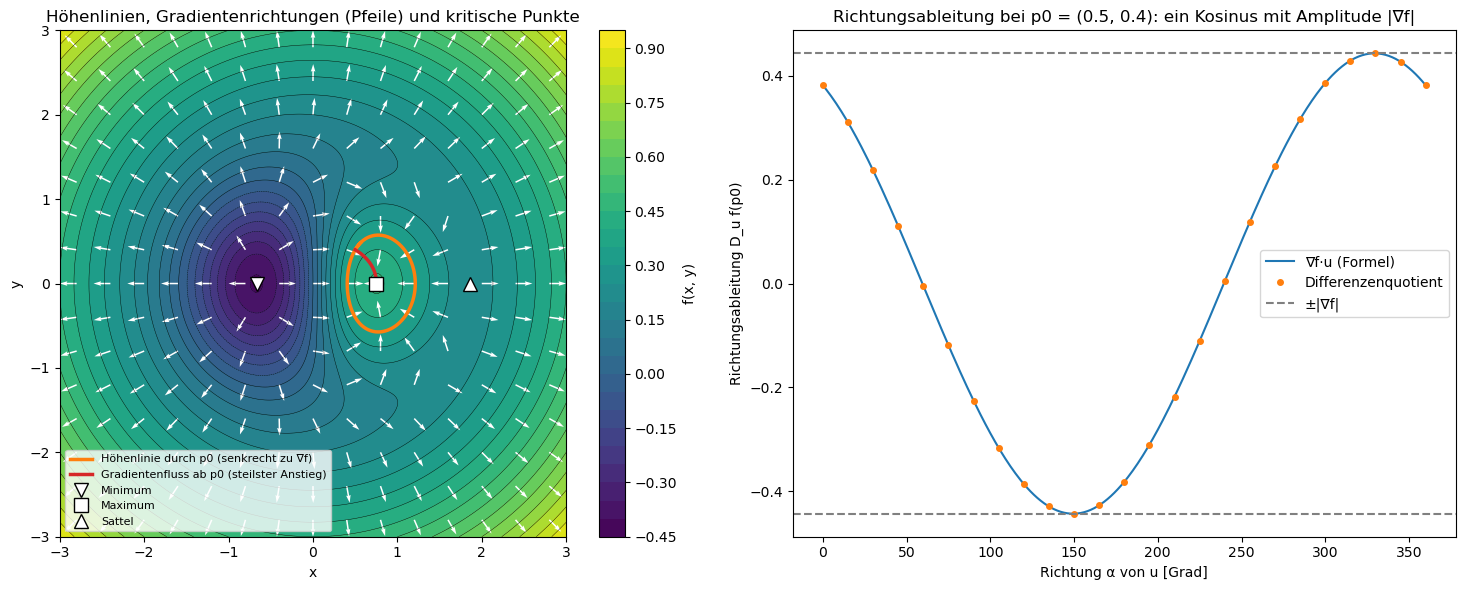

In [2]:
u_, v_ = sp.symbols("u v", real=True)
f1 = x * sp.exp(-x**2 - y**2) + (x**2 + y**2) / 20
f1n = numerisch(f1, (x, y))
g1n = numerisch(grad_s(f1, (x, y)), (x, y))
H1n = sp.lambdify((x, y), sp.hessian(f1, (x, y)), "numpy")

# Kritische Punkte: ∇f = 0 von vielen Startpunkten aus lösen, doppelte entfernen, mit der Hesse-Matrix einordnen
kritisch = []
for x0 in np.linspace(-3, 3, 13):
    for y0 in np.linspace(-3, 3, 13):
        p, info, ok, _ = fsolve(lambda q: g1n(*q), [x0, y0], full_output=True)
        if ok == 1 and np.linalg.norm(g1n(*p)) < 1e-10 and not any(np.allclose(p, q, atol=1e-6) for q in kritisch):
            kritisch.append(p)
kritisch.sort(key=lambda p: p[0])
arten = []
for p in kritisch:
    ew = np.linalg.eigvalsh(np.array(H1n(*p), dtype=float))
    arten.append("Minimum" if ew.min() > 0 else "Maximum" if ew.max() < 0 else "Sattel")
    print(f"kritischer Punkt ({p[0]:+.4f}, {p[1]:+.4f}): f = {f1n(*p):+.4f}, "
          f"Eigenwerte der Hesse-Matrix ({ew[0]:+.4f}, {ew[1]:+.4f}) → {arten[-1]}")

# Entlang (−f_y, f_x), also senkrecht zum Gradienten, bleibt f konstant; entlang ∇f steigt es am schnellsten
p0 = np.array([0.5, 0.4])
hoehe = solve_ivp(lambda s, q: np.array([-g1n(*q)[1], g1n(*q)[0]]) / np.linalg.norm(g1n(*q)), (0, 3.2), p0,
                  rtol=1e-11, atol=1e-12, max_step=0.01)
anstieg = solve_ivp(lambda s, q: g1n(*q), (0, 40), p0, rtol=1e-10, atol=1e-12, max_step=0.05)
print(f"Höhenlinie durch p0 = (0.5, 0.4), ein Umlauf: größte Abweichung |f − f(p0)| = "
      f"{np.max(np.abs(f1n(*hoehe.y) - f1n(*p0))):.1e}")
print(f"Gradientenfluss ab p0 endet bei ({anstieg.y[0, -1]:.4f}, {anstieg.y[1, -1]:.4f}), dem Maximum")

alpha = np.linspace(0, 2 * np.pi, 361)
richtungen = np.array([np.cos(alpha), np.sin(alpha)])
h = 1e-5
D_quotient = (f1n(*(p0[:, None] + h * richtungen)) - f1n(*(p0[:, None] - h * richtungen))) / (2 * h)
g0 = g1n(*p0)
D_formel = g0 @ richtungen
print(f"Richtungsableitung: Differenzenquotient gegen ∇f·u, größte Abweichung {np.max(np.abs(D_quotient - D_formel)):.1e};"
      f" Maximum {D_formel.max():.4f} bei α = {np.degrees(alpha[np.argmax(D_formel)]):.0f}°,"
      f" |∇f| = {np.linalg.norm(g0):.4f} bei arg ∇f = {np.degrees(np.arctan2(g0[1], g0[0])) % 360:.1f}°")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
s1 = np.linspace(-3, 3, 301)
XX, YY = np.meshgrid(s1, s1)
cf = ax.contourf(XX, YY, f1n(XX, YY), levels=30, cmap="viridis")
ax.contour(XX, YY, f1n(XX, YY), levels=30, colors="k", linewidths=0.3)
fig.colorbar(cf, ax=ax, label="f(x, y)")
sq = np.linspace(-2.8, 2.8, 15)
QX, QY = np.meshgrid(sq, sq)
G = g1n(QX, QY)
ax.quiver(QX, QY, G[0] / np.hypot(*G), G[1] / np.hypot(*G), color="w", scale=30, width=0.003)
ax.plot(*hoehe.y, color="tab:orange", lw=2.5, label="Höhenlinie durch p0 (senkrecht zu ∇f)")
ax.plot(*anstieg.y, color="tab:red", lw=2.5, label="Gradientenfluss ab p0 (steilster Anstieg)")
for p, art, m in zip(kritisch, arten, ["v", "s", "^"]):
    ax.plot(*p, m, color="w", mec="k", ms=10, label=art)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Höhenlinien, Gradientenrichtungen (Pfeile) und kritische Punkte")
ax = axes[1]
ax.plot(np.degrees(alpha), D_formel, label="∇f·u (Formel)")
ax.plot(np.degrees(alpha[::15]), D_quotient[::15], "o", ms=4, label="Differenzenquotient")
ax.axhline(np.linalg.norm(g0), color="0.5", ls="--", label="±|∇f|")
ax.axhline(-np.linalg.norm(g0), color="0.5", ls="--")
ax.set_xlabel("Richtung α von u [Grad]"); ax.set_ylabel("Richtungsableitung D_u f(p0)")
ax.set_title("Richtungsableitung bei p0 = (0.5, 0.4): ein Kosinus mit Amplitude |∇f|"); ax.legend()
plt.tight_layout()
plt.show()

##### *2. Divergenz und Rotation sehen*

Welche der sechs ebenen Felder haben Quellen (Divergenz), welche Wirbel (Rotation), und stimmen die Werte aus zentralen Differenzen auf einem Gitter mit den exakten überein? Im Bild ist der Hintergrund die Rotation (rot: gegen den Uhrzeigersinn, blau: im Uhrzeigersinn). Vorher vorhersagen: Hat die Scherströmung $(y, 0)$, deren Stromlinien alle gerade sind, eine Rotation? Und der Potentialwirbel $(-y, x)/r^2$, dessen Stromlinien Kreise sind?

Quelle (x, y)                div = 2            rot = 0                Gitter gegen exakt (r > 0.3): 2.2e-14
Wirbel (−y, x)               div = 0            rot = 2                Gitter gegen exakt (r > 0.3): 2.2e-14


Scherung (y, 0)              div = 0            rot = -1               Gitter gegen exakt (r > 0.3): 1.1e-14
Dehnung (x, −y)              div = 0            rot = 0                Gitter gegen exakt (r > 0.3): 1.1e-14


Potentialwirbel (−y, x)/r²   div = 0            rot = 0                Gitter gegen exakt (r > 0.3): 9.6e-02
Zellen (sin y, sin x)        div = 0            rot = cos(x) - cos(y)  Gitter gegen exakt (r > 0.3): 9.2e-03


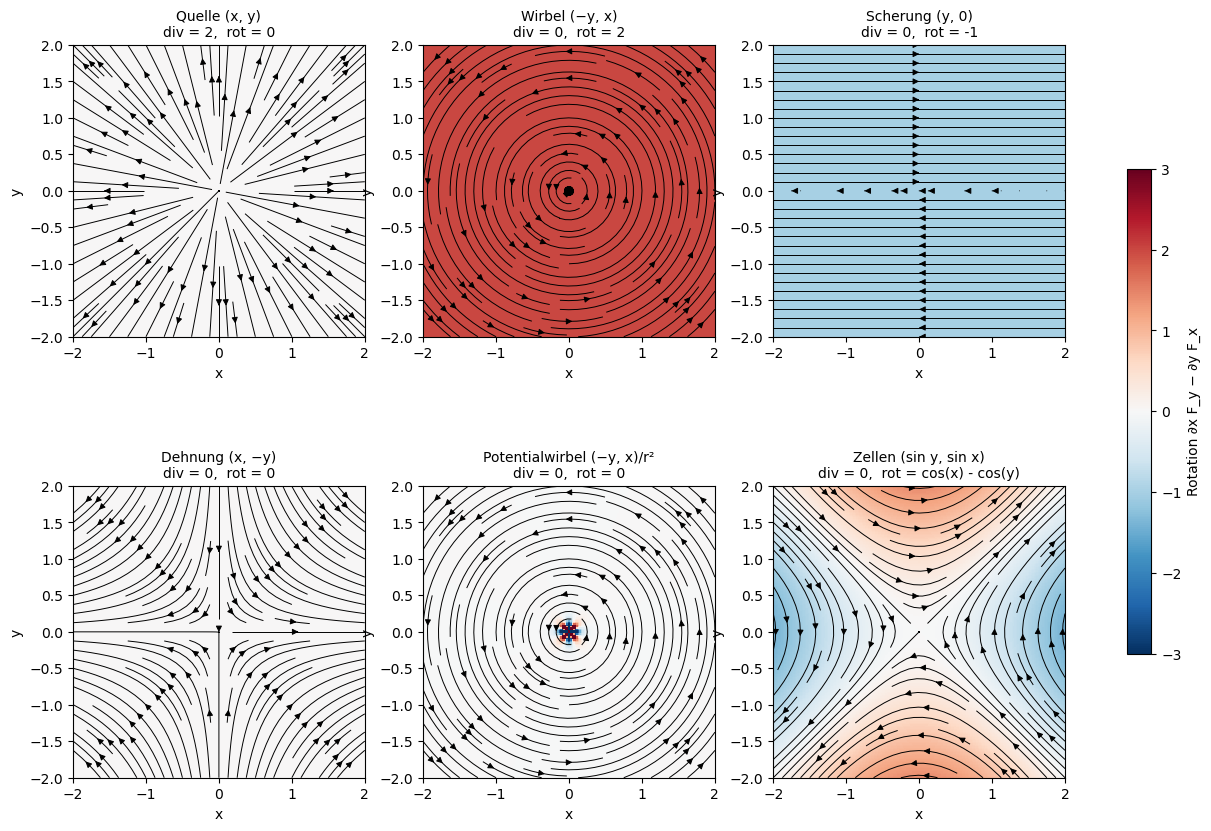

In [3]:
felder = {
    "Quelle (x, y)": (x, y),
    "Wirbel (−y, x)": (-y, x),
    "Scherung (y, 0)": (y, sp.Integer(0)),
    "Dehnung (x, −y)": (x, -y),
    "Potentialwirbel (−y, x)/r²": (-y / (x**2 + y**2), x / (x**2 + y**2)),
    "Zellen (sin y, sin x)": (sp.sin(y), sp.sin(x)),
}
s2 = np.linspace(-2, 2, 200)                                    # gerade Anzahl: kein Gitterpunkt im Ursprung
h2 = s2[1] - s2[0]
XX, YY = np.meshgrid(s2, s2, indexing="ij")
weg_vom_ursprung = np.hypot(XX, YY) > 0.3

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, (name, F) in zip(axes.flat, felder.items()):
    Fs = sp.Matrix(F)
    d_ex, r_ex = div_s(Fs, (x, y)), rot_s(Fs, (x, y))
    Fn = numerisch(Fs, (x, y))(XX, YY)
    d_num, r_num = div_num(Fn, h2), rot2_num(Fn, h2)
    abw = max(np.max(np.abs(d_num - numerisch(d_ex, (x, y))(XX, YY))[weg_vom_ursprung]),
              np.max(np.abs(r_num - numerisch(r_ex, (x, y))(XX, YY))[weg_vom_ursprung]))
    print(f"{name:28s} div = {str(d_ex):12s} rot = {str(r_ex):16s} Gitter gegen exakt (r > 0.3): {abw:.1e}")
    im = ax.pcolormesh(s2, s2, np.clip(r_num, -3, 3).T, cmap="RdBu_r", norm=TwoSlopeNorm(0, -3, 3), shading="auto")
    ax.streamplot(s2, s2, Fn[0].T, Fn[1].T, color="k", density=1.1, linewidth=0.7, arrowsize=0.9)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(f"{name}\ndiv = {d_ex},  rot = {r_ex}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.6, label="Rotation ∂x F_y − ∂y F_x")
plt.show()

##### *3. Kurvenintegrale: Arbeit, Wegunabhängigkeit und der Wirbel um ein Loch*

Hängt die Arbeit $\int\mathbf F\cdot d\mathbf r$ von $(0, 0)$ nach $(1, 2)$ vom Weg ab, wenn $\mathbf F = \nabla\varphi$ ein Gradientenfeld ist, und wenn $\mathbf F = (-y, x)$ ist? Was ergibt die Zirkulation des Potentialwirbels $(-y, x)/r^2$, der überall außer im Ursprung rotationsfrei ist, auf verschiedenen geschlossenen Wegen? Vorher vorhersagen: Was kommt auf einem Kreis heraus, der den Ursprung zweimal umläuft?

φ(1, 2) − φ(0, 0) = 2 + sin 2 = 2.9092974268
Gerade    ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.000000
Parabel   ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.666667
Schleife  ∫∇φ·dr = 2.9092974268   ∫(−y, x)·dr = +0.309483
Potentialwirbel, Kreis r = 1 um 0            : ∮ F·dr / 2π = +1.000000000000
Potentialwirbel, Ellipse um 0, verschoben    : ∮ F·dr / 2π = +1.000000000000
Potentialwirbel, Kreis um (2, 0), r = 0.7    : ∮ F·dr / 2π = +0.000000000000
Potentialwirbel, zweimal um 0                : ∮ F·dr / 2π = +2.000000000000
Potentialwirbel, Kreis um 0 im Uhrzeigersinn : ∮ F·dr / 2π = -1.000000000000


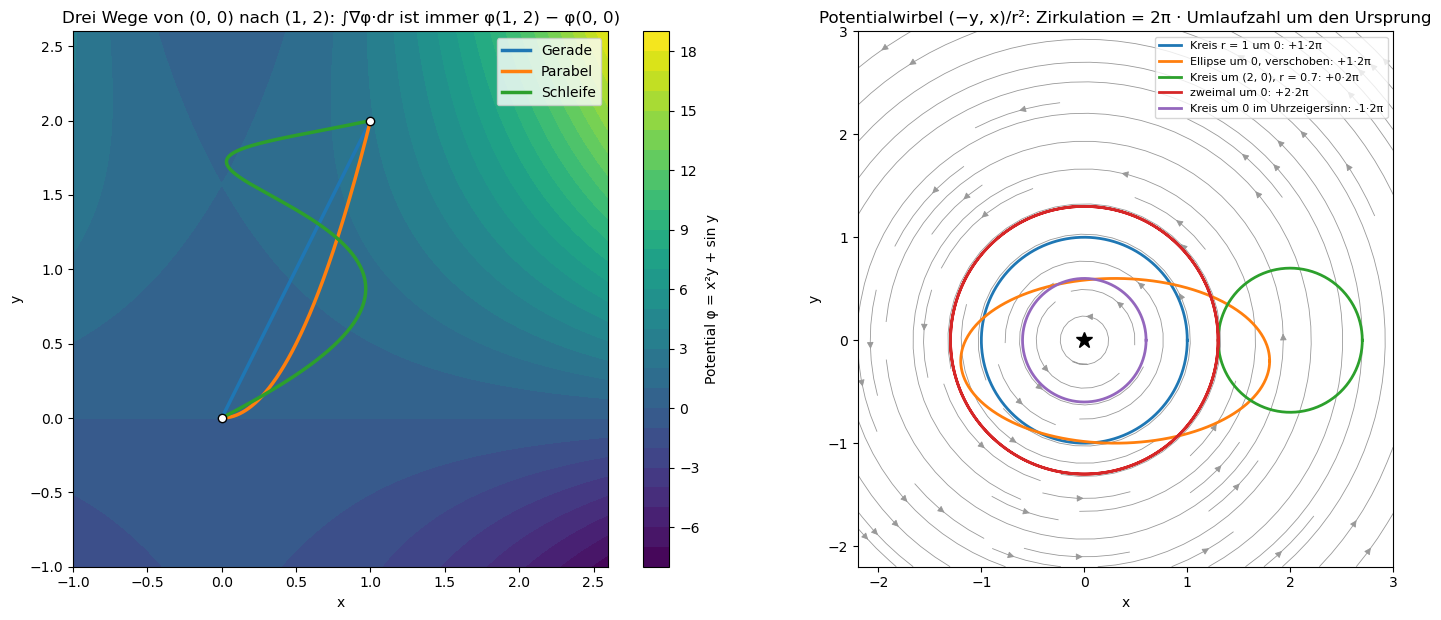

In [4]:
phi3 = x**2 * y + sp.sin(y)
F3 = numerisch(grad_s(phi3, (x, y)), (x, y))
G3 = lambda X, Y: np.array([-Y, X])
V3 = lambda X, Y: np.array([-Y, X]) / (X**2 + Y**2)

wege = {   # t ∈ [0, 1], alle von (0, 0) nach (1, 2)
    "Gerade": (lambda t: np.array([t, 2 * t]), lambda t: np.array([np.ones_like(t), 2 * np.ones_like(t)])),
    "Parabel": (lambda t: np.array([t, 2 * t**2]), lambda t: np.array([np.ones_like(t), 4 * t])),
    "Schleife": (lambda t: np.array([t + 0.7 * np.sin(2 * np.pi * t), 2 * t**2 + 0.9 * np.sin(np.pi * t)]),
                 lambda t: np.array([1 + 1.4 * np.pi * np.cos(2 * np.pi * t), 4 * t + 0.9 * np.pi * np.cos(np.pi * t)])),
}
print(f"φ(1, 2) − φ(0, 0) = 2 + sin 2 = {2 + np.sin(2):.10f}")
for name, (r, dr) in wege.items():
    W_F = kurvenintegral(F3, r, dr, 0, 1, n=60, geschlossen=False)
    W_G = kurvenintegral(G3, r, dr, 0, 1, n=60, geschlossen=False)
    print(f"{name:9s} ∫∇φ·dr = {W_F:.10f}   ∫(−y, x)·dr = {W_G:+.6f}")

schleifen = {   # t ∈ [0, 2π)
    "Kreis r = 1 um 0": (lambda t: np.array([np.cos(t), np.sin(t)]), lambda t: np.array([-np.sin(t), np.cos(t)])),
    "Ellipse um 0, verschoben": (lambda t: np.array([0.3 + 1.5 * np.cos(t), -0.2 + 0.8 * np.sin(t)]),
                                 lambda t: np.array([-1.5 * np.sin(t), 0.8 * np.cos(t)])),
    "Kreis um (2, 0), r = 0.7": (lambda t: np.array([2 + 0.7 * np.cos(t), 0.7 * np.sin(t)]),
                                 lambda t: np.array([-0.7 * np.sin(t), 0.7 * np.cos(t)])),
    "zweimal um 0": (lambda t: 1.3 * np.array([np.cos(2 * t), np.sin(2 * t)]),
                     lambda t: 2.6 * np.array([-np.sin(2 * t), np.cos(2 * t)])),
    "Kreis um 0 im Uhrzeigersinn": (lambda t: 0.6 * np.array([np.cos(t), -np.sin(t)]),
                                    lambda t: 0.6 * np.array([-np.sin(t), -np.cos(t)])),
}
for name, (r, dr) in schleifen.items():
    print(f"Potentialwirbel, {name:28s}: ∮ F·dr / 2π = {round(kurvenintegral(V3, r, dr, n=400) / (2 * np.pi), 12) + 0.0:+.12f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
ax = axes[0]
s3 = np.linspace(-1, 2.6, 300)
XX, YY = np.meshgrid(s3, s3)
cs = ax.contourf(XX, YY, numerisch(phi3, (x, y))(XX, YY), levels=25, cmap="viridis")
fig.colorbar(cs, ax=ax, label="Potential φ = x²y + sin y")
tt = np.linspace(0, 1, 300)
for name, (r, dr) in wege.items():
    ax.plot(*r(tt), lw=2.5, label=name)
ax.plot([0, 1], [0, 2], "wo", mec="k")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
ax.set_title("Drei Wege von (0, 0) nach (1, 2): ∫∇φ·dr ist immer φ(1, 2) − φ(0, 0)")
ax = axes[1]
s3b = np.linspace(-2.2, 3.0, 200)
Vb = V3(*np.meshgrid(s3b, s3b))
ax.streamplot(s3b, s3b, Vb[0], Vb[1], color="0.6", density=1.0, linewidth=0.6)
tt = np.linspace(0, 2 * np.pi, 400)
for name, (r, dr) in schleifen.items():
    ax.plot(*r(tt), lw=2, label=f"{name}: {int(np.rint(kurvenintegral(V3, r, dr) / (2 * np.pi))):+d}·2π")
ax.plot(0, 0, "k*", ms=12)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Potentialwirbel (−y, x)/r²: Zirkulation = 2π · Umlaufzahl um den Ursprung")
plt.tight_layout()
plt.show()

##### *4. Satz von Green: die Fläche aus dem Rand*

Kann man die Fläche eines Gebiets aus einer einzigen Fahrt um seinen Rand bestimmen (das Prinzip des Planimeters), und stimmt die Zirkulation $\oint P\,dx + Q\,dy$ eines nichtlinearen Feldes mit dem Integral der Rotation über das Innere überein? Das Gebiet ist die „Blume“ $\rho(t) = e^{0.5\cos3t}$ mit der Fläche $\pi I_0(1)$. Vorher vorhersagen: Was konvergiert schneller, die Trapezregel für $\tfrac12\oint(x\,dy - y\,dx)$ oder die Fläche des eingeschriebenen Polygons mit denselben $N$ Ecken?

Fläche der Blume: exakt π I₀(1) = 3.977463260506; Trapezregel N = 40: 3.977463260506; Polygon N = 40: 3.913103437685
rot F = 3*x**2 - x + 3*y**2 + sin(y):  ∮ F·dr = 10.742292658575,  ∬ rot F dA = 10.742292658575
div F = x*cos(y) + y:  ∮ F·n ds = 0.353847188464,  ∬ div F dA = 0.353847188464


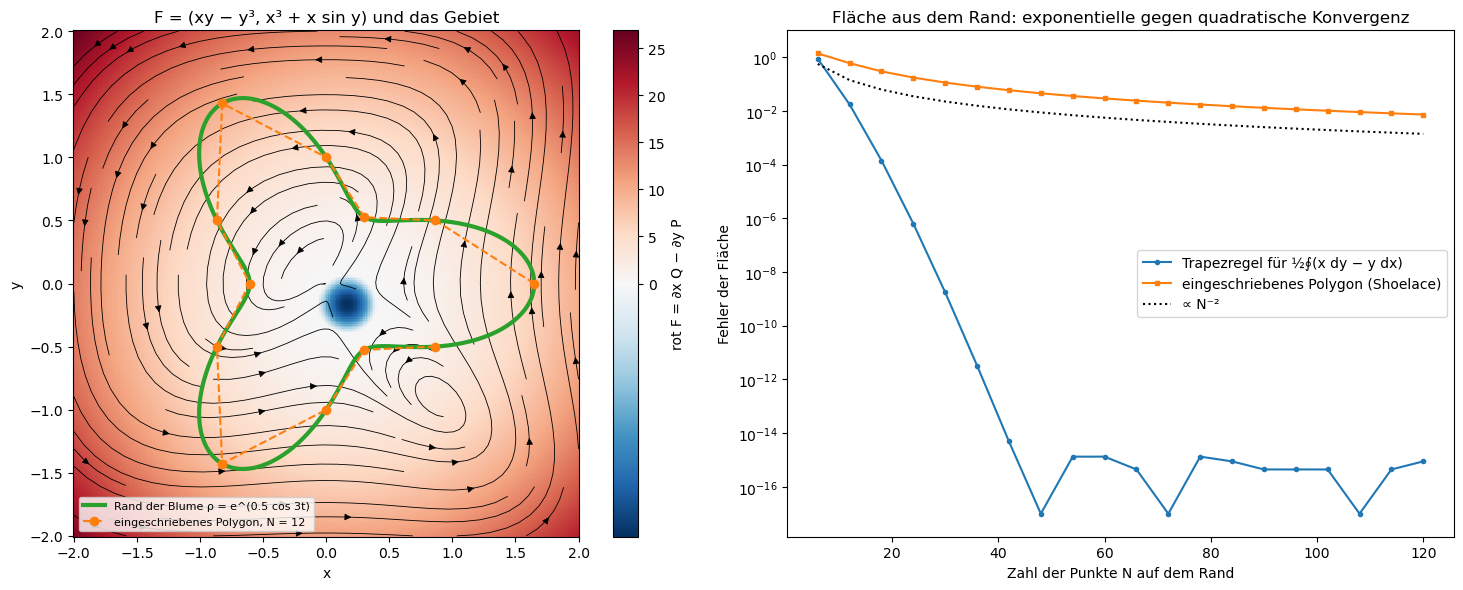

In [5]:
rho4 = lambda t: np.exp(0.5 * np.cos(3 * t))
blume = lambda t: rho4(t) * np.array([np.cos(t), np.sin(t)])
dblume = lambda t: rho4(t) * np.array([-1.5 * np.sin(3 * t) * np.cos(t) - np.sin(t),
                                       -1.5 * np.sin(3 * t) * np.sin(t) + np.cos(t)])
A_exakt = np.pi * i0(1.0)
flaechenfeld = lambda X, Y: 0.5 * np.array([-Y, X])            # ½ ∮ (x dy − y dx), Rotation 1
Ns = np.arange(6, 121, 6)                                      # Vielfache von 6, wegen der dreizähligen Symmetrie
fehler_trapez = [abs(kurvenintegral(flaechenfeld, blume, dblume, n=N) - A_exakt) for N in Ns]
fehler_polygon = [abs(schnuersenkel(*blume(2 * np.pi * np.arange(N) / N)) - A_exakt) for N in Ns]
print(f"Fläche der Blume: exakt π I₀(1) = {A_exakt:.12f}; Trapezregel N = 40: {kurvenintegral(flaechenfeld, blume, dblume, n=40):.12f};"
      f" Polygon N = 40: {schnuersenkel(*blume(2 * np.pi * np.arange(40) / 40)):.12f}")


def flaeche_polar(g, rho, n_phi=400, n_r=40):
    """∬ g dA über das sternförmige Gebiet 0 ≤ r ≤ ρ(φ) (Trapezregel in φ, Gauß–Legendre in r)."""
    phi = 2 * np.pi * np.arange(n_phi) / n_phi
    t, w = np.polynomial.legendre.leggauss(n_r)
    R = rho(phi)[None, :] * 0.5 * (t[:, None] + 1)
    W = 0.5 * rho(phi)[None, :] * w[:, None]
    return np.sum(g(R * np.cos(phi), R * np.sin(phi)) * R * W) * 2 * np.pi / n_phi


P4, Q4 = x * y - y**3, x**3 + x * sp.sin(y)
F4 = numerisch(sp.Matrix([P4, Q4]), (x, y))
rot4 = numerisch(rot_s(sp.Matrix([P4, Q4]), (x, y)), (x, y))
div4 = numerisch(div_s(sp.Matrix([P4, Q4]), (x, y)), (x, y))
normal_feld = lambda X, Y: np.array([-F4(X, Y)[1], F4(X, Y)[0]])  # F·n ds = P dy − Q dx
print(f"rot F = {rot_s(sp.Matrix([P4, Q4]), (x, y))}:  ∮ F·dr = {kurvenintegral(F4, blume, dblume):.12f},"
      f"  ∬ rot F dA = {flaeche_polar(rot4, rho4):.12f}")
print(f"div F = {div_s(sp.Matrix([P4, Q4]), (x, y))}:  ∮ F·n ds = {kurvenintegral(normal_feld, blume, dblume):.12f},"
      f"  ∬ div F dA = {flaeche_polar(div4, rho4):.12f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
s4 = np.linspace(-2, 2, 300)
XX, YY = np.meshgrid(s4, s4)
im = ax.pcolormesh(s4, s4, rot4(XX, YY), cmap="RdBu_r", norm=TwoSlopeNorm(0), shading="auto")
fig.colorbar(im, ax=ax, label="rot F = ∂x Q − ∂y P")
Fb = F4(XX, YY)
ax.streamplot(s4, s4, Fb[0], Fb[1], color="k", density=1.0, linewidth=0.6)
tt = np.linspace(0, 2 * np.pi, 400)
ax.plot(*blume(tt), color="tab:green", lw=3, label="Rand der Blume ρ = e^(0.5 cos 3t)")
ax.plot(*blume(2 * np.pi * np.arange(12) / 12), "o--", color="tab:orange", label="eingeschriebenes Polygon, N = 12")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("F = (xy − y³, x³ + x sin y) und das Gebiet")
ax = axes[1]
ax.semilogy(Ns, np.maximum(fehler_trapez, 1e-17), "o-", ms=3, label="Trapezregel für ½∮(x dy − y dx)")
ax.semilogy(Ns, fehler_polygon, "s-", ms=3, label="eingeschriebenes Polygon (Shoelace)")
ax.semilogy(Ns, 20 / Ns.astype(float) ** 2, "k:", label="∝ N⁻²")
ax.set_xlabel("Zahl der Punkte N auf dem Rand"); ax.set_ylabel("Fehler der Fläche")
ax.set_title("Fläche aus dem Rand: exponentielle gegen quadratische Konvergenz"); ax.legend()
plt.tight_layout()
plt.show()

##### *5. Gaußscher Integralsatz: der Fluss einer Punktladung*

Hängt der Fluss des Coulomb-Feldes $\mathbf E = (\mathbf r - \mathbf r_0)/\vert\mathbf r - \mathbf r_0\vert^3$ durch eine geschlossene Fläche von ihrer Form und von der Lage der Ladung ab? Geprüft werden Kugeln und ein Würfel, Ladungen innen und außen, ein Dipol, und für ein glattes Feld der Satz selbst, $\oint\mathbf F\cdot d\mathbf A = \int\nabla\cdot\mathbf F\,dV$. Vorher vorhersagen: Was ändert sich, wenn die Ladung der Kugeloberfläche sehr nahe kommt, am Ergebnis und an der Zahl der nötigen Stützstellen?

Ladung im Mittelpunkt                : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +1.0000000000
Ladung bei (0.3, 0.2, 0.1)           : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +1.0000000000
Ladung bei (0, 0, 0.9), nahe am Rand : Fluss/4π durch die Einheitskugel +1.0000000000, durch den Würfel [−1, 1]³ +0.9999999999
Ladung bei (0, 0, 1.5), außen        : Fluss/4π durch die Einheitskugel +0.0000000000, durch den Würfel [−1, 1]³ +0.0000000000
F = (x³, y³, z³): Fluss durch die Einheitskugel 7.539822368616, ∫div F dV = 12π/5 = 7.539822368616; durch den Würfel 24.000000000000, ∫div F dV = 24
Dipol, Kugel um +     : Fluss/4π = +1.0000000000
Dipol, Kugel um −     : Fluss/4π = -1.0000000000
Dipol, Kugel um beide : Fluss/4π = +0.0000000000


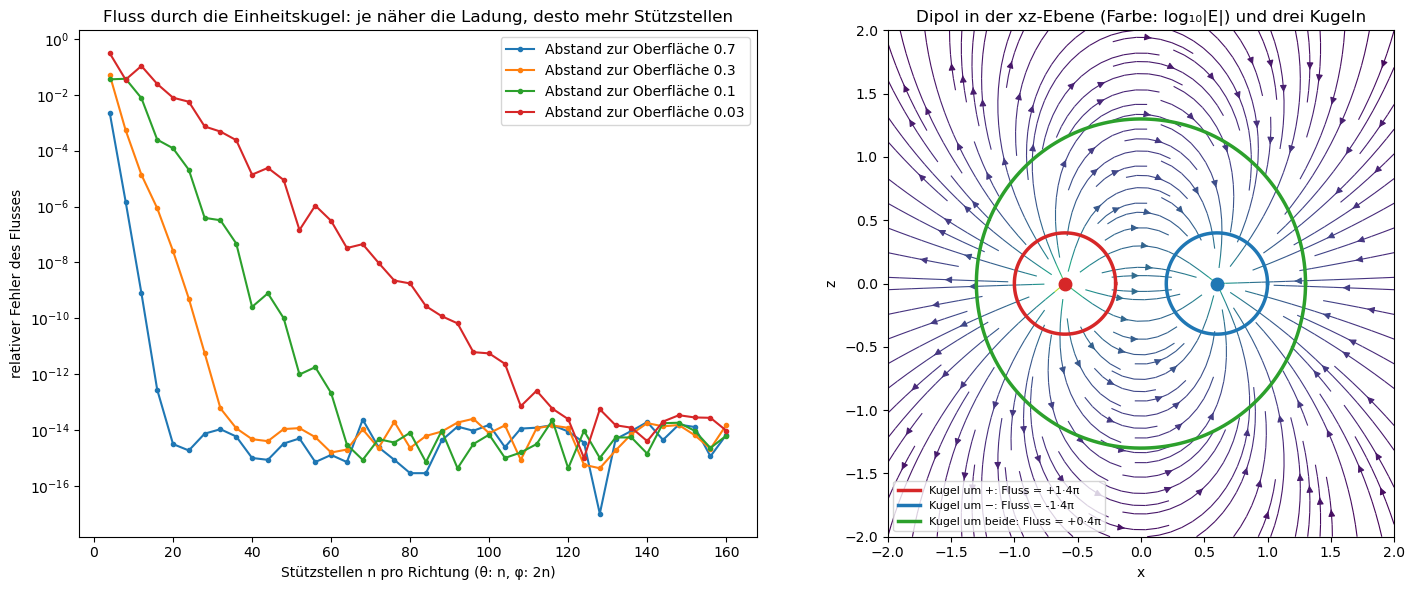

In [6]:
th_, ph_ = sp.symbols("theta phi", real=True)
kugel = parametrisierung([sp.sin(th_) * sp.cos(ph_), sp.sin(th_) * sp.sin(ph_), sp.cos(th_)], th_, ph_)  # r_θ × r_φ nach außen


def coulomb(r0, q=1.0):
    def E(X, Y, Z):
        d = np.array([X - r0[0], Y - r0[1], Z - r0[2]])
        return q * d / np.sum(d**2, axis=0) ** 1.5
    return E


def fluss_kugel(G, M=(0, 0, 0), R=1.0, n=80):
    """Fluss durch die Kugel um M mit Radius R (nach außen orientiert)."""
    r, ru, rv = kugel
    verschoben = lambda U, V: np.array(M, dtype=float)[:, None, None] + R * r(U, V)
    return flaechenintegral(G, verschoben, lambda U, V: R * ru(U, V), lambda U, V: R * rv(U, V),
                            0, np.pi, 0, 2 * np.pi, n=n, periodisch_v=True)


def fluss_wuerfel(G, n=40):
    """Fluss durch die Oberfläche des Würfels [−1, 1]³ (nach außen orientiert)."""
    t, w = gauss_legendre(n, -1, 1)
    U, V = np.meshgrid(t, t, indexing="ij")
    gesamt = 0.0
    for a in range(3):
        for s in (-1.0, 1.0):
            P = [None] * 3
            P[a], P[(a + 1) % 3], P[(a + 2) % 3] = np.full_like(U, s), U, V
            gesamt += s * np.sum(G(*P)[a] * np.outer(w, w))
    return gesamt


for name, r0 in [("im Mittelpunkt", (0, 0, 0)), ("bei (0.3, 0.2, 0.1)", (0.3, 0.2, 0.1)),
                 ("bei (0, 0, 0.9), nahe am Rand", (0, 0, 0.9)), ("bei (0, 0, 1.5), außen", (0, 0, 1.5))]:
    print(f"Ladung {name:30s}: Fluss/4π durch die Einheitskugel {round(fluss_kugel(coulomb(r0), n=120) / (4 * np.pi), 10) + 0.0:+.10f},"
          f" durch den Würfel [−1, 1]³ {round(fluss_wuerfel(coulomb(r0), n=120) / (4 * np.pi), 10) + 0.0:+.10f}")

# Der Satz selbst für ein glattes Feld: F = (x³, y³, z³), div F = 3(x² + y² + z²)
F5 = lambda X, Y, Z: np.array([X**3, Y**3, Z**3])
print(f"F = (x³, y³, z³): Fluss durch die Einheitskugel {fluss_kugel(F5, n=20):.12f}, ∫div F dV = 12π/5 = {12 * np.pi / 5:.12f};"
      f" durch den Würfel {fluss_wuerfel(F5, n=10):.12f}, ∫div F dV = 24")

# Dipol: Kugeln um die positive, um die negative und um beide Ladungen
plus, minus = (-0.6, 0, 0), (0.6, 0, 0)
dipol = lambda X, Y, Z: coulomb(plus, 1)(X, Y, Z) + coulomb(minus, -1)(X, Y, Z)
kugeln = {"um +": (plus, 0.4), "um −": (minus, 0.4), "um beide": ((0, 0, 0), 1.3)}
for name, (M, R) in kugeln.items():
    print(f"Dipol, Kugel {name:9s}: Fluss/4π = {round(fluss_kugel(dipol, M, R, n=120) / (4 * np.pi), 10) + 0.0:+.10f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ns = np.arange(4, 161, 4)
for d in [0.7, 0.3, 0.1, 0.03]:
    fehler = [abs(fluss_kugel(coulomb((0, 0, 1 - d)), n=n) - 4 * np.pi) / (4 * np.pi) for n in ns]
    ax.semilogy(ns, np.maximum(fehler, 1e-17), "o-", ms=3, label=f"Abstand zur Oberfläche {d}")
ax.set_xlabel("Stützstellen n pro Richtung (θ: n, φ: 2n)"); ax.set_ylabel("relativer Fehler des Flusses")
ax.set_title("Fluss durch die Einheitskugel: je näher die Ladung, desto mehr Stützstellen"); ax.legend()
ax = axes[1]
s5 = np.linspace(-2, 2, 300)
XX, ZZ = np.meshgrid(s5, s5)
E_xz = dipol(XX, np.zeros_like(XX), ZZ)
ax.streamplot(s5, s5, E_xz[0], E_xz[2], color=np.log10(np.hypot(E_xz[0], E_xz[2])), cmap="viridis",
              density=1.4, linewidth=0.8)
tt = np.linspace(0, 2 * np.pi, 200)
for (name, (M, R)), farbe in zip(kugeln.items(), ["tab:red", "tab:blue", "tab:green"]):
    wert = round(fluss_kugel(dipol, M, R, n=120) / (4 * np.pi), 6) + 0.0
    ax.plot(M[0] + R * np.cos(tt), M[2] + R * np.sin(tt), color=farbe, lw=2.5, label=f"Kugel {name}: Fluss = {wert:+.0f}·4π")
ax.plot(plus[0], plus[2], "o", color="tab:red", ms=9); ax.plot(minus[0], minus[2], "o", color="tab:blue", ms=9)
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("z"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Dipol in der xz-Ebene (Farbe: log₁₀|E|) und drei Kugeln")
plt.tight_layout()
plt.show()

##### *6. Satz von Stokes: ein Rand, viele Flächen*

Ist der Fluss der Rotation $\iint(\nabla\times\mathbf F)\cdot d\mathbf A$ für alle Flächen gleich, die vom selben Einheitskreis berandet werden, und gleich der Zirkulation $\oint\mathbf F\cdot d\mathbf r$ entlang des Kreises? Das Feld ist $\mathbf F = (yz - y^3,\ x^3 + xz^2,\ e^{xy})$, die Flächen sind die Kreisscheibe, die obere Halbkugel, ein Paraboloid, eine nach unten gewölbte Schale und eine verbeulte Kappe. Vorher vorhersagen: Was ergibt der Fluss von $\nabla\times\mathbf F$ durch eine geschlossene Kugel?

rot F = [-2*x*z + x*exp(x*y), -y*exp(x*y) + y, 3*x**2 + 3*y**2 + z**2 - z]   div rot F = 0
Zirkulation entlang des Einheitskreises: 4.712388980385  (3π/2 = 4.712388980385)
Kreisscheibe              : Fluss von rot F = 4.712388980385
Halbkugel                 : Fluss von rot F = 4.712388980385
Paraboloid z = 2(1 − ρ²)  : Fluss von rot F = 4.712388980385
Schale z = −1.5(1 − ρ²)   : Fluss von rot F = 4.712388980385
verbeulte Kappe           : Fluss von rot F = 4.712388980385
geschlossene Einheitskugel  : Fluss von rot F = -9.1e-14


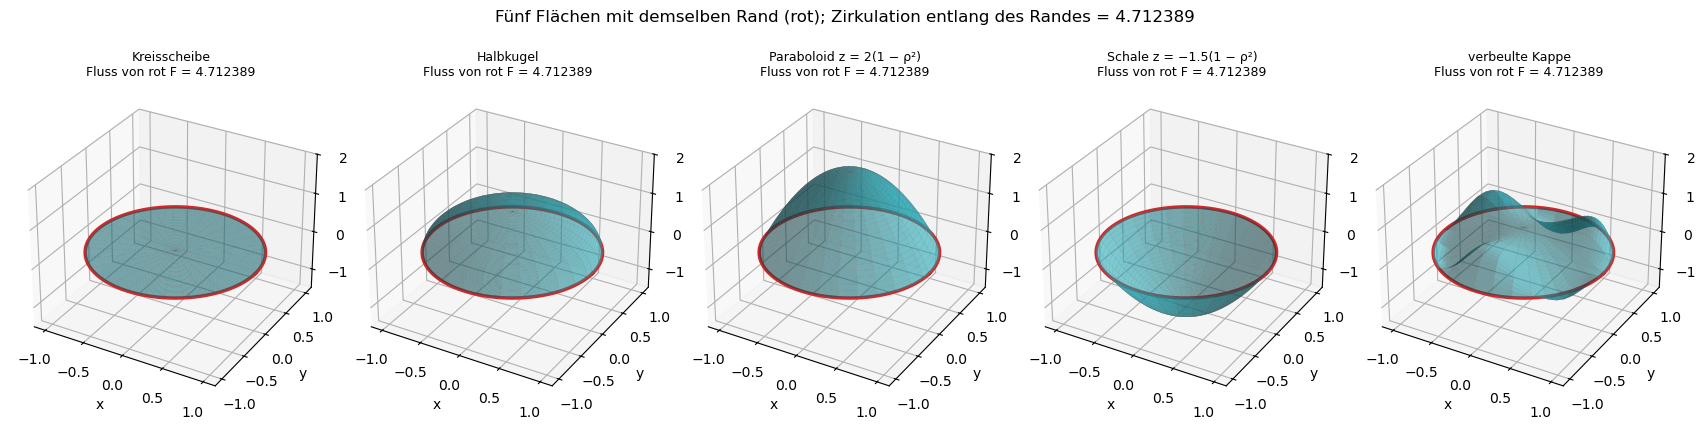

In [7]:
F6 = sp.Matrix([y * z - y**3, x**3 + x * z**2, sp.exp(x * y)])
rotF6 = rot_s(F6)
print("rot F =", list(rotF6), "  div rot F =", div_s(rotF6))
F6n, rotF6n = numerisch(F6), numerisch(rotF6)
kreis3 = lambda t: np.array([np.cos(t), np.sin(t), np.zeros_like(t)])
dkreis3 = lambda t: np.array([-np.sin(t), np.cos(t), np.zeros_like(t)])
zirkulation = kurvenintegral(F6n, kreis3, dkreis3, n=200)
print(f"Zirkulation entlang des Einheitskreises: {zirkulation:.12f}  (3π/2 = {1.5 * np.pi:.12f})")

rh_ = sp.symbols("rho", positive=True)
flaechen = {    # Parametrisierung, Bereich des ersten Parameters; der zweite ist der Winkel φ ∈ [0, 2π)
    "Kreisscheibe": ([rh_ * sp.cos(ph_), rh_ * sp.sin(ph_), 0], (0, 1)),
    "Halbkugel": ([sp.sin(th_) * sp.cos(ph_), sp.sin(th_) * sp.sin(ph_), sp.cos(th_)], (0, np.pi / 2)),
    "Paraboloid z = 2(1 − ρ²)": ([rh_ * sp.cos(ph_), rh_ * sp.sin(ph_), 2 * (1 - rh_**2)], (0, 1)),
    "Schale z = −1.5(1 − ρ²)": ([rh_ * sp.cos(ph_), rh_ * sp.sin(ph_), -1.5 * (1 - rh_**2)], (0, 1)),
    "verbeulte Kappe": ([rh_ * sp.cos(ph_), rh_ * sp.sin(ph_), (1 - rh_**2) * (0.6 + 3 * rh_**3 * sp.sin(3 * ph_))], (0, 1)),
}
werte = {}
for name, (r_sym, (a, b)) in flaechen.items():
    erster = th_ if name == "Halbkugel" else rh_
    werte[name] = flaechenintegral(rotF6n, *parametrisierung(r_sym, erster, ph_), a, b, 0, 2 * np.pi, n=60, periodisch_v=True)
    print(f"{name:26s}: Fluss von rot F = {werte[name]:.12f}")
print(f"geschlossene Einheitskugel  : Fluss von rot F = {fluss_kugel(rotF6n, n=60):+.1e}")

fig = plt.figure(figsize=(17, 4.6))
for k, (name, (r_sym, (a, b))) in enumerate(flaechen.items()):
    ax = fig.add_subplot(1, 5, k + 1, projection="3d")
    erster = th_ if name == "Halbkugel" else rh_
    r = parametrisierung(r_sym, erster, ph_)[0]
    U, V = np.meshgrid(np.linspace(a, b, 30), np.linspace(0, 2 * np.pi, 60), indexing="ij")
    P = r(U, V)
    ax.plot_surface(*P, color="tab:cyan", alpha=0.55, edgecolor="0.4", linewidth=0.1)
    tt = np.linspace(0, 2 * np.pi, 200)
    ax.plot(*kreis3(tt), color="tab:red", lw=2.5)
    ax.set_zlim(-1.5, 2); ax.set_zticks([-1, 0, 1, 2]); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_title(f"{name}\nFluss von rot F = {werte[name]:.6f}", fontsize=9)
fig.suptitle(f"Fünf Flächen mit demselben Rand (rot); Zirkulation entlang des Randes = {zirkulation:.6f}")
plt.tight_layout()
plt.show()

##### *7. Krummlinige Koordinaten*

Stimmen die Formeln für Gradient, Divergenz, Rotation und Laplace-Operator in Kugel- und Zylinderkoordinaten mit der kartesischen Rechnung überein? Mit sympy werden die Skalenfaktoren aus der Koordinatenabbildung bestimmt, die Operatoren daraus gebaut und an bekannten Feldern geprüft; numerisch wird der Laplace-Operator von $e^{-r^2}$ auf einem kartesischen Gitter mit der Kugelformel $f'' + \tfrac2rf'$ verglichen. Vorher vorhersagen: Für welches $n$ ist $r^n$ harmonisch?

Metrik in Kugelkoordinaten: [[1, 0, 0], [0, r**2, 0], [0, 0, r**2*sin(theta)**2]]   det der Jacobi-Matrix: r**2*sin(theta)


Δf kartesisch gegen Kugelformel, f = x²yz + z³ + eˣy:  Differenz = 0
Δ rⁿ = n*r**(n - 2)*(n + 1)   Δ(1/r) = 0   div(e_r/r²) = 0
Δ(r² Y₂¹) = 0   r² ΔY₂¹ / Y₂¹ = -6 = −l(l + 1) mit l = 2
Zylinder: rot(e_φ/ρ) = [0, 0, 0]  div(e_ρ/ρ) = 0  Δ ln ρ = 0  rot(starre Drehung ωρ e_φ) = [0, 0, 2*omega]
Δ e^(−r²): 7-Punkte-Stern (h = 0.050) gegen Kugelformel, größte Abweichung 7.5e-03


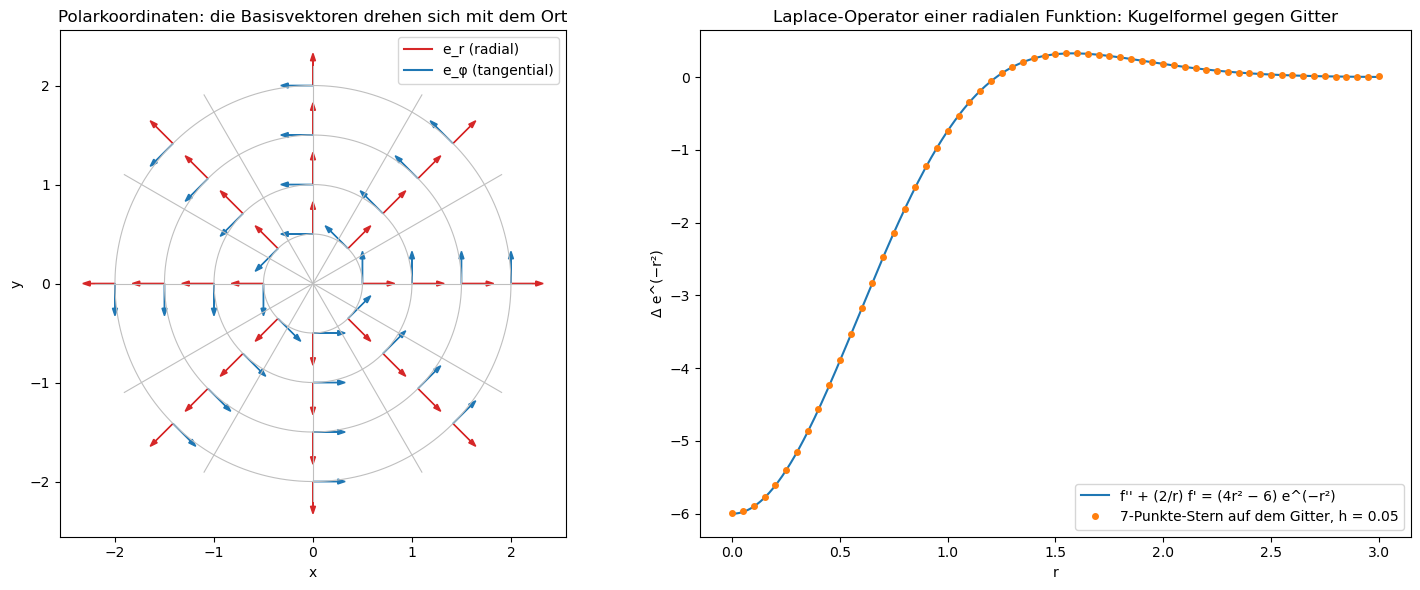

In [8]:
r_, t_, p_ = sp.symbols("r theta phi", positive=True)
rz_, pz_, zz_ = sp.symbols("rho phi z", real=True)


def operatoren(q, h):
    """grad, div, rot, Δ in orthogonalen Koordinaten q mit Skalenfaktoren h (Komponenten in der Basis e_q)."""
    J = h[0] * h[1] * h[2]
    grad = lambda f: sp.Matrix([sp.diff(f, q[i]) / h[i] for i in range(3)])
    div = lambda F: sp.simplify(sum(sp.diff(J / h[i] * F[i], q[i]) for i in range(3)) / J)
    rot = lambda F: sp.Matrix([(sp.diff(h[2] * F[2], q[1]) - sp.diff(h[1] * F[1], q[2])) / (h[1] * h[2]),
                               (sp.diff(h[0] * F[0], q[2]) - sp.diff(h[2] * F[2], q[0])) / (h[2] * h[0]),
                               (sp.diff(h[1] * F[1], q[0]) - sp.diff(h[0] * F[0], q[1])) / (h[0] * h[1])]).applyfunc(sp.simplify)
    lap = lambda f: sp.simplify(div(grad(f)))
    return grad, div, rot, lap


# Skalenfaktoren aus der Abbildung (r, θ, φ) → (x, y, z): Metrik g_ij = ∂_i X · ∂_j X
X_kugel = sp.Matrix([r_ * sp.sin(t_) * sp.cos(p_), r_ * sp.sin(t_) * sp.sin(p_), r_ * sp.cos(t_)])
Jac = X_kugel.jacobian([r_, t_, p_])
print("Metrik in Kugelkoordinaten:", sp.simplify(Jac.T * Jac).tolist(), "  det der Jacobi-Matrix:", sp.simplify(Jac.det()))
grad_k, div_k, rot_k, lap_k = operatoren((r_, t_, p_), (1, r_, r_ * sp.sin(t_)))
grad_z, div_z, rot_z, lap_z = operatoren((rz_, pz_, zz_), (1, rz_, 1))

nach_kugel = {x: X_kugel[0], y: X_kugel[1], z: X_kugel[2]}
f7 = x**2 * y * z + z**3 + sp.exp(x) * y
lap_kart = sum(sp.diff(f7, q, 2) for q in X3)
print("Δf kartesisch gegen Kugelformel, f = x²yz + z³ + eˣy:  Differenz =",
      sp.simplify(lap_k(f7.subs(nach_kugel)) - lap_kart.subs(nach_kugel)))
n_ = sp.symbols("n")
print("Δ rⁿ =", sp.factor(lap_k(r_**n_)), "  Δ(1/r) =", lap_k(1 / r_), "  div(e_r/r²) =", div_k([1 / r_**2, 0, 0]))
Y21 = sp.expand_func(sp.Ynm(2, 1, t_, p_))
print("Δ(r² Y₂¹) =", lap_k(r_**2 * Y21), "  r² ΔY₂¹ / Y₂¹ =", sp.simplify(lap_k(Y21) * r_**2 / Y21), "= −l(l + 1) mit l = 2")
print("Zylinder: rot(e_φ/ρ) =", list(rot_z([0, 1 / rz_, 0])), " div(e_ρ/ρ) =", div_z([1 / rz_, 0, 0]),
      " Δ ln ρ =", lap_z(sp.log(rz_)), " rot(starre Drehung ωρ e_φ) =", list(rot_z([0, sp.Symbol("omega") * rz_, 0])))

# Numerisch: Δ e^(−r²) auf einem kartesischen Gitter (7-Punkte-Stern) gegen (4r² − 6) e^(−r²)
s7 = np.linspace(-3, 3, 121)
h7 = s7[1] - s7[0]
XX, YY, ZZ = np.meshgrid(s7, s7, s7, indexing="ij")
u7 = np.exp(-(XX**2 + YY**2 + ZZ**2))
lap7 = sum(np.roll(u7, -1, a) - 2 * u7 + np.roll(u7, 1, a) for a in range(3)) / h7**2
R7 = np.sqrt(XX**2 + YY**2 + ZZ**2)
innen = (np.abs(XX) < 2.9) & (np.abs(YY) < 2.9) & (np.abs(ZZ) < 2.9)
abw7 = np.max(np.abs(lap7 - (4 * R7**2 - 6) * u7)[innen])
print(f"Δ e^(−r²): 7-Punkte-Stern (h = {h7:.3f}) gegen Kugelformel, größte Abweichung {abw7:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
for rr in [0.5, 1.0, 1.5, 2.0]:
    tt = np.linspace(0, 2 * np.pi, 200)
    ax.plot(rr * np.cos(tt), rr * np.sin(tt), color="0.75", lw=0.8)
for pp in np.linspace(0, 2 * np.pi, 12, endpoint=False):
    ax.plot([0, 2.2 * np.cos(pp)], [0, 2.2 * np.sin(pp)], color="0.75", lw=0.8)
for rr in [0.5, 1.0, 1.5, 2.0]:
    for pp in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        px, py = rr * np.cos(pp), rr * np.sin(pp)
        ax.arrow(px, py, 0.25 * np.cos(pp), 0.25 * np.sin(pp), head_width=0.05, color="tab:red")
        ax.arrow(px, py, -0.25 * np.sin(pp), 0.25 * np.cos(pp), head_width=0.05, color="tab:blue")
ax.plot([], [], color="tab:red", label="e_r (radial)"); ax.plot([], [], color="tab:blue", label="e_φ (tangential)")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper right")
ax.set_title("Polarkoordinaten: die Basisvektoren drehen sich mit dem Ort")
ax = axes[1]
strahl = (np.abs(YY) < 1e-9) & (np.abs(ZZ) < 1e-9) & (XX >= 0)
rr = np.linspace(0, 3, 300)
ax.plot(rr, (4 * rr**2 - 6) * np.exp(-rr**2), label="f'' + (2/r) f' = (4r² − 6) e^(−r²)")
ax.plot(XX[strahl], lap7[strahl], "o", ms=4, label=f"7-Punkte-Stern auf dem Gitter, h = {h7:.2f}")
ax.set_xlabel("r"); ax.set_ylabel("Δ e^(−r²)"); ax.legend()
ax.set_title("Laplace-Operator einer radialen Funktion: Kugelformel gegen Gitter")
plt.tight_layout()
plt.show()

##### *8. Die Identitäten $\nabla\times\nabla f = 0$ und $\nabla\cdot(\nabla\times\mathbf A) = 0$, auch auf dem Gitter*

Gelten die Identitäten der Vektoranalysis für beliebige Felder, und gelten sie auch nach dem Diskretisieren? Symbolisch werden sie mit allgemeinen Funktionen $f(x, y, z)$ und $A_i(x, y, z)$ geprüft. Numerisch werden auf einem periodischen Gitter alle Ableitungen durch zentrale Differenzen $D_i$ ersetzt; für $\nabla\times\nabla\times\mathbf A = \nabla(\nabla\cdot\mathbf A) - \Delta\mathbf A$ wird $\Delta$ einmal als $\sum_iD_iD_i$ und einmal mit dem üblichen 3-Punkte-Stern gerechnet. Vorher vorhersagen: Welche Reste fallen mit der Gitterweite, und welche sind von Anfang an null?

rot grad f                       = [0, 0, 0]
div rot A                        = 0
rot rot A − (grad div A − ΔA)    = [0, 0, 0]
div(fA) − (∇f·A + f div A)       = 0
rot(fA) − (∇f × A + f rot A)     = [0, 0, 0]


Gitter: rot grad f                               n=12: 4.4e-16  n=24: 8.9e-16  n=48: 1.9e-15  n=96: 4.4e-15
Gitter: div rot A                                n=12: 8.9e-16  n=24: 2.0e-15  n=48: 4.3e-15  n=96: 9.8e-15
Gitter: rot rot A − (grad div A − Σ DᵢDᵢ A)      n=12: 1.8e-15  n=24: 2.1e-15  n=48: 4.7e-15  n=96: 9.3e-15
Gitter: rot rot A − (grad div A − Δ₃ A)          n=12: 1.3e+00  n=24: 4.1e-01  n=48: 1.1e-01  n=96: 2.7e-02


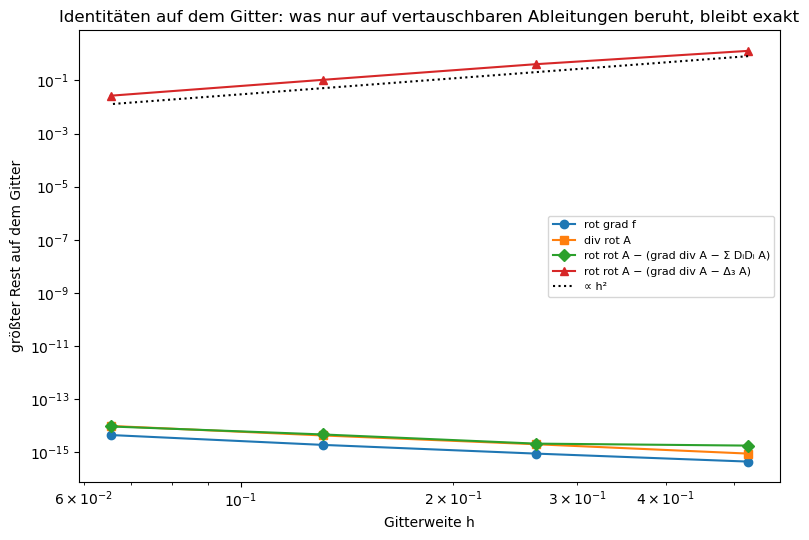

In [9]:
f8 = sp.Function("f")(x, y, z)
A8 = sp.Matrix([sp.Function(f"A_{i}")(x, y, z) for i in "xyz"])
lap_vec = lambda A: sp.Matrix([sum(sp.diff(a, q, 2) for q in X3) for a in A])
identitaeten = {
    "rot grad f": rot_s(grad_s(f8)),
    "div rot A": div_s(rot_s(A8)),
    "rot rot A − (grad div A − ΔA)": rot_s(rot_s(A8)) - (grad_s(div_s(A8)) - lap_vec(A8)),
    "div(fA) − (∇f·A + f div A)": div_s(f8 * A8) - (grad_s(f8).dot(A8) + f8 * div_s(A8)),
    "rot(fA) − (∇f × A + f rot A)": rot_s(f8 * A8) - (grad_s(f8).cross(A8) + f8 * rot_s(A8)),
}
for name, rest in identitaeten.items():
    rest = sp.simplify(rest)
    print(f"{name:32s} = {list(rest) if isinstance(rest, sp.MatrixBase) else rest}")


def D(u, a, h):    # zentrale Differenz entlang Achse a, periodisch
    return (np.roll(u, -1, a) - np.roll(u, 1, a)) / (2 * h)


def D2(u, a, h):   # 3-Punkte-Stern für die zweite Ableitung
    return (np.roll(u, -1, a) - 2 * u + np.roll(u, 1, a)) / h**2


def rot_D(A, h):
    return np.array([D(A[2], 1, h) - D(A[1], 2, h), D(A[0], 2, h) - D(A[2], 0, h), D(A[1], 0, h) - D(A[0], 1, h)])


reste = {k: [] for k in ["rot grad f", "div rot A", "rot rot A − (grad div A − Σ DᵢDᵢ A)", "rot rot A − (grad div A − Δ₃ A)"]}
ns8 = [12, 24, 48, 96]
for n in ns8:
    s8 = 2 * np.pi * np.arange(n) / n
    h8 = s8[1]
    XX, YY, ZZ = np.meshgrid(s8, s8, s8, indexing="ij")
    f_g = np.cos(XX) * np.sin(2 * YY) + np.sin(ZZ) * np.cos(XX)
    A_g = np.array([np.sin(YY + ZZ) + np.sin(XX) * np.cos(YY), np.cos(ZZ) * np.sin(2 * XX) + np.sin(YY) ** 2,
                    np.sin(XX) * np.cos(YY) + np.cos(ZZ) * np.sin(XX)])
    grad_f = np.array([D(f_g, a, h8) for a in range(3)])
    divA = sum(D(A_g[a], a, h8) for a in range(3))
    gdivA = np.array([D(divA, a, h8) for a in range(3)])
    rrA = rot_D(rot_D(A_g, h8), h8)
    reste["rot grad f"].append(np.max(np.abs(rot_D(grad_f, h8))))
    reste["div rot A"].append(np.max(np.abs(sum(D(rot_D(A_g, h8)[a], a, h8) for a in range(3)))))
    reste["rot rot A − (grad div A − Σ DᵢDᵢ A)"].append(
        np.max(np.abs(rrA - gdivA + np.array([sum(D(D(A_g[c], a, h8), a, h8) for a in range(3)) for c in range(3)]))))
    reste["rot rot A − (grad div A − Δ₃ A)"].append(
        np.max(np.abs(rrA - gdivA + np.array([sum(D2(A_g[c], a, h8) for a in range(3)) for c in range(3)]))))
for name, werte8 in reste.items():
    print(f"Gitter: {name:40s}", "  ".join(f"n={n}: {w:.1e}" for n, w in zip(ns8, werte8)))

fig, ax = plt.subplots(figsize=(8, 5.5))
hs = 2 * np.pi / np.array(ns8)
for (name, werte8), m in zip(reste.items(), "osD^"):
    ax.loglog(hs, np.maximum(werte8, 1e-17), m + "-", label=name)
ax.loglog(hs, 3 * hs**2, "k:", label="∝ h²")
ax.set_xlabel("Gitterweite h"); ax.set_ylabel("größter Rest auf dem Gitter")
ax.set_title("Identitäten auf dem Gitter: was nur auf vertauschbaren Ableitungen beruht, bleibt exakt")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

##### *9. Helmholtz-Zerlegung mit der FFT*

Lässt sich ein Vektorfeld eindeutig in einen wirbelfreien Teil $\nabla\varphi$, einen quellenfreien Teil $\nabla^\perp\psi = (\partial_y\psi, -\partial_x\psi)$ und einen konstanten Mittelwert zerlegen, und findet die Projektion im Fourier-Raum $\hat{\mathbf v}\mapsto\mathbf k(\mathbf k\cdot\hat{\mathbf v})/k^2$ genau die Teile wieder, aus denen das Feld gebaut wurde? Das Gebiet ist der Torus $[0, 2\pi)^2$ (periodische Ränder). Vorher vorhersagen: Wie teilt sich $\int\vert\mathbf v\vert^2$ auf die drei Teile auf?

Gradiententeil: Abweichung vom Bauteil 3.6e-15, rot = 5.4e-14
quellenfreier Teil: Abweichung 3.3e-15, div = 3.4e-14
Mittelwert [ 0.2 -0.1]; φ und ψ bis auf Konstanten: 2.7e-15, 1.6e-15
⟨∇φ, ∇⊥ψ⟩ = +1.4e-17;  Mittelwert von |v|² = 3.635000 = 2.500000 (Gradient) + 1.085000 (quellenfrei) + 0.050000 (konstant)


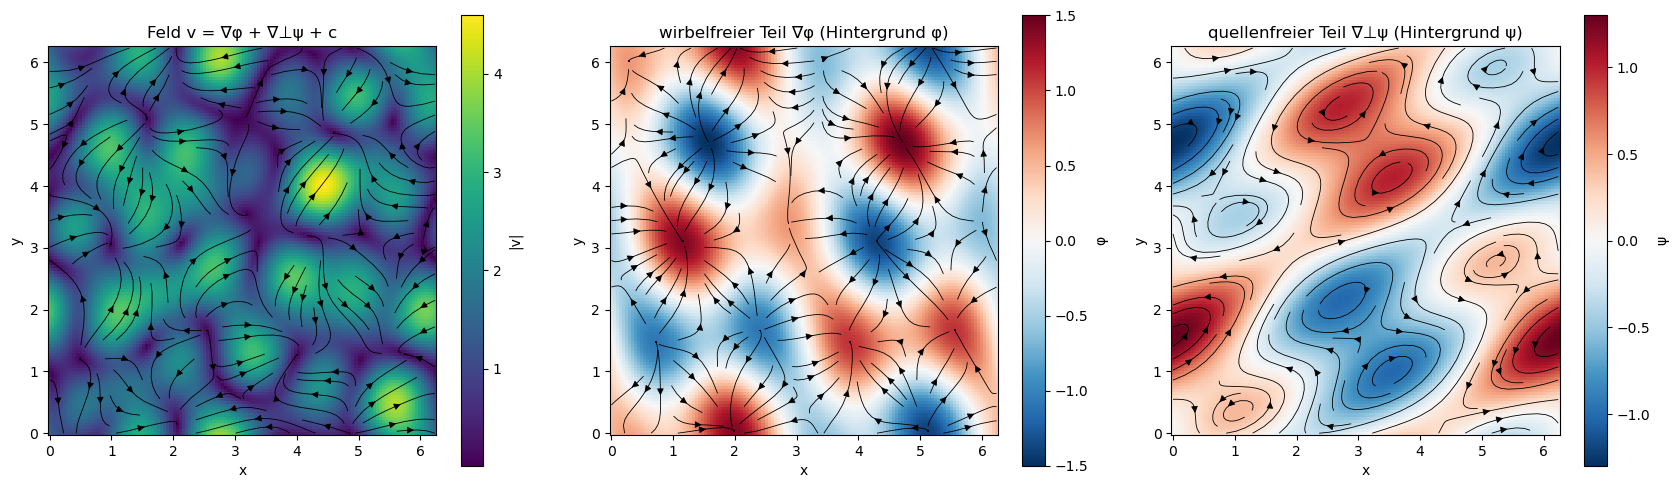

In [10]:
n9 = 128
s9 = 2 * np.pi * np.arange(n9) / n9
XX, YY = np.meshgrid(s9, s9, indexing="ij")
phi9 = np.sin(XX) * np.cos(2 * YY) + 0.5 * np.cos(3 * XX + YY)
psi9 = np.cos(XX) * np.sin(YY) + 0.3 * np.sin(2 * XX - 3 * YY)
g9 = np.array([np.cos(XX) * np.cos(2 * YY) - 1.5 * np.sin(3 * XX + YY),            # ∇φ
               -2 * np.sin(XX) * np.sin(2 * YY) - 0.5 * np.sin(3 * XX + YY)])
w9 = np.array([np.cos(XX) * np.cos(YY) - 0.9 * np.cos(2 * XX - 3 * YY),            # (∂yψ, −∂xψ)
               np.sin(XX) * np.sin(YY) - 0.6 * np.cos(2 * XX - 3 * YY)])
c9 = np.array([0.2, -0.1])
v9 = g9 + w9 + c9[:, None, None]

k9 = np.fft.fftfreq(n9, 1 / n9)                                  # ganzzahlige Wellenzahlen
KX, KY = np.meshgrid(k9, k9, indexing="ij")
K2 = KX**2 + KY**2
K2[0, 0] = 1.0
vh = np.fft.fft2(v9, axes=(1, 2))
kv = (KX * vh[0] + KY * vh[1]) / K2                              # (k·v̂)/k²
gh = np.array([KX * kv, KY * kv]); gh[:, 0, 0] = 0
wh = vh - gh; wh[:, 0, 0] = 0
g_rek, w_rek = np.fft.ifft2(gh, axes=(1, 2)).real, np.fft.ifft2(wh, axes=(1, 2)).real
c_rek = vh[:, 0, 0].real / n9**2
phi_rek = np.fft.ifft2(-1j * kv).real                            # φ̂ = (k·v̂)/(i k²)
psi_rek = np.fft.ifft2((KY * wh[0] - KX * wh[1]) / (1j * K2)).real

spektral_div = lambda F: np.fft.ifft2(1j * KX * np.fft.fft2(F[0]) + 1j * KY * np.fft.fft2(F[1])).real
spektral_rot = lambda F: np.fft.ifft2(1j * KX * np.fft.fft2(F[1]) - 1j * KY * np.fft.fft2(F[0])).real
print(f"Gradiententeil: Abweichung vom Bauteil {np.max(np.abs(g_rek - g9)):.1e}, rot = {np.max(np.abs(spektral_rot(g_rek))):.1e}")
print(f"quellenfreier Teil: Abweichung {np.max(np.abs(w_rek - w9)):.1e}, div = {np.max(np.abs(spektral_div(w_rek))):.1e}")
print(f"Mittelwert {c_rek.round(12)}; φ und ψ bis auf Konstanten: {np.max(np.abs(phi_rek - phi9 + phi9.mean())):.1e},"
      f" {np.max(np.abs(psi_rek - psi9 + psi9.mean())):.1e}")
mittel = lambda F, G: np.mean(np.sum(F * G, axis=0))
print(f"⟨∇φ, ∇⊥ψ⟩ = {mittel(g_rek, w_rek):+.1e};  Mittelwert von |v|² = {mittel(v9, v9):.6f}"
      f" = {mittel(g_rek, g_rek):.6f} (Gradient) + {mittel(w_rek, w_rek):.6f} (quellenfrei) + {c_rek @ c_rek:.6f} (konstant)")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (titel, F, hinter, name) in zip(axes, [
        ("Feld v = ∇φ + ∇⊥ψ + c", v9, np.hypot(*v9), "|v|"),
        ("wirbelfreier Teil ∇φ (Hintergrund φ)", g_rek, phi_rek, "φ"),
        ("quellenfreier Teil ∇⊥ψ (Hintergrund ψ)", w_rek, psi_rek, "ψ")]):
    im = ax.pcolormesh(s9, s9, hinter.T, cmap="viridis" if name == "|v|" else "RdBu_r", shading="auto")
    fig.colorbar(im, ax=ax, label=name, shrink=0.85)
    ax.streamplot(s9, s9, F[0].T, F[1].T, color="k", density=1.0, linewidth=0.6)
    ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title(titel)
plt.tight_layout()
plt.show()

##### *10. Die Laplace-Gleichung: Mittelwert, Maximumprinzip und Irrfahrten*

Wie genau löst der 5-Punkte-Stern das Dirichlet-Problem $\Delta u = 0$ im Einheitsquadrat mit $u = \sin\pi x$ am oberen Rand (und $0$ an den anderen), hat die Lösung die Mittelwerteigenschaft, liegt ihr Maximum auf dem Rand, und kann man $u$ an einem Punkt mit Irrfahrten schätzen, die bis zum Rand laufen? Die exakte Lösung ist $u = \sin(\pi x)\sinh(\pi y)/\sinh\pi$. Vorher vorhersagen: Um wie viel ist der Kreismittelwert von $x^2 + y^2$ größer als der Wert im Mittelpunkt?

n =   7, h = 0.1250: größter Fehler 4.32e-03, max u innen = 0.6770 (Rand: max 1), min u = 1.4e-02
n =  15, h = 0.0625: größter Fehler 1.11e-03, max u innen = 0.8215 (Rand: max 1), min u = 3.4e-03
n =  31, h = 0.0312: größter Fehler 2.78e-04, max u innen = 0.9062 (Rand: max 1), min u = 8.4e-04
n =  63, h = 0.0156: größter Fehler 6.96e-05, max u innen = 0.9519 (Rand: max 1), min u = 2.1e-04
n = 127, h = 0.0078: größter Fehler 1.74e-05, max u innen = 0.9757 (Rand: max 1), min u = 5.2e-05
u (harmonisch)  : Mittel auf dem Kreis r = 0.3 um (0.5, 0.5) = 0.199268407669, Wert im Mittelpunkt = 0.199268407669
x² + y² (Δ = 4) : Mittel auf dem Kreis r = 0.3 um (0.5, 0.5) = 0.590000000000, Wert im Mittelpunkt = 0.500000000000


Irrfahrten (20000): u(0.5, 0.5) ≈ 0.2023 ± 0.0026; Gitterlösung 0.1995; exakt 0.1993


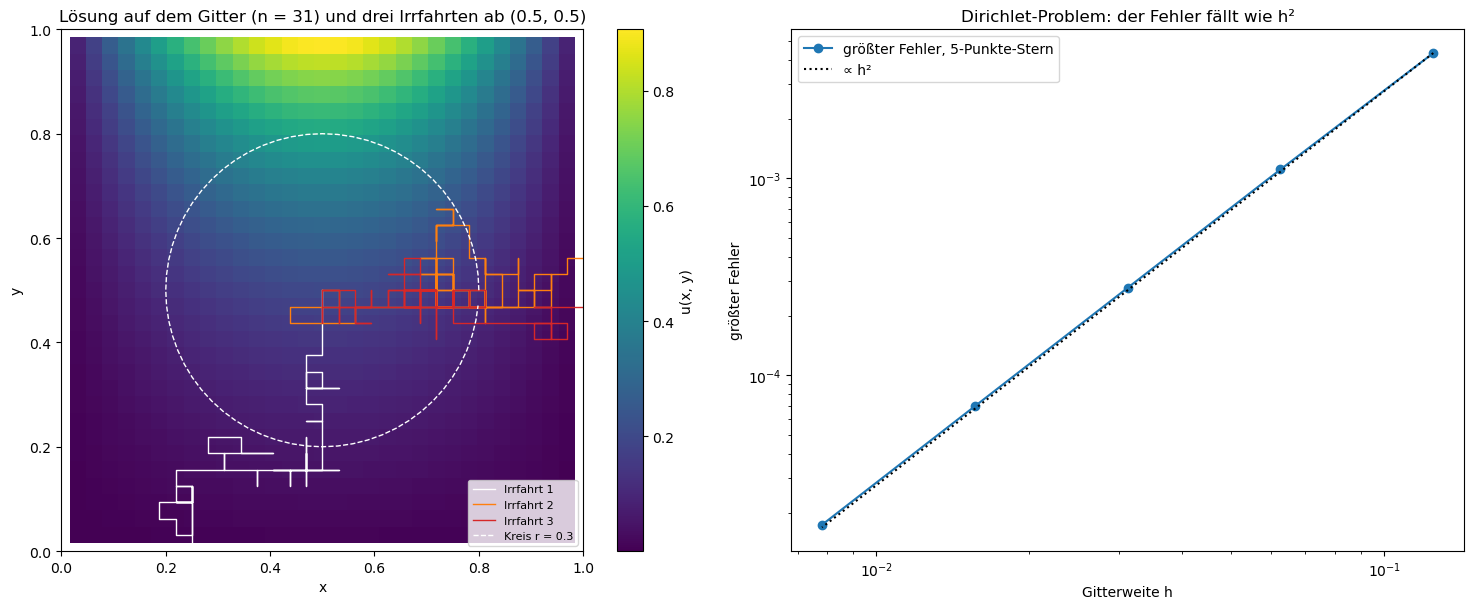

In [11]:
def laplace_dirichlet(n, rand_oben):
    """Δu = 0 im Einheitsquadrat, u = rand_oben(x) auf y = 1, sonst 0; n innere Punkte pro Richtung,
    5-Punkte-Stern, Index (i, j) ↔ (x_i, y_j)."""
    h = 1 / (n + 1)
    s = np.linspace(h, 1 - h, n)
    T = sps.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n))
    L = (sps.kron(T, sps.identity(n)) + sps.kron(sps.identity(n), T)) / h**2
    b = np.zeros((n, n))
    b[:, -1] -= rand_oben(s) / h**2
    return s, spsl.spsolve(L.tocsc(), b.ravel()).reshape(n, n)


u_ex = lambda X, Y: np.sin(np.pi * X) * np.sinh(np.pi * Y) / np.sinh(np.pi)
ns10, fehler10 = [7, 15, 31, 63, 127], []
for n in ns10:
    s, u = laplace_dirichlet(n, lambda t: np.sin(np.pi * t))
    XX, YY = np.meshgrid(s, s, indexing="ij")
    fehler10.append(np.max(np.abs(u - u_ex(XX, YY))))
    print(f"n = {n:3d}, h = {1 / (n + 1):.4f}: größter Fehler {fehler10[-1]:.2e}, max u innen = {u.max():.4f} (Rand: max 1), min u = {u.min():.1e}")

tt = 2 * np.pi * np.arange(64) / 64
for name, g in [("u (harmonisch)", u_ex), ("x² + y² (Δ = 4)", lambda X, Y: X**2 + Y**2)]:
    kreis = g(0.5 + 0.3 * np.cos(tt), 0.5 + 0.3 * np.sin(tt)).mean()
    print(f"{name:16s}: Mittel auf dem Kreis r = 0.3 um (0.5, 0.5) = {kreis:.12f}, Wert im Mittelpunkt = {g(0.5, 0.5):.12f}")

# Irrfahrten auf dem Gitter n = 31 (h = 1/32) ab (0.5, 0.5); der Wert am Austrittspunkt wird gemittelt
n_rw, W_rw = 31, 20000
s_rw, u_rw = laplace_dirichlet(n_rw, lambda t: np.sin(np.pi * t))
pos = np.full((W_rw, 2), n_rw // 2)
aktiv = np.ones(W_rw, bool)
schritte = np.array([[1, 0], [-1, 0], [0, 1], [0, -1]])
pfade = [[pos[k].copy()] for k in range(3)]
while aktiv.any():
    idx = np.flatnonzero(aktiv)
    pos[idx] += schritte[rng.integers(0, 4, idx.size)]
    for k in range(3):
        if aktiv[k]:
            pfade[k].append(pos[k].copy())
    aktiv[idx] = np.all((pos[idx] >= 0) & (pos[idx] < n_rw), axis=1)
werte_rw = np.where(pos[:, 1] == n_rw, np.sin(np.pi * (pos[:, 0] + 1) / (n_rw + 1)), 0.0)
print(f"Irrfahrten ({W_rw}): u(0.5, 0.5) ≈ {werte_rw.mean():.4f} ± {werte_rw.std() / np.sqrt(W_rw):.4f};"
      f" Gitterlösung {u_rw[n_rw // 2, n_rw // 2]:.4f}; exakt {u_ex(0.5, 0.5):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ax = axes[0]
im = ax.pcolormesh(s_rw, s_rw, u_rw.T, cmap="viridis", shading="auto")
fig.colorbar(im, ax=ax, label="u(x, y)")
for k, pfad in enumerate(pfade):
    pfad = (np.array(pfad) + 1) / (n_rw + 1)
    ax.plot(pfad[:, 0], pfad[:, 1], lw=1, color=["w", "tab:orange", "tab:red"][k], label=f"Irrfahrt {k + 1}")
ax.plot(0.5 + 0.3 * np.cos(tt), 0.5 + 0.3 * np.sin(tt), "w--", lw=1, label="Kreis r = 0.3")
ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="lower right", fontsize=8); ax.set_title("Lösung auf dem Gitter (n = 31) und drei Irrfahrten ab (0.5, 0.5)")
ax = axes[1]
hs10 = 1 / (np.array(ns10) + 1)
ax.loglog(hs10, fehler10, "o-", label="größter Fehler, 5-Punkte-Stern")
ax.loglog(hs10, fehler10[0] * (hs10 / hs10[0]) ** 2, "k:", label="∝ h²")
ax.set_xlabel("Gitterweite h"); ax.set_ylabel("größter Fehler"); ax.legend()
ax.set_title("Dirichlet-Problem: der Fehler fällt wie h²")
plt.tight_layout()
plt.show()

##### *11. Fluss, Volumen und die Divergenz in hohen Dimensionen*

Wie ändert sich die Fläche eines Tropfens, der mit einem Fluss im Phasenraum mitschwimmt? Erwartet wird $\tfrac d{dt}\ln J = \nabla\cdot\mathbf v$ für die Jacobi-Determinante $J$: Beim Pendel ohne Reibung ($\nabla\cdot\mathbf v = 0$) bleibt die Fläche gleich (Liouville), mit Reibung $\gamma$ schrumpft sie wie $e^{-\gamma t}$, und beim Van-der-Pol-Oszillator, dessen Divergenz $\mu(1 - x^2)$ sich entlang der Bahn ändert, folgt $\ln J$ dem Integral der Divergenz. Danach: Wie schätzt man $\nabla\cdot\mathbf v = \mathrm{tr}\,D\mathbf v$ in $d = 100$ Dimensionen, ohne die Jacobi-Matrix aufzustellen (Hutchinson, wie in kontinuierlichen Normalizing Flows)? Vorher vorhersagen: Welche Zufallsvektoren geben die kleinere Varianz, Gauß oder Rademacher ($\pm1$)?

Pendel, γ = 0.0: Fläche/Anfangsfläche bei t = 8: 0.99999990, e^(−γt) = 1.00000000; größte Abweichung über t = 0, 1, …, 8: 9.9e-08
Pendel, γ = 0.25: Fläche/Anfangsfläche bei t = 8: 0.13533528, e^(−γt) = 0.13533528; größte Abweichung über t = 0, 1, …, 8: 1.6e-08
Van der Pol (μ = 1): größte Abweichung |ln det J − ∫div v dt| bis t = 15: 6.4e-11
div v exakt (Spur der Jacobi-Matrix) = 56.293751; εᵀJε aus zwei Auswertungen von v: 57.675931, mit der Matrix: 57.675931


Gauß      : Standardabweichung einer Probe gemessen 10.580, Theorie √Var = 10.695; relativer Fehler mit k = 16 Proben 4.7%
Rademacher: Standardabweichung einer Probe gemessen 1.754, Theorie √Var = 1.750; relativer Fehler mit k = 16 Proben 0.8%


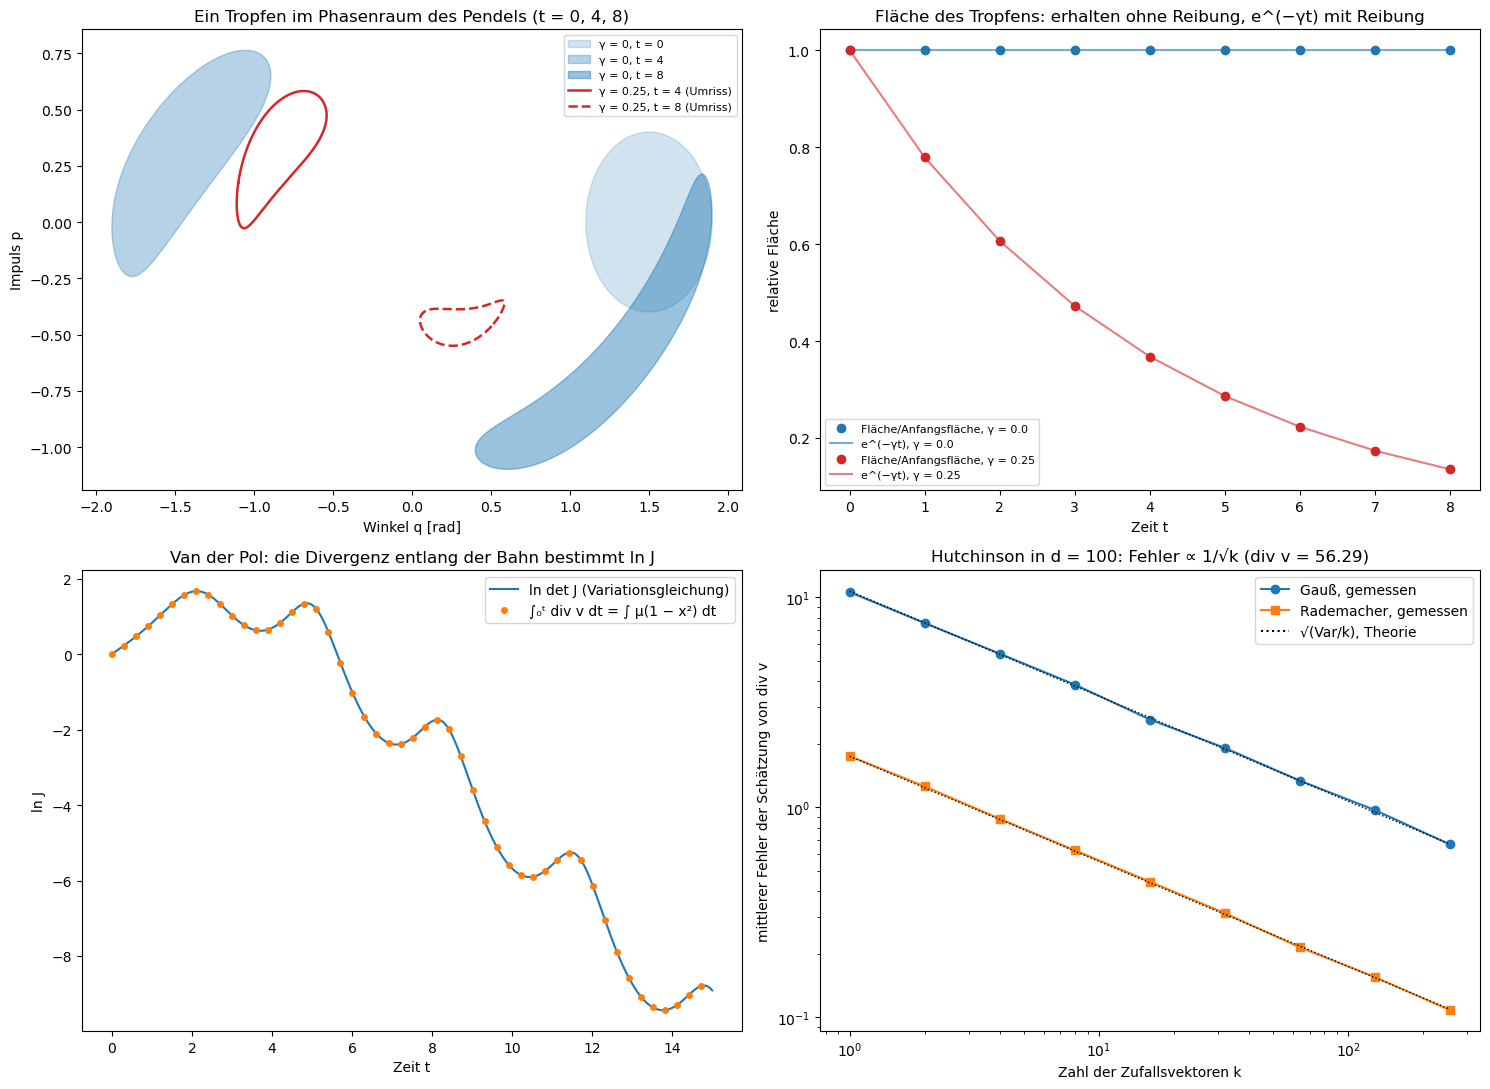

In [12]:
pendel = lambda Q, gam=0.0: np.array([Q[1], -np.sin(Q[0]) - gam * Q[1]])
t11 = np.linspace(0, 8, 9)
rand0 = np.array([1.5, 0.0])[:, None] + 0.4 * np.array([np.cos(2 * np.pi * np.arange(4000) / 4000),
                                                         np.sin(2 * np.pi * np.arange(4000) / 4000)])
tropfen = {}
for gam in [0.0, 0.25]:
    los = solve_ivp(lambda t, Y: pendel(Y.reshape(2, -1), gam).ravel(), (0, 8), rand0.ravel(), t_eval=t11,
                    rtol=1e-10, atol=1e-12)
    tropfen[gam] = los.y.reshape(2, -1, len(t11))
    A = np.array([schnuersenkel(*tropfen[gam][:, :, k]) for k in range(len(t11))])
    print(f"Pendel, γ = {gam}: Fläche/Anfangsfläche bei t = 8: {A[-1] / A[0]:.8f}, e^(−γt) = {np.exp(-gam * 8):.8f};"
          f" größte Abweichung über t = 0, 1, …, 8: {np.max(np.abs(A / A[0] - np.exp(-gam * t11))):.1e}")

# Van der Pol: Zustand, Jacobi-Matrix (Variationsgleichung) und ∫div v dt gemeinsam integrieren
mu = 1.0
def vdp_mit_jacobi(t, Y):
    q, p, J = Y[0], Y[1], Y[2:6].reshape(2, 2)
    Dv = np.array([[0, 1], [-1 - 2 * mu * q * p, mu * (1 - q**2)]])
    return np.concatenate([[p, mu * (1 - q**2) * p - q], (Dv @ J).ravel(), [mu * (1 - q**2)]])
tv = np.linspace(0, 15, 600)
los = solve_ivp(vdp_mit_jacobi, (0, 15), [0.5, 0, 1, 0, 0, 1, 0], t_eval=tv, rtol=1e-11, atol=1e-12)
ln_detJ = np.log(np.abs([np.linalg.det(los.y[2:6, k].reshape(2, 2)) for k in range(len(tv))]))
print(f"Van der Pol (μ = 1): größte Abweichung |ln det J − ∫div v dt| bis t = 15: {np.max(np.abs(ln_detJ - los.y[6])):.1e}")

# Hutchinson: div v = tr J = E[εᵀJε] für E[εεᵀ] = 1, v(x) = tanh(Wx + b) in d = 100, W mit großer Diagonale
d = 100
W = np.diag(rng.uniform(0.5, 2.0, d)) + 0.3 * rng.normal(size=(d, d)) / np.sqrt(d)
b = rng.normal(size=d)
v_nn = lambda X: np.tanh(W @ X + b)
x0 = rng.normal(size=d)
Jnn = (1 - v_nn(x0) ** 2)[:, None] * W
div_exakt = np.trace(Jnn)
eps = rng.choice([-1.0, 1.0], size=d)
jvp = (v_nn(x0 + 1e-5 * eps) - v_nn(x0 - 1e-5 * eps)) / 2e-5        # Jε aus zwei Auswertungen von v
print(f"div v exakt (Spur der Jacobi-Matrix) = {div_exakt:.6f}; εᵀJε aus zwei Auswertungen von v: {eps @ jvp:.6f},"
      f" mit der Matrix: {eps @ Jnn @ eps:.6f}")
Js = (Jnn + Jnn.T) / 2
var_theo = {"Gauß": 2 * np.sum(Js**2), "Rademacher": 2 * (np.sum(Js**2) - np.sum(np.diag(Js) ** 2))}
ks = 2 ** np.arange(0, 9)
rmse = {"Gauß": [], "Rademacher": []}
for k in ks:
    for art in rmse:
        E = rng.normal(size=(2000, k, d)) if art == "Gauß" else rng.choice([-1.0, 1.0], size=(2000, k, d))
        schaetzung = np.einsum("rki,ij,rkj->r", E, Jnn, E) / k
        rmse[art].append(np.sqrt(np.mean((schaetzung - div_exakt) ** 2)))
for art in rmse:
    print(f"{art:10s}: Standardabweichung einer Probe gemessen {rmse[art][0]:.3f}, Theorie √Var = {np.sqrt(var_theo[art]):.3f};"
          f" relativer Fehler mit k = 16 Proben {rmse[art][4] / abs(div_exakt):.1%}")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ax = axes[0, 0]
for k in [0, 4, 8]:
    P = tropfen[0.0][:, :, k]
    ax.fill(P[0], P[1], color="tab:blue", alpha=0.2 + 0.25 * k / 8, label=f"γ = 0, t = {t11[k]:.0f}")
for k, ls in [(4, "-"), (8, "--")]:
    P = tropfen[0.25][:, :, k]
    ax.plot(P[0], P[1], color="tab:red", lw=1.8, ls=ls, label=f"γ = 0.25, t = {t11[k]:.0f} (Umriss)")
ax.set_xlabel("Winkel q [rad]"); ax.set_ylabel("Impuls p"); ax.legend(fontsize=8)
ax.set_title("Ein Tropfen im Phasenraum des Pendels (t = 0, 4, 8)")
ax = axes[0, 1]
for gam, farbe in [(0.0, "tab:blue"), (0.25, "tab:red")]:
    A = np.array([schnuersenkel(*tropfen[gam][:, :, k]) for k in range(len(t11))])
    ax.plot(t11, A / A[0], "o", color=farbe, label=f"Fläche/Anfangsfläche, γ = {gam}")
    ax.plot(t11, np.exp(-gam * t11), "-", color=farbe, alpha=0.6, label=f"e^(−γt), γ = {gam}")
ax.set_xlabel("Zeit t"); ax.set_ylabel("relative Fläche"); ax.legend(fontsize=8)
ax.set_title("Fläche des Tropfens: erhalten ohne Reibung, e^(−γt) mit Reibung")
ax = axes[1, 0]
ax.plot(tv, ln_detJ, label="ln det J (Variationsgleichung)")
ax.plot(tv[::12], los.y[6, ::12], "o", ms=4, label="∫₀ᵗ div v dt = ∫ μ(1 − x²) dt")
ax.set_xlabel("Zeit t"); ax.set_ylabel("ln J"); ax.legend()
ax.set_title("Van der Pol: die Divergenz entlang der Bahn bestimmt ln J")
ax = axes[1, 1]
for art, m in [("Gauß", "o-"), ("Rademacher", "s-")]:
    ax.loglog(ks, rmse[art], m, label=f"{art}, gemessen")
    ax.loglog(ks, np.sqrt(var_theo[art] / ks), "k:", lw=1)
ax.plot([], [], "k:", label="√(Var/k), Theorie")
ax.set_xlabel("Zahl der Zufallsvektoren k"); ax.set_ylabel("mittlerer Fehler der Schätzung von div v")
ax.set_title(f"Hutchinson in d = {d}: Fehler ∝ 1/√k (div v = {div_exakt:.2f})"); ax.legend()
plt.tight_layout()
plt.show()

##### *12. Magnetfeld einer Leiterschleife: Biot–Savart, $\nabla\cdot\mathbf B = 0$ und Ampère*

Stimmt das aus dem Biot–Savart-Gesetz berechnete Feld einer kreisförmigen Stromschleife (Radius 1, Strom $I$, Einheiten mit $\mu_0I = 1$) auf der Achse mit der Formel $B_z = \frac1{2(1 + z^2)^{3/2}}$ überein, ist es quellenfrei, und ergibt $\oint\mathbf B\cdot d\mathbf l$ auf geschlossenen Wegen den umschlossenen Strom? Vorher vorhersagen: Was ergibt ein Weg, der den Draht an beiden Stellen umschließt, an denen er die $xz$-Ebene durchstößt?

Achse: größte Abweichung von 1/(2(1 + z²)^(3/2)): 2.3e-15, größte Querkomponente 1.0e-17
div B an 100 Punkten: größter Betrag 4.5e-08, typische Größe einer einzelnen Ableitung ∂B_z/∂z: 2.8e-02
Ampère, Kreis r = 0.3 um (1, 0, 0): ∮ B·dl = +1.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 0.8 um (1, 0, 0): ∮ B·dl = +1.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 0.3 um (2, 0, 0): ∮ B·dl = +0.000000000  (in Einheiten von μ0 I)
Ampère, Kreis r = 1.5 um (0, 0, 0): ∮ B·dl = +0.000000000  (in Einheiten von μ0 I)


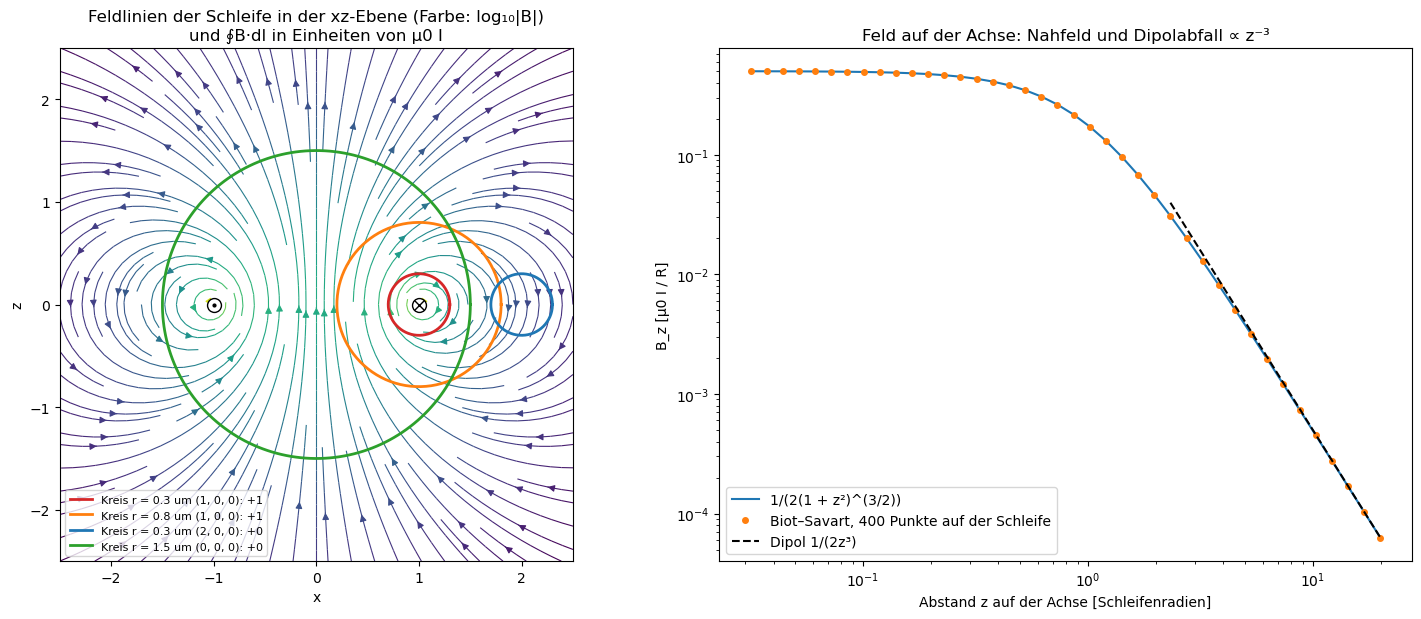

In [13]:
def biot_savart(P, n=400, block=2000):
    """B(P) für die Schleife r'(t) = (cos t, sin t, 0) mit μ0 I = 1: B = (1/4π) ∮ dl × (P − r')/|P − r'|³.
    P hat die Form (3, ...); Trapezregel mit n Punkten auf der Schleife."""
    t = 2 * np.pi * np.arange(n) / n
    rq = np.array([np.cos(t), np.sin(t), np.zeros(n)])
    dl = np.array([-np.sin(t), np.cos(t), np.zeros(n)]) * 2 * np.pi / n
    form = P.shape[1:]
    P = P.reshape(3, -1)
    B = np.empty_like(P, dtype=float)
    for a in range(0, P.shape[1], block):
        d = P[:, a:a + block, None] - rq[:, None, :]
        B[:, a:a + block] = np.sum(np.cross(dl[:, None, :], d, axis=0) / np.sum(d**2, axis=0) ** 1.5, axis=2) / (4 * np.pi)
    return B.reshape(3, *form)


zs = np.linspace(-3, 3, 13)
B_achse = biot_savart(np.array([np.zeros_like(zs), np.zeros_like(zs), zs]))
print(f"Achse: größte Abweichung von 1/(2(1 + z²)^(3/2)): {np.max(np.abs(B_achse[2] - 0.5 / (1 + zs**2) ** 1.5)):.1e},"
      f" größte Querkomponente {np.max(np.abs(B_achse[:2])):.1e}")

# div B mit zentralen Differenzen an zufälligen Punkten mit Abstand ≥ 0.3 vom Draht
punkte = rng.uniform(-2, 2, size=(3, 400))
abstand_draht = np.hypot(np.hypot(punkte[0], punkte[1]) - 1, punkte[2])
punkte = punkte[:, abstand_draht > 0.3][:, :100]
hb = 1e-4
divB = sum((biot_savart(punkte + hb * np.eye(3)[a][:, None])[a] - biot_savart(punkte - hb * np.eye(3)[a][:, None])[a]) / (2 * hb)
           for a in range(3))
dBz = (biot_savart(punkte + hb * np.eye(3)[2][:, None])[2] - biot_savart(punkte - hb * np.eye(3)[2][:, None])[2]) / (2 * hb)
print(f"div B an 100 Punkten: größter Betrag {np.max(np.abs(divB)):.1e}, typische Größe einer einzelnen Ableitung ∂B_z/∂z: {np.median(np.abs(dBz)):.1e}")

wege12 = {   # geschlossene Wege in der xz-Ebene; der Draht durchstößt sie bei x = +1 (Strom in +y) und x = −1 (Strom in −y)
    "Kreis r = 0.3 um (1, 0, 0)": ((1, 0.3)),
    "Kreis r = 0.8 um (1, 0, 0)": ((1, 0.8)),
    "Kreis r = 0.3 um (2, 0, 0)": ((2, 0.3)),
    "Kreis r = 1.5 um (0, 0, 0)": ((0, 1.5)),
}
ampere = {}
for name, (mx, R) in wege12.items():
    r = lambda t: np.array([mx + R * np.cos(t), np.zeros_like(t), -R * np.sin(t)])
    dr = lambda t: np.array([-R * np.sin(t), np.zeros_like(t), -R * np.cos(t)])
    ampere[name] = kurvenintegral(lambda X, Y, Z: biot_savart(np.array([X, Y, Z])), r, dr, n=400)
    print(f"Ampère, {name}: ∮ B·dl = {round(ampere[name], 9) + 0.0:+.9f}  (in Einheiten von μ0 I)")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
ax = axes[0]
s12 = np.linspace(-2.5, 2.5, 120)                              # gerade Anzahl: kein Gitterpunkt auf dem Draht
XX, ZZ = np.meshgrid(s12, s12)
Bxz = biot_savart(np.array([XX, np.zeros_like(XX), ZZ]))
ax.streamplot(s12, s12, Bxz[0], Bxz[2], color=np.log10(np.hypot(Bxz[0], Bxz[2])), cmap="viridis", density=1.5, linewidth=0.8)
# y zeigt in die Bildebene hinein: bei x = +1 fließt der Strom hinein (⊗), bei x = −1 heraus (⊙)
ax.plot([1], [0], "o", ms=10, mfc="w", mec="k"); ax.plot([1], [0], "kx", ms=7)
ax.plot([-1], [0], "o", ms=10, mfc="w", mec="k"); ax.plot([-1], [0], "k.", ms=4)
tt = np.linspace(0, 2 * np.pi, 200)
for (name, (mx, R)), farbe in zip(wege12.items(), ["tab:red", "tab:orange", "tab:blue", "tab:green"]):
    ax.plot(mx + R * np.cos(tt), R * np.sin(tt), color=farbe, lw=2, label=f"{name}: {round(ampere[name], 6) + 0.0:+.0f}")
ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("z"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Feldlinien der Schleife in der xz-Ebene (Farbe: log₁₀|B|)\nund ∮B·dl in Einheiten von μ0 I")
ax = axes[1]
zz = np.logspace(-1.5, 1.3, 40)
Bz = biot_savart(np.array([np.zeros_like(zz), np.zeros_like(zz), zz]))[2]
ax.loglog(zz, 0.5 / (1 + zz**2) ** 1.5, label="1/(2(1 + z²)^(3/2))")
ax.loglog(zz, Bz, "o", ms=4, label="Biot–Savart, 400 Punkte auf der Schleife")
ax.loglog(zz[zz > 2], 0.5 / zz[zz > 2] ** 3, "k--", label="Dipol 1/(2z³)")
ax.set_xlabel("Abstand z auf der Achse [Schleifenradien]"); ax.set_ylabel("B_z [μ0 I / R]")
ax.set_title("Feld auf der Achse: Nahfeld und Dipolabfall ∝ z⁻³"); ax.legend()
plt.tight_layout()
plt.show()

##### *13. Wahrscheinlichkeitsstrom und quantisierte Wirbel*

Erfüllt die Dichte $\rho = \vert\psi\vert^2$ eines zeitabhängigen Zustands im 2D-Oszillator ($\hbar = m = \omega = 1$) die Kontinuitätsgleichung $\partial_t\rho + \nabla\cdot\mathbf j = 0$ mit $\mathbf j = \mathrm{Im}(\psi^\ast\nabla\psi)$? Und welche Zirkulation hat das Geschwindigkeitsfeld $\mathbf v = \mathbf j/\rho = \nabla\arg\psi$ um die Nullstellen von $\psi$? Das Feld ist außerhalb der Nullstellen rotationsfrei, wie der Potentialwirbel in Experiment 3. Vorher vorhersagen: Welche Werte kann $\frac1{2\pi}\oint\mathbf v\cdot d\mathbf l$ annehmen?

Kontinuitätsgleichung bei t = 0.7: max|∂ρ/∂t + div j| = 2.9e-04 bei max|∂ρ/∂t| = 0.41 (Gitter h = 0.02)
Nullstelle von ψ bei x + iy = −(a/b) e^(it): Radius a/b = 0.75, Umlaufzeit 2π
Zirkulation um z1            : ∮ v·dl / 2π = +1.000000000
Zirkulation um z2            : ∮ v·dl / 2π = +1.000000000
Zirkulation um z3 (z̄ − z̄3) : ∮ v·dl / 2π = -1.000000000
Zirkulation Kreis r = 2.5 um 0: ∮ v·dl / 2π = +1.000000000
Zirkulation um z1 und z3     : ∮ v·dl / 2π = +0.000000000


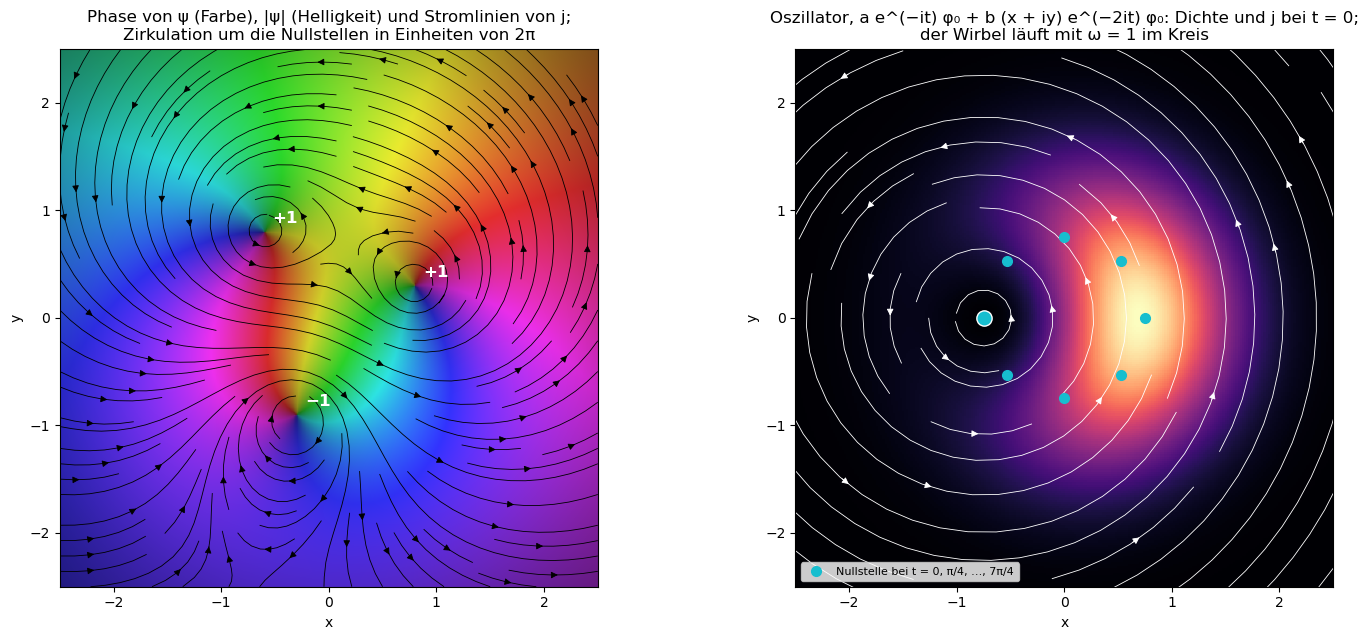

In [14]:
# Zeitabhängiger Zustand: ψ = e^(−r²/2) [a e^(−it) + b (x + iy) e^(−2it)], eine Überlagerung von E = 1 und E = 2
a13, b13 = 0.6, 0.8
psi13 = lambda X, Y, t: np.exp(-(X**2 + Y**2) / 2) * (a13 * np.exp(-1j * t) + b13 * (X + 1j * Y) * np.exp(-2j * t))
s13 = np.linspace(-4, 4, 401)
h13 = s13[1] - s13[0]
XX, YY = np.meshgrid(s13, s13, indexing="ij")


def strom(psi, h):
    """j = Im(ψ* ∇ψ) mit zentralen Differenzen."""
    return np.array([np.imag(np.conj(psi) * np.gradient(psi, h, axis=a)) for a in range(2)])


t0, dt = 0.7, 1e-4
drho_dt = (np.abs(psi13(XX, YY, t0 + dt)) ** 2 - np.abs(psi13(XX, YY, t0 - dt)) ** 2) / (2 * dt)
div_j = div_num(strom(psi13(XX, YY, t0), h13), h13)
print(f"Kontinuitätsgleichung bei t = {t0}: max|∂ρ/∂t + div j| = {np.max(np.abs(drho_dt + div_j)):.1e}"
      f" bei max|∂ρ/∂t| = {np.max(np.abs(drho_dt)):.2f} (Gitter h = {h13:.2f})")
print(f"Nullstelle von ψ bei x + iy = −(a/b) e^(it): Radius a/b = {a13 / b13:.2f}, Umlaufzeit 2π")

# Momentaufnahme mit drei Wirbeln: ψ = (z − z1)(z − z2)(z̄ − z̄3) e^(−|z|²/2)
z1, z2, z3 = 0.8 + 0.3j, -0.6 + 0.8j, -0.3 - 0.9j
psi_w = lambda X, Y: ((X + 1j * Y - z1) * (X + 1j * Y - z2) * np.conj(X + 1j * Y - z3)) * np.exp(-(X**2 + Y**2) / 2)
def v_w(X, Y):
    """v = Im(∇ψ/ψ) = ∇ arg ψ, exakt aus ln ψ = ln(z − z1) + ln(z − z2) + ln(z̄ − z̄3) − |z|²/2."""
    Z = X + 1j * Y
    dx = 1 / (Z - z1) + 1 / (Z - z2) + 1 / np.conj(Z - z3) - X
    dy = 1j / (Z - z1) + 1j / (Z - z2) - 1j / np.conj(Z - z3) - Y
    return np.array([dx.imag, dy.imag])
for name, (M, R) in {"um z1": (z1, 0.2), "um z2": (z2, 0.2), "um z3 (z̄ − z̄3)": (z3, 0.2), "Kreis r = 2.5 um 0": (0, 2.5),
                     "um z1 und z3": ((z1 + z3) / 2, 0.75)}.items():
    r = lambda t: np.array([M.real + R * np.cos(t), M.imag + R * np.sin(t)]) if isinstance(M, complex) else R * np.array([np.cos(t), np.sin(t)])
    dr = lambda t: R * np.array([-np.sin(t), np.cos(t)])
    print(f"Zirkulation {name:17s}: ∮ v·dl / 2π = {round(kurvenintegral(v_w, r, dr, n=800) / (2 * np.pi), 9) + 0.0:+.9f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
ax = axes[0]
s13b = np.linspace(-2.5, 2.5, 400)
XB, YB = np.meshgrid(s13b, s13b)
P = psi_w(XB, YB)
hell = np.clip(np.abs(P) / np.abs(P).max(), 0, 1) ** 0.5
ax.imshow(hsv_to_rgb(np.dstack([(np.angle(P) / (2 * np.pi)) % 1, 0.8 * np.ones_like(hell), 0.35 + 0.65 * hell])),
          extent=[-2.5, 2.5, -2.5, 2.5], origin="lower")
J = np.abs(P) ** 2 * v_w(XB, YB)
ax.streamplot(s13b, s13b, J[0], J[1], color="k", density=1.2, linewidth=0.6)
for zk, lab in [(z1, "+1"), (z2, "+1"), (z3, "−1")]:
    ax.annotate(lab, (zk.real, zk.imag), xytext=(6, 6), textcoords="offset points", color="w", fontsize=12, weight="bold")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_title("Phase von ψ (Farbe), |ψ| (Helligkeit) und Stromlinien von j;\nZirkulation um die Nullstellen in Einheiten von 2π")
ax = axes[1]
P0 = psi13(XX, YY, 0.0)
ax.pcolormesh(s13, s13, (np.abs(P0) ** 2).T, cmap="magma", shading="auto")
J0 = strom(P0, h13)
ax.streamplot(s13, s13, J0[0].T, J0[1].T, color="w", density=1.0, linewidth=0.6)
tb = np.linspace(0, 2 * np.pi, 9)[:-1]
knoten = -(a13 / b13) * np.exp(1j * tb)
ax.plot(knoten.real, knoten.imag, "o", color="tab:cyan", ms=7, label="Nullstelle bei t = 0, π/4, …, 7π/4")
ax.plot(knoten[0].real, knoten[0].imag, "o", color="tab:cyan", mec="w", ms=11)
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Oszillator, a e^(−it) φ₀ + b (x + iy) e^(−2it) φ₀: Dichte und j bei t = 0;\nder Wirbel läuft mit ω = 1 im Kreis")
plt.tight_layout()
plt.show()

##### *14. Berry-Krümmung: ein Monopol im Parameterraum*

Ein Spin im Magnetfeld $H = \mathbf R\cdot\boldsymbol\sigma$ wird langsam im Kreis geführt. Ist seine Berry-Phase die Hälfte des Raumwinkels, den $\mathbf R$ umläuft, ist die Berry-Krümmung das Feld $\hat{\mathbf R}/(2R^2)$ eines Monopols, und ist ihr Fluss durch eine Kugel um $\mathbf R = 0$ ein ganzzahliges Vielfaches von $2\pi$ (Chern-Zahl)? Gerechnet wird mit dem gitterbasierten Verfahren von Fukui, Hatsugai und Suzuki, das von der willkürlichen Phase der Eigenvektoren nicht abhängt; danach dieselbe Rechnung für Spin 1 und für das Qi–Wu–Zhang-Modell eines Chern-Isolators. Vorher vorhersagen: Welche Chern-Zahlen haben die drei Zustände eines Spin 1?

Spin ½: Chern-Zahlen der Zustände (nach Energie aufsteigend): [ 1. -1.]
  unterer Zustand: Berry-Fluss / Raumwinkel pro Plakette = 0.499943 ± 1.2e-04 → Krümmung R̂/(2R²), ein Monopol der Stärke ½
Spin 1: Chern-Zahlen der Zustände (nach Energie aufsteigend): [ 2.  0. -2.]
Berry-Phase gegen Ω/2 (mod 2π): größte Abweichung 2.5e-05
QWZ, unteres Band: Chern-Zahl für m = −2.5, −1, 1, 2.5: [0.0, 1.0, -1.0, 0.0]


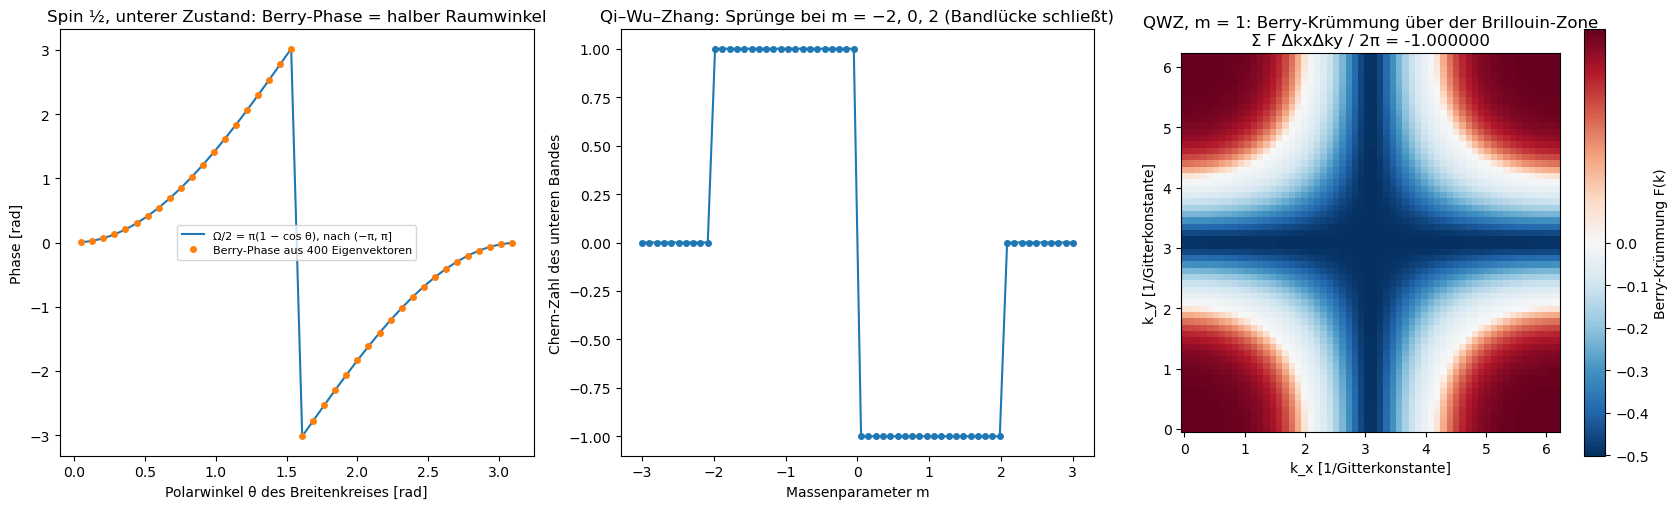

In [15]:
PAULI = [np.array([[0, 1], [1, 0]], complex), np.array([[0, -1j], [1j, 0]]), np.array([[1, 0], [0, -1]], complex)]
s_ = 1 / np.sqrt(2)
SPIN1 = [np.array([[0, s_, 0], [s_, 0, s_], [0, s_, 0]], complex), np.array([[0, -1j * s_, 0], [1j * s_, 0, -1j * s_], [0, 1j * s_, 0]]),
         np.diag([1.0, 0.0, -1.0]).astype(complex)]


def zustaende(H_von, gitter):
    """Eigenvektoren (nach Energie sortiert) auf einem Gitter von Parametern; Form (..., dim, dim)."""
    return np.linalg.eigh(H_von(*gitter))[1]


def plaketten_fluss(U, periodisch_erste=False):
    """Berry-Fluss durch jede Plakette (Fukui–Hatsugai–Suzuki): −arg des Produkts der vier Überlappungen.
    U[i, j] = Zustandsvektor; zweite Gitterrichtung periodisch."""
    U1 = np.roll(U, -1, axis=0) if periodisch_erste else U[1:]
    U0 = U if periodisch_erste else U[:-1]
    U2, U3 = np.roll(U1, -1, axis=1), np.roll(U0, -1, axis=1)
    ue = lambda A, B: np.sum(np.conj(A) * B, axis=-1)
    return -np.angle(ue(U0, U1) * ue(U1, U2) * ue(U2, U3) * ue(U3, U0))


H_kugel = lambda S: (lambda T, P: np.einsum("...,ab->...ab", np.sin(T) * np.cos(P), S[0])
                     + np.einsum("...,ab->...ab", np.sin(T) * np.sin(P), S[1]) + np.einsum("...,ab->...ab", np.cos(T), S[2]))
nt, np_ = 60, 120
TT, PP = np.meshgrid(np.linspace(0, np.pi, nt + 1), 2 * np.pi * np.arange(np_) / np_, indexing="ij")
for name, S in [("Spin ½", PAULI), ("Spin 1", SPIN1)]:
    V = zustaende(H_kugel(S), (TT, PP))
    cherns = [np.sum(plaketten_fluss(V[..., :, m])) / (2 * np.pi) for m in range(V.shape[-1])]
    print(f"{name}: Chern-Zahlen der Zustände (nach Energie aufsteigend): {np.round(cherns, 9) + 0.0}")
    if name == "Spin ½":
        F = plaketten_fluss(V[..., :, 0])
        raumwinkel = (np.cos(TT[:-1]) - np.cos(TT[1:])) * 2 * np.pi / np_   # Raumwinkel jeder Plakette
        print(f"  unterer Zustand: Berry-Fluss / Raumwinkel pro Plakette = {np.mean(F / raumwinkel):.6f} ± {np.std(F / raumwinkel):.1e}"
              f" → Krümmung R̂/(2R²), ein Monopol der Stärke ½")

# Berry-Phase eines Breitenkreises bei θ (unterer Zustand von Spin ½) gegen den halben Raumwinkel
thetas = np.linspace(0.05, np.pi - 0.05, 40)
phis = 2 * np.pi * np.arange(400) / 400
berry = []
for th in thetas:
    V = zustaende(H_kugel(PAULI), (np.full_like(phis, th), phis))[..., :, 0]
    berry.append(-np.angle(np.prod(np.sum(np.conj(V) * np.roll(V, -1, axis=0), axis=1))))
halber_raumwinkel = np.angle(np.exp(1j * np.pi * (1 - np.cos(thetas))))          # Ω/2 = π(1 − cos θ), nach (−π, π]
print(f"Berry-Phase gegen Ω/2 (mod 2π): größte Abweichung {np.max(np.abs(np.angle(np.exp(1j * (np.array(berry) - halber_raumwinkel))))):.1e}")

# Qi–Wu–Zhang: H(k) = sin kx σx + sin ky σy + (m + cos kx + cos ky) σz auf der Brillouin-Zone
nk = 60
KXq, KYq = np.meshgrid(2 * np.pi * np.arange(nk) / nk, 2 * np.pi * np.arange(nk) / nk, indexing="ij")
H_qwz = lambda m: (lambda KX, KY: np.einsum("...,ab->...ab", np.sin(KX), PAULI[0]) + np.einsum("...,ab->...ab", np.sin(KY), PAULI[1])
                   + np.einsum("...,ab->...ab", m + np.cos(KX) + np.cos(KY), PAULI[2]))
ms = np.linspace(-3, 3, 60)
chern_qwz = [np.sum(plaketten_fluss(zustaende(H_qwz(m), (KXq, KYq))[..., :, 0], periodisch_erste=True)) / (2 * np.pi) for m in ms]
print("QWZ, unteres Band: Chern-Zahl für m = −2.5, −1, 1, 2.5:",
      [round(np.sum(plaketten_fluss(zustaende(H_qwz(m), (KXq, KYq))[..., :, 0], periodisch_erste=True)) / (2 * np.pi), 9) + 0.0
       for m in (-2.5, -1, 1, 2.5)])

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
ax.plot(thetas, halber_raumwinkel, label="Ω/2 = π(1 − cos θ), nach (−π, π]")
ax.plot(thetas, berry, "o", ms=4, label="Berry-Phase aus 400 Eigenvektoren")
ax.set_xlabel("Polarwinkel θ des Breitenkreises [rad]"); ax.set_ylabel("Phase [rad]"); ax.legend(fontsize=8)
ax.set_title("Spin ½, unterer Zustand: Berry-Phase = halber Raumwinkel")
ax = axes[1]
ax.plot(ms, chern_qwz, "o-", ms=4)
ax.set_xlabel("Massenparameter m"); ax.set_ylabel("Chern-Zahl des unteren Bandes")
ax.set_title("Qi–Wu–Zhang: Sprünge bei m = −2, 0, 2 (Bandlücke schließt)")
ax = axes[2]
Fq = plaketten_fluss(zustaende(H_qwz(1.0), (KXq, KYq))[..., :, 0], periodisch_erste=True) / (2 * np.pi / nk) ** 2
im = ax.pcolormesh(KXq[:, 0], KYq[0], Fq.T, cmap="RdBu_r", norm=TwoSlopeNorm(0), shading="auto")
fig.colorbar(im, ax=ax, label="Berry-Krümmung F(k)")
ax.set_aspect("equal"); ax.set_xlabel("k_x [1/Gitterkonstante]"); ax.set_ylabel("k_y [1/Gitterkonstante]")
ax.set_title(f"QWZ, m = 1: Berry-Krümmung über der Brillouin-Zone\nΣ F ΔkxΔky / 2π = {np.sum(Fq) * (2 * np.pi / nk) ** 2 / (2 * np.pi):+.6f}")
plt.tight_layout()
plt.show()

#### **Ergebnis**

Beim Lauf vom 2026-10-19 (Laufzeit etwa 40 s):

- **Gradient:** $f = x\,e^{-x^2-y^2} + (x^2 + y^2)/20$ hat drei kritische Punkte: ein Minimum bei $(-0.669, 0)$, ein Maximum bei $(0.753, 0)$ und einen Sattel bei $(1.860, 0)$ mit den Hesse-Eigenwerten $-0.017$ und $+0.558$; den Sattel erzeugt erst die Schüssel. Entlang $(-\partial_yf, \partial_xf)$ bleibt $f$ auf $3\cdot10^{-13}$ konstant, der Gradientenfluss endet im Maximum, und die Richtungsableitung ist ein Kosinus mit dem Maximum $\vert\nabla f\vert = 0.443$ genau in Richtung $\arg\nabla f = 329°$.
- **Divergenz und Rotation:** Quelle $(2, 0)$, Wirbel $(0, 2)$, Scherung $(0, -1)$, Dehnung $(0, 0)$, Potentialwirbel $(0, 0)$ außerhalb des Ursprungs, Zellenströmung $(0, \cos x - \cos y)$, als (div, rot). Die zentralen Differenzen sind für lineare Felder exakt; beim Potentialwirbel ist der Fehler nahe $r = 0.3$ am größten ($0.1$), weil das Feld dort stark gekrümmt ist.
- **Kurvenintegrale:** $\int\nabla\varphi\cdot d\mathbf r = 2 + \sin2 = 2.9093$ auf allen drei Wegen; für $(-y, x)$ dagegen $0$, $\tfrac23$ und $0.309$. Der Potentialwirbel gibt $\oint/2\pi = +1, +1, 0, +2, -1$: genau die Umlaufzahl um den Ursprung.
- **Green:** Die Trapezregel für $\tfrac12\oint(x\,dy - y\,dx)$ erreicht die Fläche $\pi I_0(1) = 3.97746$ der Blume ab etwa 40 Punkten auf Maschinengenauigkeit, das eingeschriebene Polygon liegt mit 40 Ecken noch um $0.064$ daneben und konvergiert wie $N^{-2}$. Zirkulation und Fluss eines nichtlinearen Feldes stimmen auf 12 Stellen mit den Flächenintegralen von Rotation und Divergenz überein.
- **Gauß:** Der Fluss einer Punktladung ist $4\pi$ für jede Lage innerhalb von Kugel und Würfel und 0 außerhalb; beim Dipol $+4\pi$, $-4\pi$ und 0 um beide Ladungen. Je näher die Ladung der Oberfläche kommt, desto mehr Stützstellen braucht die Quadratur (Abstand 0.7: etwa 20, Abstand 0.03: etwa 120 für $10^{-13}$). Für $(x^3, y^3, z^3)$ sind Fluss und Volumenintegral $12\pi/5$ (Kugel) und 24 (Würfel).
- **Stokes:** Zirkulation $3\pi/2 = 4.712389$ und derselbe Fluss von $\nabla\times\mathbf F$ durch Kreisscheibe, Halbkugel, Paraboloid, nach unten gewölbte Schale und verbeulte Kappe, jeweils auf 12 Stellen; durch die geschlossene Kugel $-9\cdot10^{-14}$.
- **Krummlinige Koordinaten:** sympy findet die Metrik $\mathrm{diag}(1, r^2, r^2\sin^2\theta)$ und $\det = r^2\sin\theta$; die Kugelformel für $\Delta$ stimmt mit der kartesischen Rechnung überein, $\Delta r^n = n(n+1)r^{n-2}$, $\Delta\frac1r = 0$, $r^2\Delta Y_2^1 = -6\,Y_2^1$, $\nabla\times(\mathbf e_\varphi/\rho) = 0$, und die starre Drehung hat die Rotation $2\omega$. Der 7-Punkte-Stern auf dem Gitter ($h = 0.05$) trifft $(4r^2 - 6)e^{-r^2}$ auf $7.5\cdot10^{-3}$.
- **Identitäten:** Alle fünf symbolisch exakt. Auf dem Gitter bleiben $D\times Df$, $D\cdot(D\times\mathbf A)$ und $D\times D\times\mathbf A - D(D\cdot\mathbf A) + \sum_iD_iD_i\mathbf A$ bei jeder Gitterweite auf Rundungsniveau ($10^{-15}$); mit dem 3-Punkte-Stern fällt der Rest nur wie $h^2$ (1.3, 0.41, 0.11, 0.027 für $n = 12$ bis 96).
- **Helmholtz:** Die FFT-Projektion findet Gradiententeil, quellenfreien Teil, Mittelwert und die Potentiale $\varphi, \psi$ auf $10^{-15}$ wieder; die Teile sind orthogonal ($10^{-17}$), und das mittlere $\vert\mathbf v\vert^2 = 3.635$ teilt sich exakt in $2.5 + 1.085 + 0.05$.
- **Laplace:** Der Fehler des 5-Punkte-Sterns fällt wie $h^2$ (von $4.3\cdot10^{-3}$ bei $h = 1/8$ auf $1.7\cdot10^{-5}$ bei $h = 1/128$). Das Maximum im Inneren bleibt unter dem Randmaximum 1, das Minimum über 0. Der Kreismittelwert der harmonischen Lösung ist auf 12 Stellen gleich dem Wert im Mittelpunkt (0.199268), bei $x^2 + y^2$ um $r^2 = 0.09$ größer. 20 000 Irrfahrten geben $0.2023\pm0.0026$, die Gitterlösung $0.1995$, exakt ist $0.1993$.
- **Fluss und Volumen:** Ohne Reibung bleibt die Fläche des Tropfens bis $t = 8$ auf $10^{-7}$ erhalten, obwohl er sich stark verformt; mit $\gamma = 0.25$ folgt sie $e^{-\gamma t}$ auf $2\cdot10^{-8}$. Beim Van-der-Pol-Oszillator stimmt $\ln\det J$ auf $6\cdot10^{-11}$ mit $\int\mu(1 - x^2)\,dt$ überein, obwohl $\ln J$ steigt und fällt. Hutchinson in $d = 100$: Die Standardabweichung einer Probe ist $10.6$ (Gauß) gegen $1.75$ (Rademacher), wie die Formeln vorhersagen ($10.7$ und $1.75$), weil die Jacobi-Matrix eine große Diagonale hat; mit 16 Proben liegt der relative Fehler bei 4.7 % gegen 0.8 %, und beide fallen wie $1/\sqrt k$.
- **Leiterschleife:** Biot–Savart mit 400 Punkten trifft das Achsenfeld auf $2\cdot10^{-15}$ und geht in den Dipolabfall $1/(2z^3)$ über. $\nabla\cdot\mathbf B$ ist an 100 Punkten kleiner als $5\cdot10^{-8}$ bei Ableitungen der Größe $3\cdot10^{-2}$ (Fehler der Differenzen). Ampère: $\oint\mathbf B\cdot d\mathbf l = 1, 1, 0, 0$ (in $\mu_0I$) für einen kleinen und einen großen Kreis um den Draht, einen Kreis daneben und einen Kreis um beide Durchstoßpunkte.
- **Wahrscheinlichkeitsstrom:** $\partial_t\rho + \nabla\cdot\mathbf j$ ist auf dem Gitter mit $h = 0.02$ höchstens $3\cdot10^{-4}$ bei $\vert\partial_t\rho\vert$ bis $0.41$ (Fehler der Differenzen). Die Zirkulation um die drei Nullstellen ist $+1, +1, -1$ (in $2\pi$), um alle zusammen $+1$, um ein Paar mit entgegengesetzten Ladungen 0. Im Oszillator läuft die Nullstelle mit $\omega = 1$ auf dem Kreis vom Radius $a/b = 0.75$.
- **Berry-Krümmung:** Chern-Zahlen $+1, -1$ für Spin ½ und $2, 0, -2$ für Spin 1, jeweils ganzzahlig auf Rundungsniveau. Der Berry-Fluss pro Plakette geteilt durch ihren Raumwinkel ist $0.4999$: die Krümmung $\hat{\mathbf R}/(2R^2)$. Die Berry-Phase der Breitenkreise ist $\Omega/2$ auf $3\cdot10^{-5}$ (Diskretisierung mit 400 Punkten). Das QWZ-Modell hat $C = 0$ für $\vert m\vert>2$, $+1$ für $-2<m<0$ und $-1$ für $0<m<2$; die Sprünge liegen dort, wo sich die Bandlücke schließt.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Steilere Schüssel** (Experiment 1): $(x^2 + y^2)/5$ statt $/20$. Was passiert mit Maximum und Sattel? *(Vorhersage: Sie laufen aufeinander zu und verschwinden zusammen; übrig bleibt nur das Minimum.)*
2. **Wirbel mit Geschwindigkeit $\propto r^\alpha$** (Experiment 2): $\mathbf F = (-y, x)\,r^{\alpha - 1}$. Für welches $\alpha$ ist die Rotation null? *(Vorhersage: $\nabla\times\mathbf F = (\alpha + 1)\,r^{\alpha - 1}$, also nur für $\alpha = -1$, den Potentialwirbel.)*
3. **Zirkulation, die vom Radius abhängt** (Experiment 3): $(-y, x)/r^4$ auf Kreisen um den Ursprung. *(Vorhersage: $2\pi/R^2$, weil das Feld jetzt Rotation hat.)*
4. **Acht** (Experiment 4): Shoelace-Fläche der Lemniskate $(\sin t, \sin t\cos t)$. *(Vorhersage: 0, die beiden Schleifen werden in entgegengesetzter Richtung umlaufen.)*
5. **Ladung auf der Oberfläche** (Experiment 5): $\mathbf r_0 = (0, 0, 1)$. *(Vorhersage: Fluss $2\pi$, die Hälfte, weil die Ladung von der Fläche aus gesehen den Raumwinkel $2\pi$ hat; die Quadratur konvergiert langsam.)*
6. **Gradient addieren** (Experiment 6): $\mathbf F + \nabla(xyz^2)$. *(Vorhersage: Zirkulation und alle fünf Flüsse bleiben gleich.)*
7. **Harmonische Potenzen in Zylinderkoordinaten** (Experiment 7): Für welches $n$ ist $\rho^n$ harmonisch? *(Vorhersage: $\Delta\rho^n = n^2\rho^{n-2}$, nur $n = 0$; dazu $\ln\rho$.)*
8. **Zufallsfeld** (Experiment 9): Fourier-Koeffizienten beider Komponenten unabhängig gaußverteilt. Wie teilt sich die Energie auf? *(Vorhersage: im Mittel halb und halb, weil in zwei Dimensionen eine von zwei Richtungen longitudinal ist; in drei Dimensionen ein Drittel zu zwei Dritteln.)*
9. **Start nahe am Rand** (Experiment 10): Irrfahrten ab $(0.5, 0.9)$. *(Vorhersage: Schätzwert nahe $\sinh(0.9\pi)/\sinh\pi = 0.73$, und viel weniger Schritte bis zum Rand.)*
10. **Matrix ohne große Diagonale** (Experiment 11): $W$ nur aus dem Zufallsteil. *(Vorhersage: Gauß und Rademacher fast gleich gut, weil $\sum_iJ_{ii}^2$ nur ein kleiner Teil von $\Vert J_s\Vert_F^2$ ist.)*
11. **Helmholtz-Spule** (Experiment 12): Zwei Schleifen bei $z = \pm\tfrac12$. *(Vorhersage: In der Mitte verschwinden die Ableitungen von $B_z$ bis zur dritten Ordnung, das Feld ist dort besonders gleichmäßig.)*
12. **Doppelter Wirbel** (Experiment 13): $(z - z_1)^2$ statt $(z - z_1)$. *(Vorhersage: Zirkulation $2\cdot2\pi$; eine kleine Störung, etwa $+0.05$, spaltet ihn in zwei einfache Wirbel.)*
13. **Spin 3/2** (Experiment 14). *(Vorhersage: Chern-Zahlen $3, 1, -1, -3$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. In welche Richtung zeigt der Gradient, und wie groß ist die Richtungsableitung?</summary>

In die Richtung des steilsten Anstiegs, senkrecht zu den Höhenlinien. $D_{\mathbf u}f = \nabla f\cdot\mathbf u = \vert\nabla f\vert\cos\alpha$.
</details>

<details><summary>2. Was messen Divergenz und Rotation, ohne Koordinaten gesagt?</summary>

Divergenz: Nettofluss aus einem kleinen Volumen pro Volumen (Quellen). Rotation: Zirkulation um eine kleine Fläche pro Fläche (Wirbel), in Richtung der Flächennormale.
</details>

<details><summary>3. Hat die Scherströmung (y, 0) Rotation? Hat der Potentialwirbel (−y, x)/r² Rotation?</summary>

Die Scherströmung ja ($-1$), obwohl ihre Stromlinien gerade sind. Der Potentialwirbel außerhalb des Ursprungs nicht, obwohl seine Stromlinien Kreise sind; seine ganze Wirbelstärke sitzt im Ursprung.
</details>

<details><summary>4. Wann ist ein Feld mit ∇×F = 0 ein Gradientenfeld?</summary>

Auf einem einfach zusammenhängenden Gebiet immer (Lemma von Poincaré, Potential $\varphi(\mathbf x) = \int_0^1\mathbf F(t\mathbf x)\cdot\mathbf x\,dt$). Mit Loch nicht unbedingt: Der Potentialwirbel hat die Zirkulation $2\pi$ mal die Umlaufzahl.
</details>

<details><summary>5. Wie lauten die Sätze von Green, Stokes und Gauß, und was haben sie gemeinsam?</summary>

$\oint(P\,dx + Q\,dy) = \iint(\partial_xQ - \partial_yP)$, $\oint\mathbf F\cdot d\mathbf r = \iint(\nabla\times\mathbf F)\cdot d\mathbf A$, $\oint\mathbf F\cdot d\mathbf A = \iiint\nabla\cdot\mathbf F\,dV$. Alle sind $\int_Md\omega = \int_{\partial M}\omega$: Integral der Ableitung über das Gebiet = Integral über den Rand.
</details>

<details><summary>6. Wie bekommt man die Fläche eines Gebiets aus seinem Rand?</summary>

$A = \tfrac12\oint(x\,dy - y\,dx)$ (Green mit Rotation 1). Für ein Polygon: $\tfrac12\sum_k(x_ky_{k+1} - x_{k+1}y_k)$.
</details>

<details><summary>7. Warum ist der Fluss einer Punktladung durch jede umschließende Fläche 4πq?</summary>

$\nabla\cdot(\hat{\mathbf r}/r^2) = 0$ außerhalb der Ladung; nach Gauß ist der Fluss durch die Fläche gleich dem durch eine kleine Kugel, und dort ist er $q\cdot4\pi\varepsilon^2/\varepsilon^2$.
</details>

<details><summary>8. Warum ist der Fluss von ∇×F für alle Flächen mit demselben Rand gleich?</summary>

Zwei solche Flächen bilden eine geschlossene Fläche, und der Fluss von $\nabla\times\mathbf F$ durch sie ist $\iiint\nabla\cdot(\nabla\times\mathbf F) = 0$.
</details>

<details><summary>9. Wie lautet der Laplace-Operator einer radialen Funktion in drei Dimensionen, und welche Potenzen sind harmonisch?</summary>

$\Delta f = f'' + \frac2rf'$; $\Delta r^n = n(n+1)r^{n-2}$, harmonisch für $n = 0$ und $n = -1$ (das Coulomb-Potential).
</details>

<details><summary>10. Warum gilt div rot = 0 auch für zentrale Differenzen auf dem Gitter exakt, rot rot = grad div − Δ mit dem 3-Punkte-Stern aber nicht?</summary>

Die erste Identität braucht nur, dass Ableitungen nach verschiedenen Richtungen vertauschen, und das tun die Differenzenoperatoren auch. Die zweite braucht $\Delta = \sum_i\partial_i\partial_i$; diskret ist das $\sum_iD_iD_i$, nicht der 3-Punkte-Stern.
</details>

<details><summary>11. Was ist die Helmholtz-Zerlegung, und wie rechnet man sie im Fourier-Raum?</summary>

$\mathbf v = \nabla\varphi + \nabla\times\mathbf A\,(+\text{harmonisch})$. Im Fourier-Raum ist der Gradiententeil $\mathbf k(\mathbf k\cdot\hat{\mathbf v})/k^2$ (parallel zu $\mathbf k$), der quellenfreie Teil der Rest; beide sind orthogonal.
</details>

<details><summary>12. Welche Eigenschaften haben harmonische Funktionen, und was haben Irrfahrten damit zu tun?</summary>

Mittelwerteigenschaft und Maximumprinzip. Die Lösung des Dirichlet-Problems ist der Erwartungswert der Randwerte am Austrittspunkt einer Brownschen Bewegung, auf dem Gitter einer Irrfahrt.
</details>

<details><summary>13. Wie ändert ein Fluss Volumina, und was folgt daraus für Normalizing Flows?</summary>

$\frac d{dt}\ln J = \nabla\cdot\mathbf v$; bei $\nabla\cdot\mathbf v = 0$ bleibt das Volumen erhalten (Liouville). Entlang einer Bahn gilt $\frac d{dt}\ln p = -\nabla\cdot\mathbf v$, die Formel für die Dichte in kontinuierlichen Normalizing Flows.
</details>

<details><summary>14. Wie schätzt man eine Divergenz in hoher Dimension, und welche Zufallsvektoren sind besser?</summary>

Hutchinson: $\mathrm{tr}\,J = \mathbb E[\boldsymbol\varepsilon^TJ\boldsymbol\varepsilon]$ mit einem Jacobi-Vektor-Produkt pro Probe. Varianz $2\Vert J_s\Vert_F^2$ für Gauß, $2(\Vert J_s\Vert_F^2 - \sum J_{ii}^2)$ für Rademacher; Rademacher ist nie schlechter.
</details>

<details><summary>15. Warum ist die Zirkulation um eine Nullstelle einer Wellenfunktion quantisiert?</summary>

$\mathbf v = \frac\hbar m\nabla\arg\psi$, und $\psi$ ist eindeutig, also kann $\arg\psi$ bei einem Umlauf nur um $2\pi n$ springen.
</details>

<details><summary>16. Was ist die Berry-Krümmung eines Spin ½ im Feld, und was zählt die Chern-Zahl?</summary>

Das Feld eines Monopols der Stärke ½ am Entartungspunkt, $\hat{\mathbf R}/(2R^2)$; die Berry-Phase ist der halbe Raumwinkel. Die Chern-Zahl ist der Fluss durch eine geschlossene Fläche durch $2\pi$, eine ganze Zahl, die sich nur ändert, wenn eine Entartung (Schließen der Bandlücke) die Fläche kreuzt.
</details>

#### **Nächste Schritte**

- **Differentialformen:** äußere Ableitung, Hodge-Stern, de-Rham-Kohomologie (Löcher zählen mit geschlossenen, nicht exakten Formen wie $d\varphi$) und die Hodge-Zerlegung als allgemeine Helmholtz-Zerlegung; Vektoranalysis auf gekrümmten Räumen im Notebook [Tensor Analysis on Manifolds](https://github.com/deltorobarba/science/blob/main/maths/tensoranalysis.ipynb).
- **Strömungsmechanik:** Euler- und Navier–Stokes-Gleichungen, Vortizität, der Zirkulationssatz von Kelvin, Projektionsverfahren für inkompressible Strömungen.
- **Elektrodynamik:** retardierte Potentiale, elektromagnetische Wellen, Eichungen, Aharonov–Bohm-Effekt (eine Phase aus $\oint\mathbf A\cdot d\mathbf l$ dort, wo $\mathbf B = 0$ ist).
- **Numerik:** finite Volumen (Gauß auf jede Zelle), finite Elemente mit schwachen Formulierungen, Randelementmethoden mit der Green-Funktion, versetzte Gitter und diskreter äußerer Kalkül.
- **Maschinelles Lernen:** Score-basierte Diffusionsmodelle ($\nabla\ln p$, Fokker–Planck-Gleichung als Kontinuitätsgleichung mit Diffusion), Hamiltonsche neuronale Netze, physikinformierte Netze für partielle Differentialgleichungen.
- **Topologische Bänder:** Berry-Phase in Kristallen, Wannier-Funktionen, Kantenzustände von Chern-Isolatoren, Polarisation als Berry-Phase.

#### **Referenzen**

- H. M. Schey: *Div, Grad, Curl, and All That: An Informal Text on Vector Calculus*, 4. Aufl., Norton 2005.
- D. J. Griffiths: *Introduction to Electrodynamics*, 4. Aufl., Cambridge 2017, Kapitel 1 (1.2 Differentialrechnung, 1.3 Integralrechnung, 1.4 krummlinige Koordinaten, 1.5 Delta-Funktion, 1.6 Helmholtz-Theorem) und 5.2–5.3 (Biot–Savart, Divergenz und Rotation von $\mathbf B$).
- G. B. Arfken, H. J. Weber, F. E. Harris: *Mathematical Methods for Physicists*, 7. Aufl., Academic Press 2013, Kapitel 3 (Vektoranalysis, krummlinige Koordinaten).
- M. Spivak: *Calculus on Manifolds*, Benjamin 1965, Kapitel 4–5 (Differentialformen, Satz von Stokes).
- T. Needham: *Visual Differential Geometry and Forms*, Princeton 2021.
- G. Green: *An Essay on the Application of Mathematical Analysis to the Theories of Electricity and Magnetism*, Nottingham 1828.
- S. Kakutani: *Two-dimensional Brownian motion and harmonic functions*, Proc. Imp. Acad. Tokyo 20, 706 (1944).
- A. J. Chorin: *Numerical solution of the Navier–Stokes equations*, Math. Comp. 22, 745 (1968).
- K. S. Yee: *Numerical solution of initial boundary value problems involving Maxwell's equations in isotropic media*, IEEE Trans. Antennas Propag. 14, 302 (1966).
- M. F. Hutchinson: *A stochastic estimator of the trace of the influence matrix for Laplacian smoothing splines*, Commun. Stat. Simul. Comput. 18, 1059 (1989).
- R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud: *Neural ordinary differential equations*, NeurIPS 2018; W. Grathwohl, R. T. Q. Chen, J. Bettencourt, I. Sutskever, D. Duvenaud: *FFJORD: Free-form continuous dynamics for scalable reversible generative models*, ICLR 2019.
- A. Hyvärinen: *Estimation of non-normalized statistical models by score matching*, J. Mach. Learn. Res. 6, 695 (2005).
- E. Madelung: *Quantentheorie in hydrodynamischer Form*, Z. Phys. 40, 322 (1927).
- P. A. M. Dirac: *Quantised singularities in the electromagnetic field*, Proc. R. Soc. A 133, 60 (1931).
- M. V. Berry: *Quantal phase factors accompanying adiabatic changes*, Proc. R. Soc. A 392, 45 (1984).
- D. J. Thouless, M. Kohmoto, M. P. Nightingale, M. den Nijs: *Quantized Hall conductance in a two-dimensional periodic potential*, Phys. Rev. Lett. 49, 405 (1982).
- T. Fukui, Y. Hatsugai, H. Suzuki: *Chern numbers in discretized Brillouin zone*, J. Phys. Soc. Jpn. 74, 1674 (2005).
- X.-L. Qi, Y.-S. Wu, S.-C. Zhang: *Topological quantization of the spin Hall effect in two-dimensional paramagnetic semiconductors*, Phys. Rev. B 74, 085308 (2006).
- J. K. Asbóth, L. Oroszlány, A. Pályi: *A Short Course on Topological Insulators*, Springer 2016, Kapitel 2 (Berry-Phase, Chern-Zahl) und 6 (Qi–Wu–Zhang-Modell).